# TEMA 2 IA 


In [40]:
import os
import sys
import json
import time
import math
import random
import shutil
import zipfile
import warnings
import subprocess
import importlib.util
import copy
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional, Any

if importlib.util.find_spec("albumentations") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "albumentations"])

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, Subset
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR

import torchvision
from torchvision import transforms, models
from torchvision.utils import make_grid

import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

try:
    from torch.utils.tensorboard import SummaryWriter
    TENSORBOARD_AVAILABLE = True
except Exception:
    TENSORBOARD_AVAILABLE = False
    print("TensorBoard nu este disponibil. Continuăm fără TensorBoard.")

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

USE_AMP = DEVICE.type == "cuda"
try:
    from torch.amp import autocast, GradScaler
    AMP_SCALER = GradScaler("cuda", enabled=USE_AMP)
    def amp_autocast():
        return autocast(device_type="cuda", enabled=USE_AMP)
except Exception:
    from torch.cuda.amp import autocast, GradScaler
    AMP_SCALER = GradScaler(enabled=USE_AMP)
    def amp_autocast():
        return autocast(enabled=USE_AMP)

IS_KAGGLE = Path("/kaggle/input").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path.cwd()
PROJECT_ROOT = WORK_DIR
DATA_DIR = WORK_DIR / "data"
ARTIFACTS_DIR = WORK_DIR / "artifacts"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"

for d in [DATA_DIR, ARTIFACTS_DIR, CHECKPOINT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

NUM_WORKERS = min(2, os.cpu_count() or 2) if IS_KAGGLE else 0
PIN_MEMORY = DEVICE.type == "cuda"

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Albumentations version:", A.__version__)
print("Device:", DEVICE)
print("Kaggle:", IS_KAGGLE)
print("WORK_DIR:", WORK_DIR)
print("NUM_WORKERS:", NUM_WORKERS)
print("Mixed precision:", USE_AMP)
print("TensorBoard available:", TENSORBOARD_AVAILABLE)

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Albumentations version: 2.0.8
Device: cuda
Kaggle: True
WORK_DIR: /kaggle/working
NUM_WORKERS: 2
Mixed precision: True
TensorBoard available: True


In [41]:
MOLE_ZIP = Path.cwd() / "vai-de-pielea-mea.zip"
FACE_ZIP = Path.cwd() / "you-re-on-candid-camera.zip"


def extract_zip_if_needed(zip_path: Path, target_dir: Path):
    if target_dir.exists() and any(target_dir.iterdir()):
        print(f"Folder existent: {target_dir}")
        return
    if not zip_path.exists():
        raise FileNotFoundError(
            f"Nu găsesc arhiva {zip_path.name}. Local pune fișierul lângă notebook; "
            f"pe Kaggle adaugă dataset-ul în /kaggle/input."
        )
    target_dir.mkdir(parents=True, exist_ok=True)
    print(f"Dezarhivez {zip_path.name} în {target_dir}...")
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(target_dir)
    print("Dezarhivare terminată.")


def find_first_file(root: Path, filename: str) -> Path:
    found = sorted(root.rglob(filename))
    if not found:
        raise FileNotFoundError(f"Nu am găsit {filename} în {root}")
    return found[0]


def find_first_folder(root: Path, folder_name: str) -> Path:
    found = sorted([p for p in root.rglob(folder_name) if p.is_dir()])
    if not found:
        raise FileNotFoundError(f"Nu am găsit folderul {folder_name} în {root}")
    return found[0]


def maybe_file(*candidates: Path) -> Optional[Path]:
    for p in candidates:
        if p is not None and Path(p).exists():
            return Path(p)
    return None


def maybe_folder(*candidates: Path) -> Optional[Path]:
    for p in candidates:
        if p is not None and Path(p).exists() and Path(p).is_dir():
            return Path(p)
    return None


def locate_dataset_root(folder_name: str, local_target: Path, zip_path: Path) -> Path:
    """Găsește folderul datasetului pe Kaggle sau îl dezarhivează local."""
    if IS_KAGGLE:
        # Cazuri uzuale: /kaggle/input/<dataset>/dataset-tema2/<folder>
        priority = [
            Path("/kaggle/input/datasets/sebitopa/dataset-tema2") / folder_name,
            Path("/kaggle/input/dataset-tema2") / folder_name,
            Path("/kaggle/input/tema2-ia/dataset-tema2") / folder_name,
        ]
        for p in priority:
            if p.exists():
                return p
        matches = sorted([p for p in Path("/kaggle/input").rglob(folder_name) if p.is_dir()])
        if matches:
            return matches[0]
        raise FileNotFoundError(
            f"Nu găsesc folderul {folder_name} în /kaggle/input. "
            f"Adaugă datasetul Tema 2 la notebook-ul Kaggle."
        )
    else:
        extract_zip_if_needed(zip_path, local_target)
        
        nested = maybe_folder(local_target / folder_name)
        return nested if nested is not None else local_target


MOLE_ROOT = locate_dataset_root(
    "vai-de-pielea-mea",
    DATA_DIR / "vai-de-pielea-mea",
    MOLE_ZIP
)
FACE_ROOT = locate_dataset_root(
    "you-re-on-candid-camera",
    DATA_DIR / "you-re-on-candid-camera",
    FACE_ZIP
)


MOLE_TRAIN_CSV = maybe_file(MOLE_ROOT / "train.csv") or find_first_file(MOLE_ROOT, "train.csv")
MOLE_TEST_CSV = maybe_file(MOLE_ROOT / "test.csv") or find_first_file(MOLE_ROOT, "test.csv")
MOLE_KAGGLE_TEST_CSV = maybe_file(MOLE_ROOT / "kaggle_test.csv")

MOLE_TRAIN_DIR = maybe_folder(MOLE_ROOT / "train") or find_first_folder(MOLE_ROOT, "train")
MOLE_TEST_DIR = maybe_folder(MOLE_ROOT / "test") or find_first_folder(MOLE_ROOT, "test")
MOLE_KAGGLE_TEST_DIR = maybe_folder(MOLE_ROOT / "kaggle_test")


FACE_SPLITS_DIR = maybe_folder(FACE_ROOT / "splits") or FACE_ROOT
FACE_DATASET_DIR = maybe_folder(FACE_ROOT / "DATASET") or FACE_ROOT

FACE_TRAIN_CSV = maybe_file(FACE_SPLITS_DIR / "train.csv", FACE_ROOT / "train.csv") or find_first_file(FACE_ROOT, "train.csv")
FACE_LOCAL_TEST_CSV = maybe_file(FACE_SPLITS_DIR / "local_test.csv", FACE_ROOT / "local_test.csv") or find_first_file(FACE_ROOT, "local_test.csv")
FACE_REMOTE_TEST_CSV = maybe_file(FACE_SPLITS_DIR / "remote_test.csv", FACE_ROOT / "remote_test.csv")
FACE_NORM_STATS = maybe_file(FACE_SPLITS_DIR / "norm_stats.json", FACE_ROOT / "norm_stats.json") or find_first_file(FACE_ROOT, "norm_stats.json")

df_mole_train = pd.read_csv(MOLE_TRAIN_CSV)
df_mole_test = pd.read_csv(MOLE_TEST_CSV)
df_mole_kaggle = pd.read_csv(MOLE_KAGGLE_TEST_CSV) if MOLE_KAGGLE_TEST_CSV is not None else None

df_face_train = pd.read_csv(FACE_TRAIN_CSV)
df_face_test = pd.read_csv(FACE_LOCAL_TEST_CSV)
df_face_remote = pd.read_csv(FACE_REMOTE_TEST_CSV) if FACE_REMOTE_TEST_CSV is not None else None

print("=== PATHS DETECTATE ===")
print("MOLE_ROOT:", MOLE_ROOT)
print("FACE_ROOT:", FACE_ROOT)
print("ARTIFACTS_DIR:", ARTIFACTS_DIR)
print()

print("=== VAI DE PIELEA MEA ===")
print("Train:", df_mole_train.shape, MOLE_TRAIN_CSV)
print("Test:", df_mole_test.shape, MOLE_TEST_CSV)
print("Kaggle test:", None if df_mole_kaggle is None else df_mole_kaggle.shape, MOLE_KAGGLE_TEST_CSV)
display(df_mole_train.head())

print("\n=== YOU'RE ON CANDID CAMERA ===")
print("Train:", df_face_train.shape, FACE_TRAIN_CSV)
print("Local test:", df_face_test.shape, FACE_LOCAL_TEST_CSV)
print("Remote test:", None if df_face_remote is None else df_face_remote.shape, FACE_REMOTE_TEST_CSV)
display(df_face_train.head())

=== PATHS DETECTATE ===
MOLE_ROOT: /kaggle/input/datasets/deliacristinaflorea/incacevaaa/vai-de-pielea-mea
FACE_ROOT: /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera
ARTIFACTS_DIR: /kaggle/working/artifacts

=== VAI DE PIELEA MEA ===
Train: (6009, 2) /kaggle/input/datasets/deliacristinaflorea/incacevaaa/vai-de-pielea-mea/train.csv
Test: (2003, 2) /kaggle/input/datasets/deliacristinaflorea/incacevaaa/vai-de-pielea-mea/test.csv
Kaggle test: (2003, 1) /kaggle/input/datasets/deliacristinaflorea/incacevaaa/vai-de-pielea-mea/kaggle_test.csv


,imagine,diagnostic
0,ISIC_0026655.jpg,nv
1,ISIC_0031765.jpg,nv
2,ISIC_0033335.jpg,nv
3,ISIC_0025772.jpg,nv
4,ISIC_0028551.jpg,nv



=== YOU'RE ON CANDID CAMERA ===
Train: (10434, 2) /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/splits/train.csv
Local test: (1837, 2) /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/splits/local_test.csv
Remote test: (3068, 1) /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/splits/remote_test.csv


,path,label
0,DATASET/train/1/train_03315_aligned.jpg,1
1,DATASET/train/1/train_02647_aligned.jpg,1
2,DATASET/train/1/train_05697_aligned.jpg,1
3,DATASET/train/1/train_07177_aligned.jpg,1
4,DATASET/train/1/train_07476_aligned.jpg,1


In [42]:
def detect_label_column(df: pd.DataFrame, possible_names):
    # 1. Încercăm întâi nume clasice de coloană
    for col in df.columns:
        if col.lower() in [name.lower() for name in possible_names]:
            return col

    for col in df.columns:
        n_unique = df[col].nunique(dropna=True)
        if 2 <= n_unique <= 20:
            return col

    raise ValueError(f"Nu pot detecta coloana de label. Coloane disponibile: {list(df.columns)}")


def detect_path_column(df: pd.DataFrame, label_col: str):
    possible_names = [
        "path", "filepath", "file_path", "image_path",
        "img_path", "filename", "file_name", "image",
        "image_id", "id", "img"
    ]

    for col in df.columns:
        if col != label_col and col.lower() in possible_names:
            return col

    
    for col in df.columns:
        if col != label_col:
            return col

    raise ValueError("Nu pot detecta coloana cu imaginea.")


MOLE_LABEL_COL = detect_label_column(
    df_mole_train,
    possible_names=["diagnostic", "dx", "label", "class", "target"]
)

MOLE_PATH_COL = detect_path_column(df_mole_train, MOLE_LABEL_COL)

FACE_LABEL_COL = detect_label_column(
    df_face_train,
    possible_names=["label", "emotion", "class", "target"]
)

FACE_PATH_COL = detect_path_column(df_face_train, FACE_LABEL_COL)

print("Coloane detectate:")
print("MOLE_LABEL_COL:", MOLE_LABEL_COL)
print("MOLE_PATH_COL:", MOLE_PATH_COL)
print("FACE_LABEL_COL:", FACE_LABEL_COL)
print("FACE_PATH_COL:", FACE_PATH_COL)

Coloane detectate:
MOLE_LABEL_COL: diagnostic
MOLE_PATH_COL: imagine
FACE_LABEL_COL: label
FACE_PATH_COL: path


Coloană label mole: diagnostic
Coloană label face: label


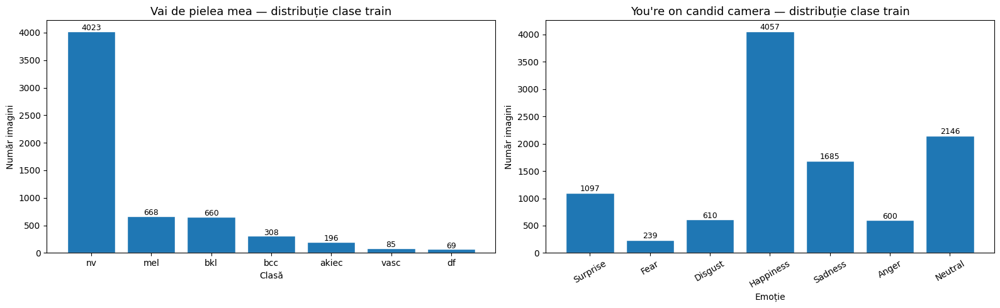

Grafic salvat în: /kaggle/working/artifacts/distributie_clase_train.png


In [43]:
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)

MOLE_CLASS_NAMES = {
    "akiec": "Bowen disease",
    "bcc": "Carcinom bazocelular",
    "bkl": "Keratoză benignă",
    "df": "Dermatofibrom",
    "mel": "Melanom",
    "nv": "Nevi melanocitari",
    "vasc": "Leziuni vasculare",
}

FACE_CLASS_NAMES = {
    1: "Surprise",
    2: "Fear",
    3: "Disgust",
    4: "Happiness",
    5: "Sadness",
    6: "Anger",
    7: "Neutral",
}

MOLE_LABEL_COL = df_mole_train.columns[1]
FACE_LABEL_COL = df_face_train.columns[1]

print("Coloană label mole:", MOLE_LABEL_COL)
print("Coloană label face:", FACE_LABEL_COL)

mole_counts = df_mole_train[MOLE_LABEL_COL].value_counts()
face_counts = df_face_train[FACE_LABEL_COL].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(
    mole_counts.index.astype(str),
    mole_counts.values,
    edgecolor="white"
)

axes[0].set_title("Vai de pielea mea — distribuție clase train", fontsize=13)
axes[0].set_xlabel("Clasă")
axes[0].set_ylabel("Număr imagini")

for i, value in enumerate(mole_counts.values):
    axes[0].text(i, value + 20, str(value), ha="center", fontsize=9)

face_labels = []

for cls in face_counts.index:
    cls_int = int(cls)
    face_labels.append(FACE_CLASS_NAMES.get(cls_int, str(cls_int)))

axes[1].bar(
    face_labels,
    face_counts.values,
    edgecolor="white"
)

axes[1].set_title("You're on candid camera — distribuție clase train", fontsize=13)
axes[1].set_xlabel("Emoție")
axes[1].set_ylabel("Număr imagini")
axes[1].tick_params(axis="x", rotation=30)

for i, value in enumerate(face_counts.values):
    axes[1].text(i, value + 30, str(value), ha="center", fontsize=9)

plt.tight_layout()

output_path = ARTIFACTS_DIR / "distributie_clase_train.png"
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("Grafic salvat în:", output_path)

In [44]:
def collect_image_sizes(root_dir: Path, max_images: int = 100) -> pd.DataFrame:
    """
    Citește dimensiunile pentru cel mult max_images imagini dintr-un folder.
    Returnează un DataFrame cu lățime, înălțime și cale.
    """
    extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"]
    image_paths = []

    for pattern in extensions:
        image_paths.extend(root_dir.rglob(pattern))

    image_paths = image_paths[:max_images]

    records = []

    for image_path in image_paths:
        try:
            with Image.open(image_path) as img:
                width, height = img.size

            records.append({
                "path": str(image_path),
                "width": width,
                "height": height,
            })

        except Exception as err:
            print(f"Nu pot citi imaginea {image_path}: {err}")

    return pd.DataFrame(records)


mole_size_df = collect_image_sizes(MOLE_TRAIN_DIR, max_images=100)

face_train_image_dir = FACE_DATASET_DIR / "train"

if not face_train_image_dir.exists():
    face_train_image_dir = FACE_DATASET_DIR

face_size_df = collect_image_sizes(face_train_image_dir, max_images=100)


print("=== VAI DE PIELEA MEA — dimensiuni imagini train ===")
display(mole_size_df[["width", "height"]].describe().round(2))

print("\n=== YOU'RE ON CANDID CAMERA — dimensiuni imagini train ===")
display(face_size_df[["width", "height"]].describe().round(2))


size_summary = {
    "mole": mole_size_df[["width", "height"]].describe().round(2).to_dict(),
    "face": face_size_df[["width", "height"]].describe().round(2).to_dict(),
}

with open(ARTIFACTS_DIR / "image_size_summary.json", "w", encoding="utf-8") as f:
    json.dump(size_summary, f, indent=2, ensure_ascii=False)

print("\nSumarul dimensiunilor a fost salvat în:", ARTIFACTS_DIR / "image_size_summary.json")

=== VAI DE PIELEA MEA — dimensiuni imagini train ===


,width,height
count,100.0,100.0
mean,130.0,100.0
std,0.0,0.0
min,130.0,100.0
25%,130.0,100.0
50%,130.0,100.0
75%,130.0,100.0
max,130.0,100.0



=== YOU'RE ON CANDID CAMERA — dimensiuni imagini train ===


,width,height
count,100.0,100.0
mean,100.0,100.0
std,0.0,0.0
min,100.0,100.0
25%,100.0,100.0
50%,100.0,100.0
75%,100.0,100.0
max,100.0,100.0



Sumarul dimensiunilor a fost salvat în: /kaggle/working/artifacts/image_size_summary.json


In [45]:
def load_normalization_stats(json_path: Path) -> Tuple[List[float], List[float]]:
    """
    Încarcă mean/std din fișierul norm_stats.json.
    Acceptă mai multe variante posibile de chei: mean/means și std/stds.
    """
    with open(json_path, "r", encoding="utf-8") as file:
        stats = json.load(file)

    mean = stats["mean"] if "mean" in stats else stats["means"]
    std = stats["std"] if "std" in stats else stats["stds"]

    return mean, std


SKIN_MEAN = [0.7646, 0.5464, 0.5712]
SKIN_STD = [0.1410, 0.1532, 0.1706]

CAMERA_MEAN, CAMERA_STD = load_normalization_stats(FACE_NORM_STATS)


normalization_table = pd.DataFrame({
    "dataset": ["Vai de pielea mea", "You're on candid camera"],
    "mean_R": [SKIN_MEAN[0], CAMERA_MEAN[0]],
    "mean_G": [SKIN_MEAN[1], CAMERA_MEAN[1]],
    "mean_B": [SKIN_MEAN[2], CAMERA_MEAN[2]],
    "std_R": [SKIN_STD[0], CAMERA_STD[0]],
    "std_G": [SKIN_STD[1], CAMERA_STD[1]],
    "std_B": [SKIN_STD[2], CAMERA_STD[2]],
})

display(normalization_table)

normalization_table.to_csv(
    ARTIFACTS_DIR / "normalization_stats.csv",
    index=False
)

print("Statisticile de normalizare au fost salvate în:")
print(ARTIFACTS_DIR / "normalization_stats.csv")

,dataset,mean_R,mean_G,mean_B,std_R,std_G,std_B
0,Vai de pielea mea,0.764600,0.546400,0.571200,0.141000,0.153200,0.170600
1,You're on candid camera,0.575213,0.449723,0.401287,0.265329,0.242296,0.240685


Statisticile de normalizare au fost salvate în:
/kaggle/working/artifacts/normalization_stats.csv


In [46]:
def get_existing_image_path(root_dir: Path, value) -> Path:
    """
    Primește valoarea din CSV și încearcă să găsească imaginea reală.
    Merge pentru căi relative, nume de fișier sau id-uri simple.
    """
    value = str(value)
    candidate = root_dir / value

    if candidate.exists():
        return candidate

    candidate = root_dir / Path(value).name

    if candidate.exists():
        return candidate

    stem = Path(value).stem

    for ext in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
        matches = list(root_dir.rglob(stem + ext))
        if matches:
            return matches[0]

    matches = list(root_dir.rglob(Path(value).name))
    if matches:
        return matches[0]

    raise FileNotFoundError(f"Nu am găsit imaginea: {value}")


def class_name_for_plot(class_id, names_dict: dict) -> str:
    """
    Returnează numele clasei pentru titlul imaginii.
    """
    if class_id in names_dict:
        return names_dict[class_id]

    try:
        class_id_int = int(class_id)
        return names_dict.get(class_id_int, str(class_id))
    except Exception:
        return str(class_id)


def plot_original_images_grid(
    df: pd.DataFrame,
    image_root: Path,
    label_column: str,
    image_column: str,
    class_names: dict,
    title: str,
    output_filename: str,
    samples_per_class: int = 4
):
    """
    Afișează o grilă cu imagini originale:
    fiecare rând = o clasă,
    fiecare coloană = un exemplu din clasa respectivă.
    """
    classes = sorted(df[label_column].dropna().unique())

    fig, axes = plt.subplots(
        nrows=len(classes),
        ncols=samples_per_class,
        figsize=(samples_per_class * 2.6, len(classes) * 2.4)
    )

    if len(classes) == 1:
        axes = np.expand_dims(axes, axis=0)

    fig.suptitle(title, fontsize=15, y=1.01)

    for row_idx, class_id in enumerate(classes):
        class_df = df[df[label_column] == class_id]

        chosen_samples = class_df.sample(
            n=min(samples_per_class, len(class_df)),
            random_state=SEED
        )

        for col_idx in range(samples_per_class):
            ax = axes[row_idx, col_idx]
            ax.axis("off")

            if col_idx >= len(chosen_samples):
                continue

            row = chosen_samples.iloc[col_idx]
            img_path = get_existing_image_path(image_root, row[image_column])

            img = Image.open(img_path).convert("RGB")
            ax.imshow(img)

            readable_name = class_name_for_plot(class_id, class_names)
            ax.set_title(f"{class_id} — {readable_name}", fontsize=8)

    plt.tight_layout()

    save_path = ARTIFACTS_DIR / output_filename
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Figura a fost salvată în: {save_path}")

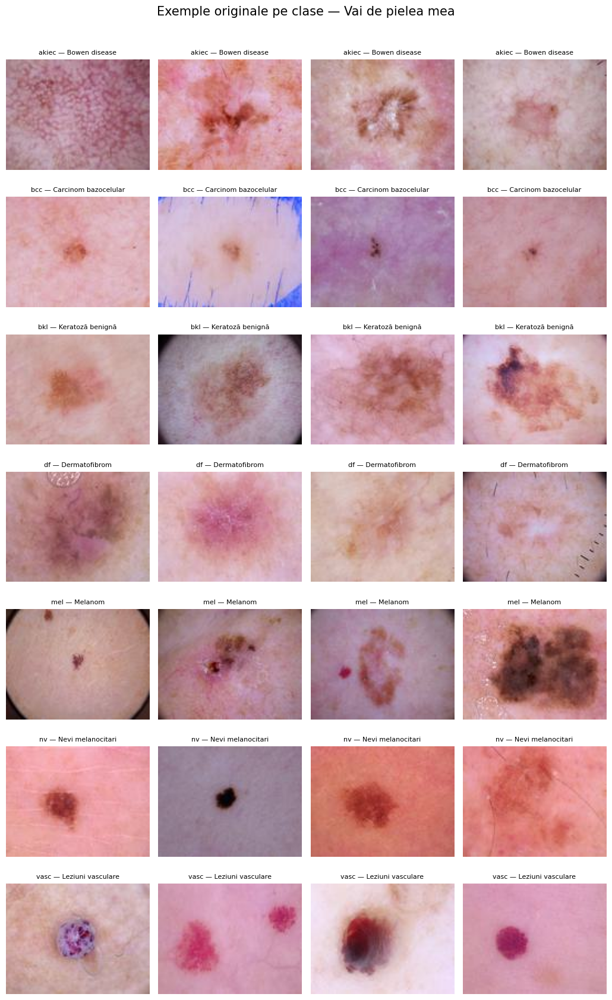

Figura a fost salvată în: /kaggle/working/artifacts/originale_mole.png


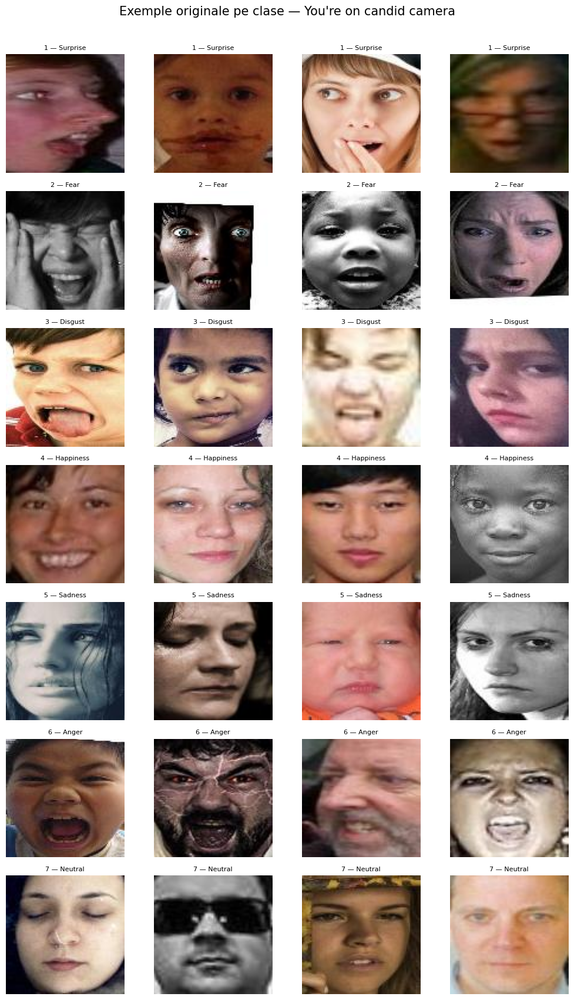

Figura a fost salvată în: /kaggle/working/artifacts/originale_faces.png


In [47]:
plot_original_images_grid(
    df=df_mole_train,
    image_root=MOLE_TRAIN_DIR,
    label_column=MOLE_LABEL_COL,
    image_column=MOLE_PATH_COL,
    class_names=MOLE_CLASS_NAMES,
    title="Exemple originale pe clase — Vai de pielea mea",
    output_filename="originale_mole.png",
    samples_per_class=4
)

plot_original_images_grid(
    df=df_face_train,
    image_root=FACE_DATASET_DIR,
    label_column=FACE_LABEL_COL,
    image_column=FACE_PATH_COL,
    class_names=FACE_CLASS_NAMES,
    title="Exemple originale pe clase — You're on candid camera",
    output_filename="originale_faces.png",
    samples_per_class=4
)

In [48]:
import cv2

mole_aug = A.Compose([
    A.Resize(128, 128),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Rotate(limit=180, border_mode=cv2.BORDER_REFLECT_101, p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.10, contrast_limit=0.10, p=0.6),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=8, val_shift_limit=8, p=0.3),
    A.GaussianBlur(blur_limit=(3, 3), p=0.15),
])


face_aug = A.Compose([
    A.Resize(128, 128),
    A.HorizontalFlip(p=0.5),
    A.Affine(
        scale=(0.90, 1.10),
        translate_percent=(-0.05, 0.05),
        rotate=(-12, 12),
        shear=(-4, 4),
        p=0.8
    ),
    A.RandomBrightnessContrast(brightness_limit=0.20, contrast_limit=0.20, p=0.6),
    A.GaussianBlur(blur_limit=(3, 3), p=0.15),
])

In [49]:
def plot_augmented_examples_by_class(
    df: pd.DataFrame,
    image_root: Path,
    label_column: str,
    image_column: str,
    class_names: dict,
    augmentation,
    title: str,
    output_filename: str,
    n_versions: int = 3
):
    classes = sorted(df[label_column].dropna().unique())

    fig, axes = plt.subplots(
        nrows=len(classes),
        ncols=n_versions + 1,
        figsize=((n_versions + 1) * 3.0, len(classes) * 2.7)
    )

    if len(classes) == 1:
        axes = np.expand_dims(axes, axis=0)

    fig.suptitle(title, fontsize=15, y=1.01)

    for row_idx, class_id in enumerate(classes):
        class_df = df[df[label_column] == class_id]
        selected_row = class_df.sample(n=1, random_state=SEED).iloc[0]

        img_path = get_existing_image_path(image_root, selected_row[image_column])
        original = np.array(Image.open(img_path).convert("RGB"))

        images = [original]

        for _ in range(n_versions):
            aug_img = augmentation(image=original)["image"]
            images.append(aug_img)

        for col_idx, img in enumerate(images):
            ax = axes[row_idx, col_idx]
            ax.imshow(img)
            ax.axis("off")

            if row_idx == 0:
                if col_idx == 0:
                    ax.set_title("Original", fontsize=10)
                else:
                    ax.set_title(f"Augmentare {col_idx}", fontsize=10)

            if col_idx == 0:
                label_text = class_name_for_plot(class_id, class_names)
                ax.set_ylabel(
                    f"{class_id}\n{label_text}",
                    rotation=0,
                    labelpad=55,
                    va="center",
                    fontsize=9
                )

    plt.tight_layout()

    save_path = ARTIFACTS_DIR / output_filename
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Figura a fost salvată în: {save_path}")

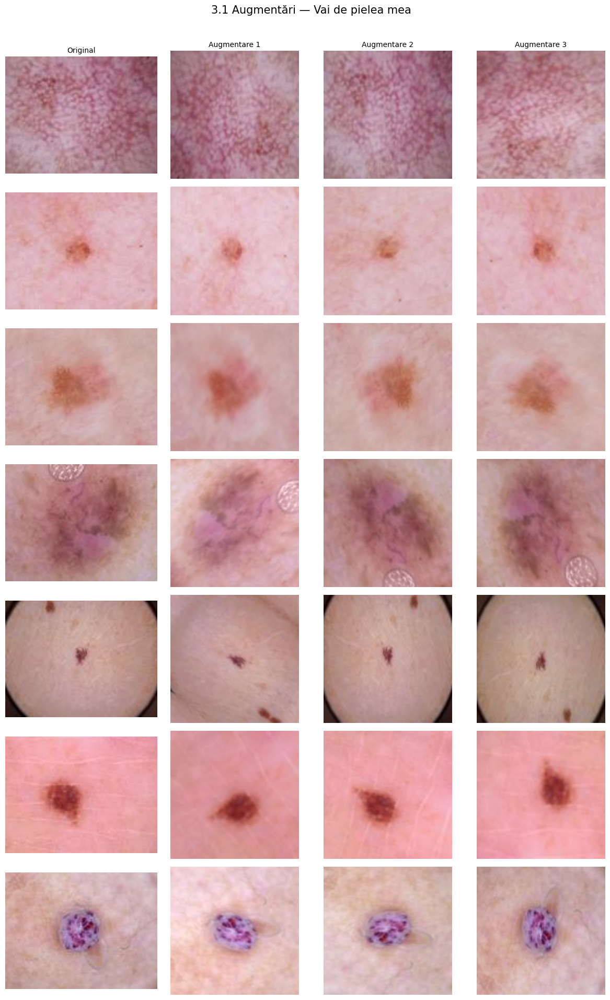

Figura a fost salvată în: /kaggle/working/artifacts/augmentari_mole.png


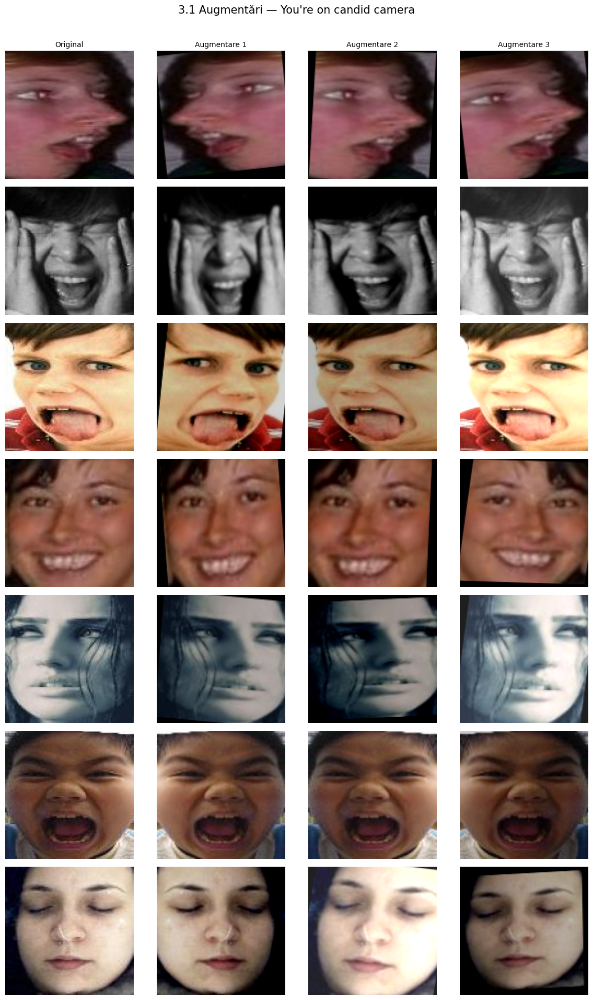

Figura a fost salvată în: /kaggle/working/artifacts/augmentari_faces.png


In [50]:
plot_augmented_examples_by_class(
    df=df_mole_train,
    image_root=MOLE_TRAIN_DIR,
    label_column=MOLE_LABEL_COL,
    image_column=MOLE_PATH_COL,
    class_names=MOLE_CLASS_NAMES,
    augmentation=mole_aug,
    title="3.1 Augmentări — Vai de pielea mea",
    output_filename="augmentari_mole.png",
    n_versions=3
)

plot_augmented_examples_by_class(
    df=df_face_train,
    image_root=FACE_DATASET_DIR,
    label_column=FACE_LABEL_COL,
    image_column=FACE_PATH_COL,
    class_names=FACE_CLASS_NAMES,
    augmentation=face_aug,
    title="3.1 Augmentări — You're on candid camera",
    output_filename="augmentari_faces.png",
    n_versions=3
)

In [51]:
class ImageCSVDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        image_root: Path,
        image_column: str,
        label_column: str,
        class_to_idx: dict,
        transform=None
    ):
        self.df = df.reset_index(drop=True)
        self.image_root = image_root
        self.image_column = image_column
        self.label_column = label_column
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = get_existing_image_path(
            self.image_root,
            row[self.image_column]
        )

        image = np.array(Image.open(img_path).convert("RGB"))

        if self.transform is not None:
            image = self.transform(image=image)["image"]

        label_raw = str(row[self.label_column])
        label = self.class_to_idx[label_raw]

        return image, label

In [52]:
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def build_image_index_fast(root_dirs):
    index = {}

    for root in root_dirs:
        root = Path(root)

        if not root.exists():
            continue

        for path in root.rglob("*"):
            if path.is_file() and path.suffix.lower() in IMG_EXTENSIONS:
                index[path.name] = path
                index[path.stem] = path

                try:
                    index[str(path.relative_to(root))] = path
                except Exception:
                    pass

    return index


def resolve_image_path_fast(value, root_dirs, image_index):
    value = str(value)
    value_path = Path(value)

    if value_path.is_absolute() and value_path.exists():
        return value_path

    for root in root_dirs:
        root = Path(root)

        candidate = root / value
        if candidate.exists():
            return candidate

        candidate = root / value_path.name
        if candidate.exists():
            return candidate

    for key in [value, value_path.name, value_path.stem]:
        if key in image_index:
            return image_index[key]

    raise FileNotFoundError(f"Nu am găsit imaginea: {value}")


class FastImageCSVDataset(Dataset):
    def __init__(
        self,
        df,
        root_dirs,
        image_column,
        label_column,
        class_to_idx,
        transform=None
    ):
        self.df = df.reset_index(drop=True)
        self.root_dirs = [Path(r) for r in root_dirs]
        self.image_column = image_column
        self.label_column = label_column
        self.class_to_idx = class_to_idx
        self.transform = transform

        self.image_index = build_image_index_fast(self.root_dirs)
        self.samples = []

        for _, row in self.df.iterrows():
            img_path = resolve_image_path_fast(
                row[self.image_column],
                self.root_dirs,
                self.image_index
            )

            label = self.class_to_idx[str(row[self.label_column])]
            self.samples.append((img_path, label))

        print(f"Dataset creat: {len(self.samples)} imagini")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]

        image = np.array(Image.open(img_path).convert("RGB"))

        if self.transform is not None:
            image = self.transform(image=image)["image"]

        return image, label

In [53]:
MLP_IMAGE_SIZE = 48
BATCH_SIZE = 128
MLP_EPOCHS = 5

def make_basic_transform(mean, std, image_size=48):
    return A.Compose([
        A.Resize(image_size, image_size),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])


skin_mlp_transform = make_basic_transform(SKIN_MEAN, SKIN_STD, MLP_IMAGE_SIZE)
camera_mlp_transform = make_basic_transform(CAMERA_MEAN, CAMERA_STD, MLP_IMAGE_SIZE)


skin_class_to_idx = {
    cls: idx
    for idx, cls in enumerate(sorted(df_mole_train[MOLE_LABEL_COL].astype(str).unique()))
}

camera_class_to_idx = {
    cls: idx
    for idx, cls in enumerate(sorted(df_face_train[FACE_LABEL_COL].astype(str).unique()))
}

skin_idx_to_class = {v: k for k, v in skin_class_to_idx.items()}
camera_idx_to_class = {v: k for k, v in camera_class_to_idx.items()}


skin_train_mlp_ds = FastImageCSVDataset(
    df=df_mole_train,
    root_dirs=[MOLE_TRAIN_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=skin_mlp_transform
)

skin_test_mlp_ds = FastImageCSVDataset(
    df=df_mole_test,
    root_dirs=[MOLE_TEST_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=skin_mlp_transform
)

camera_train_mlp_ds = FastImageCSVDataset(
    df=df_face_train,
    root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
    image_column=FACE_PATH_COL,
    label_column=FACE_LABEL_COL,
    class_to_idx=camera_class_to_idx,
    transform=camera_mlp_transform
)

camera_test_mlp_ds = FastImageCSVDataset(
    df=df_face_test,
    root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
    image_column=FACE_PATH_COL,
    label_column=FACE_LABEL_COL,
    class_to_idx=camera_class_to_idx,
    transform=camera_mlp_transform
)


skin_train_mlp_loader = DataLoader(
    skin_train_mlp_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

skin_test_mlp_loader = DataLoader(
    skin_test_mlp_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

camera_train_mlp_loader = DataLoader(
    camera_train_mlp_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

camera_test_mlp_loader = DataLoader(
    camera_test_mlp_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)


print("Clase skin:", skin_class_to_idx)
print("Clase camera:", camera_class_to_idx)

xb, yb = next(iter(skin_train_mlp_loader))
print("Batch skin:", xb.shape, yb.shape)

xb, yb = next(iter(camera_train_mlp_loader))
print("Batch camera:", xb.shape, yb.shape)

Dataset creat: 6009 imagini
Dataset creat: 2003 imagini
Dataset creat: 10434 imagini
Dataset creat: 1837 imagini
Clase skin: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Clase camera: {'1': 0, '2': 1, '3': 2, '4': 3, '5': 4, '6': 5, '7': 6}
Batch skin: torch.Size([128, 3, 48, 48]) torch.Size([128])
Batch camera: torch.Size([128, 3, 48, 48]) torch.Size([128])


In [54]:
class MLPClassifier(nn.Module):
    def __init__(
        self,
        num_classes: int,
        image_size: int = 48,
        use_dropout: bool = True,
        dropout_p: float = 0.30,
        use_batchnorm: bool = True
    ):
        super().__init__()

        input_dim = 3 * image_size * image_size

        layers = [
            nn.Flatten(),

            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512) if use_batchnorm else nn.Identity(),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p) if use_dropout else nn.Identity(),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256) if use_batchnorm else nn.Identity(),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p) if use_dropout else nn.Identity(),

            nn.Linear(256, num_classes)
        ]

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [55]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with amp_autocast():
            logits = model(images)
            loss = criterion(logits, labels)

        if USE_AMP:
            AMP_SCALER.scale(loss).backward()
            AMP_SCALER.step(optimizer)
            AMP_SCALER.update()
        else:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    return {
        "loss": avg_loss,
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "f1_micro": f1_score(all_labels, all_preds, average="micro", zero_division=0),
    }


@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with amp_autocast():
            logits = model(images)
            loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    return {
        "loss": avg_loss,
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "f1_micro": f1_score(all_labels, all_preds, average="micro", zero_division=0),
        "labels": np.array(all_labels),
        "preds": np.array(all_preds),
    }

In [56]:
def plot_training_curves(history: pd.DataFrame, title: str, output_name: str):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["val_loss"], label="test")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epocă")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history["epoch"], history["train_f1_macro"], label="train")
    axes[1].plot(history["epoch"], history["val_f1_macro"], label="test")
    axes[1].set_title("F1-macro")
    axes[1].set_xlabel("Epocă")
    axes[1].set_ylabel("F1-macro")
    axes[1].legend()

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()

    save_path = ARTIFACTS_DIR / output_name
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Curbe salvate în:", save_path)


def plot_confusion_matrix_simple(y_true, y_pred, class_labels, title, output_name):
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm)

    ax.set_title(title)
    ax.set_xlabel("Predicție")
    ax.set_ylabel("Etichetă reală")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))

    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    plt.colorbar(im, ax=ax)
    plt.tight_layout()

    save_path = ARTIFACTS_DIR / output_name
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Matrice salvată în:", save_path)


def run_mlp_experiment(
    experiment_name: str,
    train_loader,
    test_loader,
    num_classes: int,
    class_labels: List[str],
    use_dropout: bool,
    epochs: int = 10,
    lr: float = 1e-3,
    weight_decay: float = 1e-4
):
    print(f"\n=== Experiment: {experiment_name} ===")

    model = MLPClassifier(
        num_classes=num_classes,
        image_size=MLP_IMAGE_SIZE,
        use_dropout=use_dropout,
        dropout_p=0.35,
        use_batchnorm=True
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.StepLR(
        optimizer,
        step_size=max(epochs // 2, 1),
        gamma=0.5
    )

    history_rows = []
    best_f1 = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        train_metrics = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=DEVICE
        )

        val_metrics = evaluate_model(
            model=model,
            loader=test_loader,
            criterion=criterion,
            device=DEVICE
        )

        scheduler.step()

        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_f1_macro": train_metrics["f1_macro"],
            "train_f1_micro": train_metrics["f1_micro"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_f1_micro": val_metrics["f1_micro"],
            "lr": optimizer.param_groups[0]["lr"],
        }

        history_rows.append(row)

        print(
            f"Epoca {epoch:02d}/{epochs} | "
            f"train loss={row['train_loss']:.4f}, train F1={row['train_f1_macro']:.4f} | "
            f"test loss={row['val_loss']:.4f}, test F1={row['val_f1_macro']:.4f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    final_metrics = evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=DEVICE
    )

    history = pd.DataFrame(history_rows)

    safe_name = experiment_name.replace(" ", "_").replace("/", "_").lower()

    history.to_csv(
        ARTIFACTS_DIR / f"{safe_name}_history.csv",
        index=False
    )

    plot_training_curves(
        history=history,
        title=f"Curbe train/test — {experiment_name}",
        output_name=f"{safe_name}_curves.png"
    )

    plot_confusion_matrix_simple(
        y_true=final_metrics["labels"],
        y_pred=final_metrics["preds"],
        class_labels=class_labels,
        title=f"Matrice de confuzie — {experiment_name}",
        output_name=f"{safe_name}_confusion_matrix.png"
    )

    torch.save(
        model.state_dict(),
        ARTIFACTS_DIR / f"{safe_name}_best_model.pt"
    )

    result = {
        "experiment": experiment_name,
        "use_dropout": use_dropout,
        "best_val_f1_macro": best_f1,
        "final_accuracy": final_metrics["accuracy"],
        "final_f1_macro": final_metrics["f1_macro"],
        "final_f1_micro": final_metrics["f1_micro"],
        "final_loss": final_metrics["loss"],
    }

    print("\nRezultat final:")
    print(result)

    with open(ARTIFACTS_DIR / f"{safe_name}_results.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)

    return model, history, result


=== Experiment: MLP skin cu dropout ===
Epoca 01/5 | train loss=0.9874, train F1=0.2053 | test loss=0.8696, test F1=0.2080
Epoca 02/5 | train loss=0.8189, train F1=0.2603 | test loss=0.8339, test F1=0.2833
Epoca 03/5 | train loss=0.7882, train F1=0.2882 | test loss=0.8122, test F1=0.3007
Epoca 04/5 | train loss=0.7576, train F1=0.3033 | test loss=0.7965, test F1=0.3375
Epoca 05/5 | train loss=0.7331, train F1=0.3313 | test loss=0.7836, test F1=0.3406


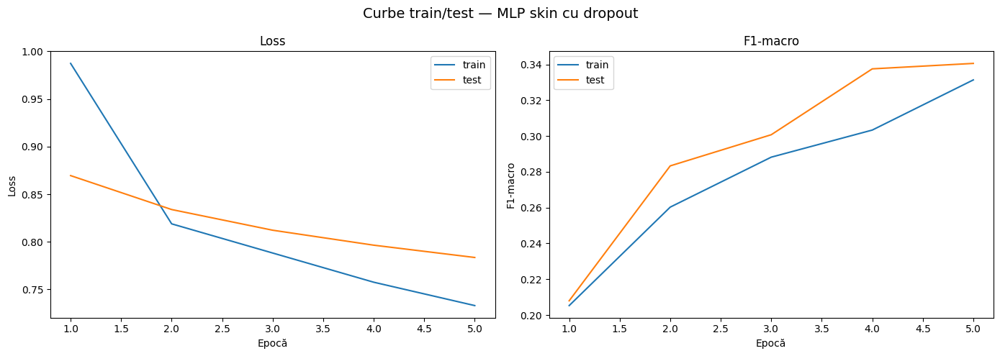

Curbe salvate în: /kaggle/working/artifacts/mlp_skin_cu_dropout_curves.png


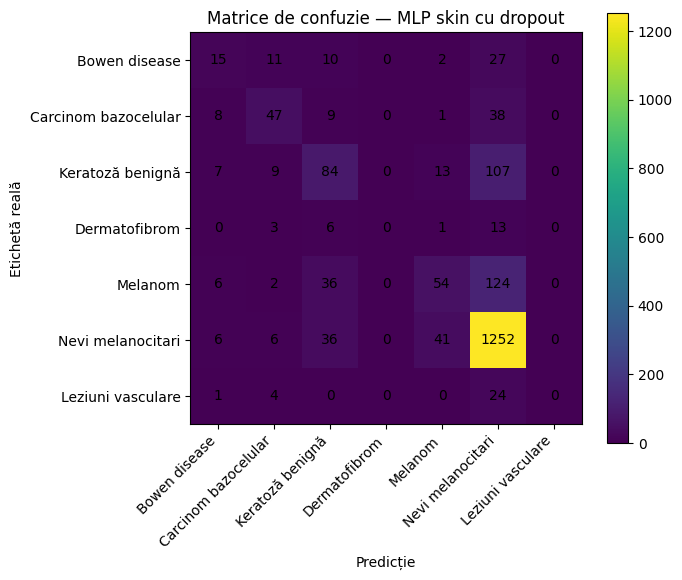

Matrice salvată în: /kaggle/working/artifacts/mlp_skin_cu_dropout_confusion_matrix.png

Rezultat final:
{'experiment': 'MLP skin cu dropout', 'use_dropout': True, 'best_val_f1_macro': 0.34056680012816415, 'final_accuracy': 0.7249126310534199, 'final_f1_macro': 0.34056680012816415, 'final_f1_micro': 0.7249126310534199, 'final_loss': 0.7835668791727132}


{'experiment': 'MLP skin cu dropout',
 'use_dropout': True,
 'best_val_f1_macro': 0.34056680012816415,
 'final_accuracy': 0.7249126310534199,
 'final_f1_macro': 0.34056680012816415,
 'final_f1_micro': 0.7249126310534199,
 'final_loss': 0.7835668791727132}

In [57]:
MLP_EPOCHS = 5

skin_class_labels = [
    MOLE_CLASS_NAMES.get(skin_idx_to_class[i], skin_idx_to_class[i])
    for i in range(len(skin_idx_to_class))
]

mlp_skin_dropout_model, mlp_skin_dropout_history, mlp_skin_dropout_result = run_mlp_experiment(
    experiment_name="MLP skin cu dropout",
    train_loader=skin_train_mlp_loader,
    test_loader=skin_test_mlp_loader,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    use_dropout=True,
    epochs=MLP_EPOCHS
)

mlp_skin_dropout_result

In [58]:
CAMERA_MLP_SUBSET_SIZE = 3500   # poți crește la 5000 dacă merge repede
BATCH_SIZE_FAST = 256

camera_subset_indices = (
    df_face_train
    .groupby(FACE_LABEL_COL, group_keys=False)
    .apply(lambda x: x.sample(
        n=min(len(x), max(1, int(CAMERA_MLP_SUBSET_SIZE * len(x) / len(df_face_train)))),
        random_state=SEED
    ))
    .index
    .tolist()
)

camera_train_mlp_subset = Subset(camera_train_mlp_ds, camera_subset_indices)

camera_train_mlp_loader_fast = DataLoader(
    camera_train_mlp_subset,
    batch_size=BATCH_SIZE_FAST,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

camera_test_mlp_loader_fast = DataLoader(
    camera_test_mlp_ds,
    batch_size=BATCH_SIZE_FAST,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("Camera train original:", len(camera_train_mlp_ds))
print("Camera train subset:", len(camera_train_mlp_subset))

Camera train original: 10434
Camera train subset: 3496


In [59]:
camera_class_labels = [
    FACE_CLASS_NAMES.get(int(camera_idx_to_class[i]), str(camera_idx_to_class[i]))
    for i in range(len(camera_idx_to_class))
]

print(camera_class_labels)

['Surprise', 'Fear', 'Disgust', 'Happiness', 'Sadness', 'Anger', 'Neutral']



=== Experiment: MLP camera cu dropout ===
Epoca 01/4 | train loss=1.5927, train F1=0.2231 | test loss=1.4934, test F1=0.2251
Epoca 02/4 | train loss=1.2869, train F1=0.2525 | test loss=1.3093, test F1=0.2800
Epoca 03/4 | train loss=1.1894, train F1=0.2981 | test loss=1.2661, test F1=0.2972
Epoca 04/4 | train loss=1.1078, train F1=0.3446 | test loss=1.2218, test F1=0.3236


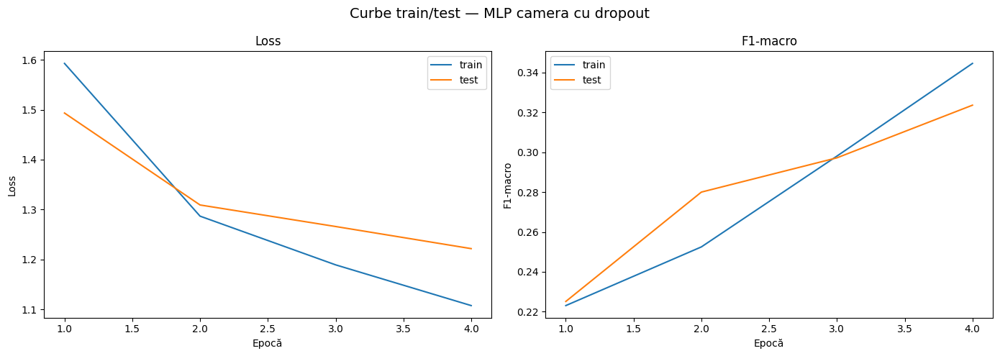

Curbe salvate în: /kaggle/working/artifacts/mlp_camera_cu_dropout_curves.png


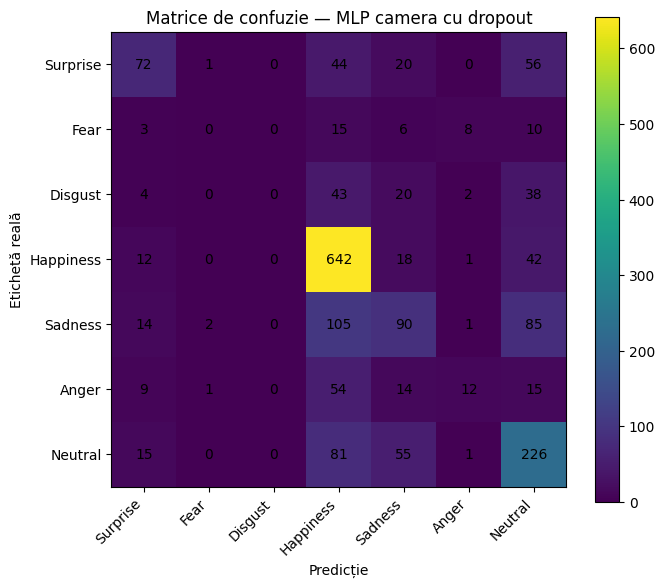

Matrice salvată în: /kaggle/working/artifacts/mlp_camera_cu_dropout_confusion_matrix.png

Rezultat final:
{'experiment': 'MLP camera cu dropout', 'use_dropout': True, 'best_val_f1_macro': 0.3236396536287788, 'final_accuracy': 0.5672291780076211, 'final_f1_macro': 0.3236396536287788, 'final_f1_micro': 0.5672291780076211, 'final_loss': 1.2218429564650966}


{'experiment': 'MLP camera cu dropout',
 'use_dropout': True,
 'best_val_f1_macro': 0.3236396536287788,
 'final_accuracy': 0.5672291780076211,
 'final_f1_macro': 0.3236396536287788,
 'final_f1_micro': 0.5672291780076211,
 'final_loss': 1.2218429564650966}

In [60]:

MLP_EPOCHS = 4

mlp_camera_dropout_model, mlp_camera_dropout_history, mlp_camera_dropout_result = run_mlp_experiment(
    experiment_name="MLP camera cu dropout",
    train_loader=camera_train_mlp_loader_fast,
    test_loader=camera_test_mlp_loader,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    use_dropout=True,
    epochs=MLP_EPOCHS
)

mlp_camera_dropout_result


=== Experiment: MLP camera fara dropout ===
Epoca 01/5 | train loss=1.4419, train F1=0.2328 | test loss=1.3955, test F1=0.2738
Epoca 02/5 | train loss=1.1477, train F1=0.3253 | test loss=1.2646, test F1=0.3067
Epoca 03/5 | train loss=1.0045, train F1=0.4304 | test loss=1.2184, test F1=0.3346
Epoca 04/5 | train loss=0.9084, train F1=0.4813 | test loss=1.1582, test F1=0.3736
Epoca 05/5 | train loss=0.8196, train F1=0.5551 | test loss=1.1184, test F1=0.4090


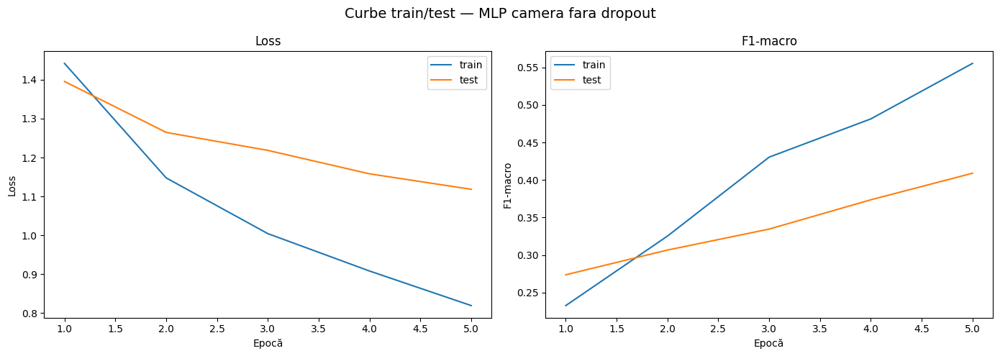

Curbe salvate în: /kaggle/working/artifacts/mlp_camera_fara_dropout_curves.png


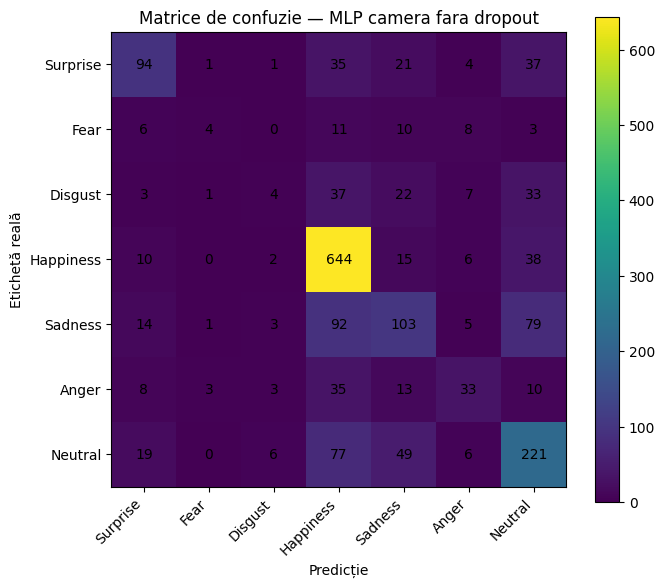

Matrice salvată în: /kaggle/working/artifacts/mlp_camera_fara_dropout_confusion_matrix.png

Rezultat final:
{'experiment': 'MLP camera fara dropout', 'use_dropout': False, 'best_val_f1_macro': 0.40897272542763524, 'final_accuracy': 0.6004354926510616, 'final_f1_macro': 0.40897272542763524, 'final_f1_micro': 0.6004354926510616, 'final_loss': 1.1184331015782571}


{'experiment': 'MLP camera fara dropout',
 'use_dropout': False,
 'best_val_f1_macro': 0.40897272542763524,
 'final_accuracy': 0.6004354926510616,
 'final_f1_macro': 0.40897272542763524,
 'final_f1_micro': 0.6004354926510616,
 'final_loss': 1.1184331015782571}

In [61]:

MLP_EPOCHS = 5

mlp_camera_no_dropout_model, mlp_camera_no_dropout_history, mlp_camera_no_dropout_result = run_mlp_experiment(
    experiment_name="MLP camera fara dropout",
    train_loader=camera_train_mlp_loader_fast,
    test_loader=camera_test_mlp_loader,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    use_dropout=False,
    epochs=MLP_EPOCHS
)

mlp_camera_no_dropout_result


=== Experiment: MLP skin fara dropout ===
Epoca 01/5 | train loss=0.9480, train F1=0.2283 | test loss=0.8813, test F1=0.2282
Epoca 02/5 | train loss=0.7820, train F1=0.2944 | test loss=0.8294, test F1=0.3167
Epoca 03/5 | train loss=0.7242, train F1=0.3267 | test loss=0.7935, test F1=0.3467
Epoca 04/5 | train loss=0.6789, train F1=0.3549 | test loss=0.7933, test F1=0.3419
Epoca 05/5 | train loss=0.6259, train F1=0.4323 | test loss=0.7626, test F1=0.3652


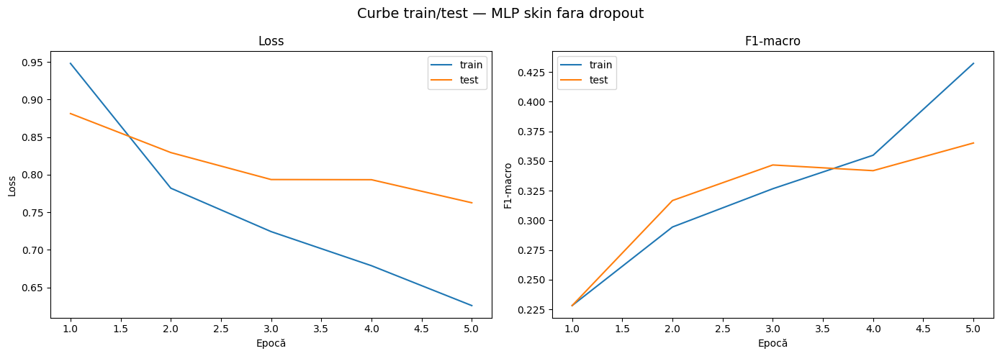

Curbe salvate în: /kaggle/working/artifacts/mlp_skin_fara_dropout_curves.png


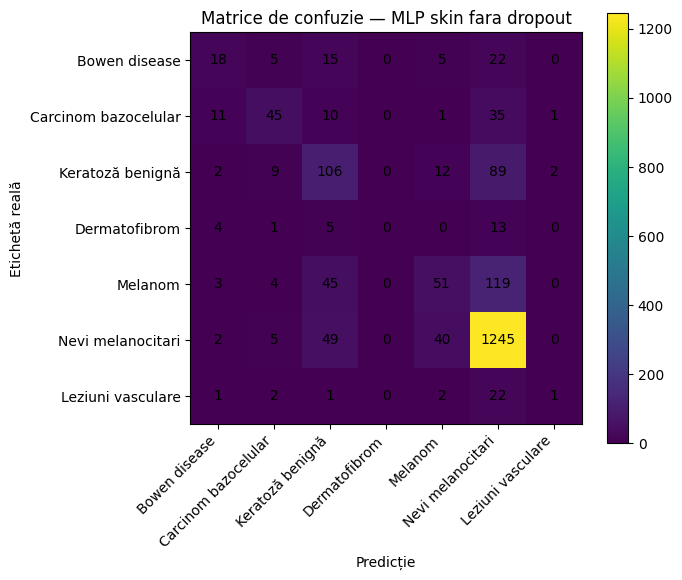

Matrice salvată în: /kaggle/working/artifacts/mlp_skin_fara_dropout_confusion_matrix.png

Rezultat final:
{'experiment': 'MLP skin fara dropout', 'use_dropout': False, 'best_val_f1_macro': 0.3652326813378593, 'final_accuracy': 0.7319021467798302, 'final_f1_macro': 0.3652326813378593, 'final_f1_micro': 0.7319021467798302, 'final_loss': 0.7626134914216315}


{'experiment': 'MLP skin fara dropout',
 'use_dropout': False,
 'best_val_f1_macro': 0.3652326813378593,
 'final_accuracy': 0.7319021467798302,
 'final_f1_macro': 0.3652326813378593,
 'final_f1_micro': 0.7319021467798302,
 'final_loss': 0.7626134914216315}

In [62]:
MLP_EPOCHS = 5

mlp_skin_no_dropout_model, mlp_skin_no_dropout_history, mlp_skin_no_dropout_result = run_mlp_experiment(
    experiment_name="MLP skin fara dropout",
    train_loader=skin_train_mlp_loader,
    test_loader=skin_test_mlp_loader,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    use_dropout=False,
    epochs=MLP_EPOCHS
)

mlp_skin_no_dropout_result

In [63]:
CNN_IMAGE_SIZE = 64
CNN_BATCH_SIZE = 256
CNN_NUM_WORKERS = NUM_WORKERS

def make_cnn_transform(mean, std, image_size=64):
    return A.Compose([
        A.Resize(image_size, image_size),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])


skin_cnn_transform = make_cnn_transform(SKIN_MEAN, SKIN_STD, CNN_IMAGE_SIZE)
camera_cnn_transform = make_cnn_transform(CAMERA_MEAN, CAMERA_STD, CNN_IMAGE_SIZE)


skin_train_cnn_ds = FastImageCSVDataset(
    df=df_mole_train,
    root_dirs=[MOLE_TRAIN_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=skin_cnn_transform
)

skin_test_cnn_ds = FastImageCSVDataset(
    df=df_mole_test,
    root_dirs=[MOLE_TEST_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=skin_cnn_transform
)

camera_train_cnn_ds = FastImageCSVDataset(
    df=df_face_train,
    root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
    image_column=FACE_PATH_COL,
    label_column=FACE_LABEL_COL,
    class_to_idx=camera_class_to_idx,
    transform=camera_cnn_transform
)

camera_test_cnn_ds = FastImageCSVDataset(
    df=df_face_test,
    root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
    image_column=FACE_PATH_COL,
    label_column=FACE_LABEL_COL,
    class_to_idx=camera_class_to_idx,
    transform=camera_cnn_transform
)


skin_train_cnn_loader = DataLoader(
    skin_train_cnn_ds,
    batch_size=CNN_BATCH_SIZE,
    shuffle=True,
    num_workers=CNN_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

skin_test_cnn_loader = DataLoader(
    skin_test_cnn_ds,
    batch_size=CNN_BATCH_SIZE,
    shuffle=False,
    num_workers=CNN_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

camera_train_cnn_loader = DataLoader(
    camera_train_cnn_ds,
    batch_size=CNN_BATCH_SIZE,
    shuffle=True,
    num_workers=CNN_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

camera_test_cnn_loader = DataLoader(
    camera_test_cnn_ds,
    batch_size=CNN_BATCH_SIZE,
    shuffle=False,
    num_workers=CNN_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("Device:", DEVICE)

xb, yb = next(iter(camera_train_cnn_loader))
print("Camera CNN batch:", xb.shape, yb.shape)

xb, yb = next(iter(skin_train_cnn_loader))
print("Skin CNN batch:", xb.shape, yb.shape)

Dataset creat: 6009 imagini
Dataset creat: 2003 imagini
Dataset creat: 10434 imagini
Dataset creat: 1837 imagini
Device: cuda
Camera CNN batch: torch.Size([256, 3, 64, 64]) torch.Size([256])
Skin CNN batch: torch.Size([256, 3, 64, 64]) torch.Size([256])


In [64]:
class SimpleCNNClassifier(nn.Module):
    def __init__(
        self,
        num_classes: int,
        first_kernel_size: int = 3,
        use_batchnorm: bool = True,
        dropout_p: float = 0.25
    ):
        super().__init__()

        padding_first = first_kernel_size // 2

        def conv_block(in_channels, out_channels, kernel_size=3, padding=1):
            layers = [
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=kernel_size,
                    padding=padding,
                    bias=not use_batchnorm
                )
            ]

            if use_batchnorm:
                layers.append(nn.BatchNorm2d(out_channels))

            layers.append(nn.ReLU(inplace=True))
            layers.append(nn.MaxPool2d(kernel_size=2))

            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            conv_block(3, 16, kernel_size=first_kernel_size, padding=padding_first),
            conv_block(16, 32),
            conv_block(32, 64),
            conv_block(64, 128),
        )

    
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

      
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout_p),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x



test_cnn = SimpleCNNClassifier(num_classes=7, first_kernel_size=3).to(DEVICE)
dummy = torch.randn(4, 3, CNN_IMAGE_SIZE, CNN_IMAGE_SIZE).to(DEVICE)

with torch.no_grad():
    out = test_cnn(dummy)

print("Output shape:", out.shape)

Output shape: torch.Size([4, 7])


In [65]:
def run_cnn_experiment(
    experiment_name: str,
    train_loader,
    test_loader,
    num_classes: int,
    class_labels: List[str],
    first_kernel_size: int = 3,
    use_batchnorm: bool = True,
    epochs: int = 5,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    class_weights=None,
):
    """Antrenează, evaluează și salvează un CNN pentru un experiment.

    Funcția este folosită de toate celulele CNN: baseline, ablație BatchNorm,
    ablație augmentări și WeightedRandomSampler.
    """
    print(f"\n=== Experiment CNN: {experiment_name} ===")

    model = SimpleCNNClassifier(
        num_classes=num_classes,
        first_kernel_size=first_kernel_size,
        use_batchnorm=use_batchnorm,
        dropout_p=0.25,
    ).to(DEVICE)

    if class_weights is not None:
        if not torch.is_tensor(class_weights):
            class_weights = torch.tensor(class_weights, dtype=torch.float32)
        class_weights = class_weights.to(DEVICE)
        criterion = nn.CrossEntropyLoss(weight=class_weights)
    else:
        criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1,
    )

    history_rows = []
    best_f1 = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        train_metrics = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=DEVICE,
        )

        val_metrics = evaluate_model(
            model=model,
            loader=test_loader,
            criterion=criterion,
            device=DEVICE,
        )

        scheduler.step(val_metrics["f1_macro"])

        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_f1_macro": train_metrics["f1_macro"],
            "train_f1_micro": train_metrics["f1_micro"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_f1_micro": val_metrics["f1_micro"],
            "lr": optimizer.param_groups[0]["lr"],
        }
        history_rows.append(row)

        print(
            f"Epoca {epoch:02d}/{epochs} | "
            f"train loss={row['train_loss']:.4f}, train F1={row['train_f1_macro']:.4f} | "
            f"test loss={row['val_loss']:.4f}, test F1={row['val_f1_macro']:.4f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    final_metrics = evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=DEVICE,
    )

    history = pd.DataFrame(history_rows)
    safe_name = experiment_name.replace(" ", "_").replace("/", "_").lower()

    history.to_csv(
        ARTIFACTS_DIR / f"{safe_name}_history.csv",
        index=False,
    )

    plot_training_curves(
        history=history,
        title=f"Curbe train/test — {experiment_name}",
        output_name=f"{safe_name}_curves.png",
    )

    plot_confusion_matrix_simple(
        y_true=final_metrics["labels"],
        y_pred=final_metrics["preds"],
        class_labels=class_labels,
        title=f"Matrice de confuzie — {experiment_name}",
        output_name=f"{safe_name}_confusion_matrix.png",
    )

    torch.save(
        model.state_dict(),
        ARTIFACTS_DIR / f"{safe_name}_best_model.pt",
    )

    result = {
        "experiment": experiment_name,
        "model": "CNN",
        "first_kernel_size": first_kernel_size,
        "use_batchnorm": use_batchnorm,
        "best_val_f1_macro": best_f1,
        "final_accuracy": final_metrics["accuracy"],
        "final_f1_macro": final_metrics["f1_macro"],
        "final_f1_micro": final_metrics["f1_micro"],
        "final_loss": final_metrics["loss"],
    }

    print("\nRezultat final:")
    print(result)

    with open(ARTIFACTS_DIR / f"{safe_name}_results.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)

    return model, history, result


### 3.3 — CNN pe Vai de pielea mea

Rularea lungă duplicată a fost eliminată pentru Kaggle. Experimentul CNN skin cu BatchNorm este rulat mai jos o singură dată, cu `CNN_EPOCHS = 3`, ca să nu consume timp inutil.


=== Experiment CNN: CNN camera cu BatchNorm ===
Epoca 01/3 | train loss=1.5912, train F1=0.1414 | test loss=1.5862, test F1=0.0911
Epoca 02/3 | train loss=1.4605, train F1=0.1887 | test loss=1.4706, test F1=0.1636
Epoca 03/3 | train loss=1.3303, train F1=0.2534 | test loss=1.6426, test F1=0.1482


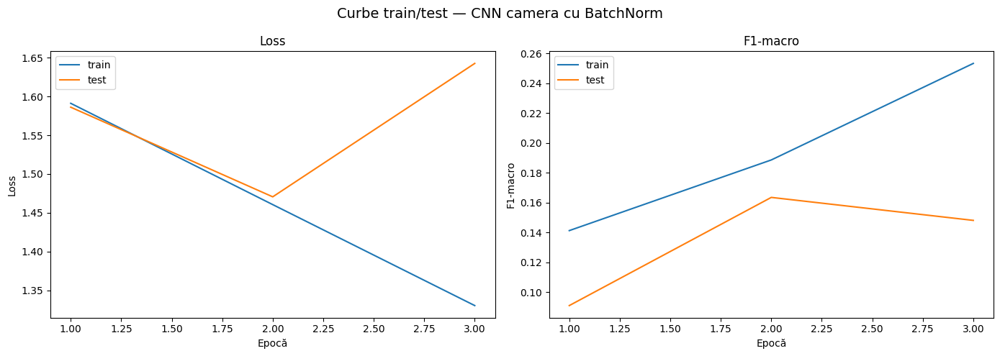

Curbe salvate în: /kaggle/working/artifacts/cnn_camera_cu_batchnorm_curves.png


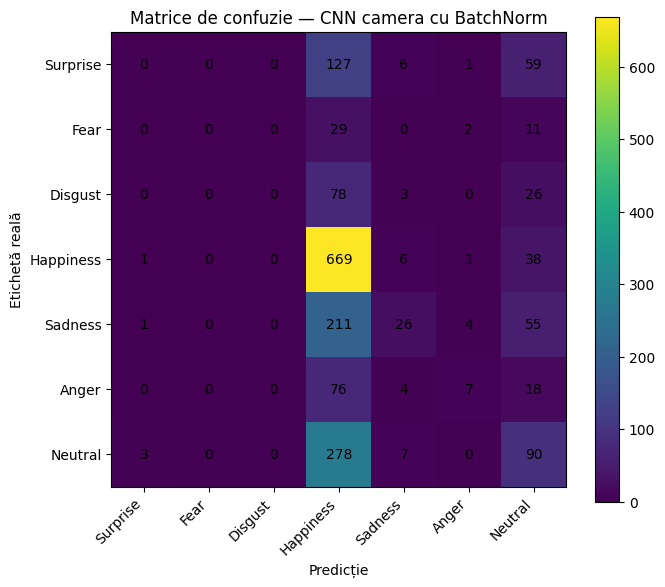

Matrice salvată în: /kaggle/working/artifacts/cnn_camera_cu_batchnorm_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN camera cu BatchNorm', 'model': 'CNN', 'first_kernel_size': 3, 'use_batchnorm': True, 'best_val_f1_macro': 0.16360692439319027, 'final_accuracy': 0.4311377245508982, 'final_f1_macro': 0.16360692439319027, 'final_f1_micro': 0.4311377245508982, 'final_loss': 1.4705665681955278}


{'experiment': 'CNN camera cu BatchNorm',
 'model': 'CNN',
 'first_kernel_size': 3,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.16360692439319027,
 'final_accuracy': 0.4311377245508982,
 'final_f1_macro': 0.16360692439319027,
 'final_f1_micro': 0.4311377245508982,
 'final_loss': 1.4705665681955278}

In [66]:
CNN_EPOCHS = 3

cnn_camera_model, cnn_camera_history, cnn_camera_result = run_cnn_experiment(
    experiment_name="CNN camera cu BatchNorm",
    train_loader=camera_train_cnn_loader,
    test_loader=camera_test_cnn_loader,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    first_kernel_size=3,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_camera_result


=== Experiment CNN: CNN skin cu BatchNorm ===
Epoca 01/3 | train loss=1.1648, train F1=0.1617 | test loss=1.1043, test F1=0.1146
Epoca 02/3 | train loss=0.8612, train F1=0.1855 | test loss=0.9365, test F1=0.1540
Epoca 03/3 | train loss=0.8209, train F1=0.2362 | test loss=0.8012, test F1=0.2706


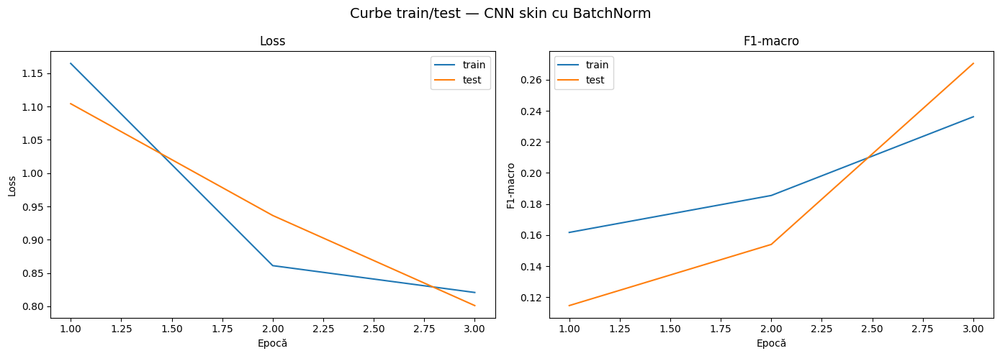

Curbe salvate în: /kaggle/working/artifacts/cnn_skin_cu_batchnorm_curves.png


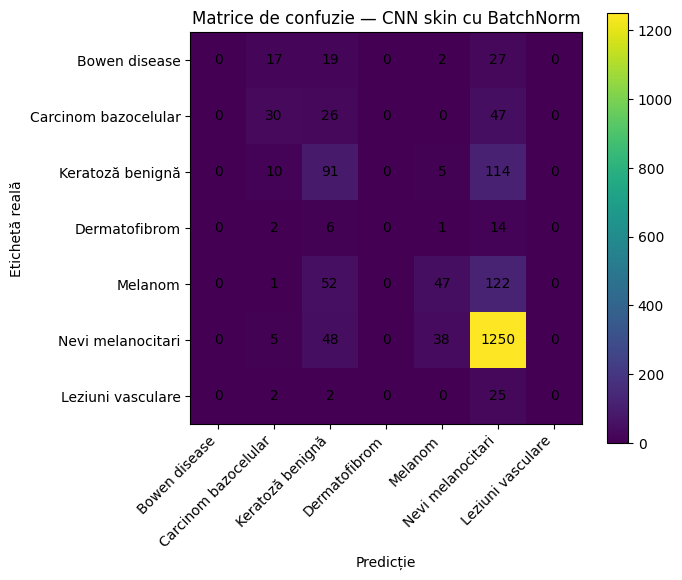

Matrice salvată în: /kaggle/working/artifacts/cnn_skin_cu_batchnorm_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN skin cu BatchNorm', 'model': 'CNN', 'first_kernel_size': 5, 'use_batchnorm': True, 'best_val_f1_macro': 0.27056219860686476, 'final_accuracy': 0.707938092860709, 'final_f1_macro': 0.27056219860686476, 'final_f1_micro': 0.707938092860709, 'final_loss': 0.8011937599389243}


{'experiment': 'CNN skin cu BatchNorm',
 'model': 'CNN',
 'first_kernel_size': 5,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.27056219860686476,
 'final_accuracy': 0.707938092860709,
 'final_f1_macro': 0.27056219860686476,
 'final_f1_micro': 0.707938092860709,
 'final_loss': 0.8011937599389243}

In [67]:
CNN_EPOCHS = 3

cnn_skin_model, cnn_skin_history, cnn_skin_result = run_cnn_experiment(
    experiment_name="CNN skin cu BatchNorm",
    train_loader=skin_train_cnn_loader,
    test_loader=skin_test_cnn_loader,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    first_kernel_size=5,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_skin_result

In [68]:

FINETUNE_IMAGE_SIZE = 160   
FINETUNE_BATCH_SIZE = 64
FINETUNE_NUM_WORKERS = NUM_WORKERS

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def make_finetune_transform(image_size=160):
    return A.Compose([
        A.Resize(image_size, image_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


finetune_transform = make_finetune_transform(FINETUNE_IMAGE_SIZE)


skin_train_ft_ds = FastImageCSVDataset(
    df=df_mole_train,
    root_dirs=[MOLE_TRAIN_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=finetune_transform
)

skin_test_ft_ds = FastImageCSVDataset(
    df=df_mole_test,
    root_dirs=[MOLE_TEST_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=finetune_transform
)

camera_train_ft_ds = FastImageCSVDataset(
    df=df_face_train,
    root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
    image_column=FACE_PATH_COL,
    label_column=FACE_LABEL_COL,
    class_to_idx=camera_class_to_idx,
    transform=finetune_transform
)

camera_test_ft_ds = FastImageCSVDataset(
    df=df_face_test,
    root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
    image_column=FACE_PATH_COL,
    label_column=FACE_LABEL_COL,
    class_to_idx=camera_class_to_idx,
    transform=finetune_transform
)


skin_train_ft_loader = DataLoader(
    skin_train_ft_ds,
    batch_size=FINETUNE_BATCH_SIZE,
    shuffle=True,
    num_workers=FINETUNE_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

skin_test_ft_loader = DataLoader(
    skin_test_ft_ds,
    batch_size=FINETUNE_BATCH_SIZE,
    shuffle=False,
    num_workers=FINETUNE_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

camera_train_ft_loader = DataLoader(
    camera_train_ft_ds,
    batch_size=FINETUNE_BATCH_SIZE,
    shuffle=True,
    num_workers=FINETUNE_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

camera_test_ft_loader = DataLoader(
    camera_test_ft_ds,
    batch_size=FINETUNE_BATCH_SIZE,
    shuffle=False,
    num_workers=FINETUNE_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

xb, yb = next(iter(skin_train_ft_loader))
print("Finetune skin batch:", xb.shape, yb.shape)

xb, yb = next(iter(camera_train_ft_loader))
print("Finetune camera batch:", xb.shape, yb.shape)

Dataset creat: 6009 imagini
Dataset creat: 2003 imagini
Dataset creat: 10434 imagini
Dataset creat: 1837 imagini
Finetune skin batch: torch.Size([64, 3, 160, 160]) torch.Size([64])
Finetune camera batch: torch.Size([64, 3, 160, 160]) torch.Size([64])


In [69]:
def build_mobilenet_v2(num_classes: int, freeze_backbone: bool = True):
    """
    Încarcă MobileNetV2 preantrenat pe ImageNet și înlocuiește capul de clasificare.
    Dacă Kaggle nu are internet/cache pentru weights, notebook-ul continuă cu weights=None,
    dar pentru scor mai bun este recomandat să activezi Internet sau să atașezi weights/checkpoints.
    """
    try:
        weights = models.MobileNet_V2_Weights.DEFAULT
        model = models.mobilenet_v2(weights=weights)
        print("MobileNetV2: weights ImageNet încărcate.")
    except Exception as exc:
        print("Atenție: nu am putut încărca weights ImageNet pentru MobileNetV2.")
        print("Motiv:", repr(exc))
        print("Continui cu weights=None ca notebook-ul să poată rula pe Kaggle offline.")
        model = models.mobilenet_v2(weights=None)

    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    in_features = model.classifier[1].in_features

    model.classifier = nn.Sequential(
        nn.Dropout(p=0.30),
        nn.Linear(in_features, num_classes)
    )

    return model


def freeze_batchnorm_layers(model):
    """
    Pentru backbone înghețat, păstrăm BatchNorm în eval ca să nu modifice statisticile ImageNet.
    """
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
            module.eval()

In [70]:
def train_one_epoch_finetune(model, loader, criterion, optimizer, device, freeze_bn=True):
    model.train()

    if freeze_bn:
        freeze_batchnorm_layers(model)

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with amp_autocast():
            logits = model(images)
            loss = criterion(logits, labels)

        if USE_AMP:
            AMP_SCALER.scale(loss).backward()
            AMP_SCALER.step(optimizer)
            AMP_SCALER.update()
        else:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    return {
        "loss": avg_loss,
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "f1_micro": f1_score(all_labels, all_preds, average="micro", zero_division=0),
    }


@torch.no_grad()
def evaluate_finetune(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with amp_autocast():
            logits = model(images)
            loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    return {
        "loss": avg_loss,
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "f1_micro": f1_score(all_labels, all_preds, average="micro", zero_division=0),
        "labels": np.array(all_labels),
        "preds": np.array(all_preds),
    }

In [71]:
def run_finetune_experiment(
    experiment_name: str,
    train_loader,
    test_loader,
    num_classes: int,
    class_labels: List[str],
    epochs: int = 4,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    freeze_backbone: bool = True
):
    print(f"\n=== Experiment fine-tuning: {experiment_name} ===")

    model = build_mobilenet_v2(
        num_classes=num_classes,
        freeze_backbone=freeze_backbone
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    trainable_params = [p for p in model.parameters() if p.requires_grad]

    optimizer = optim.AdamW(
        trainable_params,
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    history_rows = []
    best_f1 = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        train_metrics = train_one_epoch_finetune(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=DEVICE,
            freeze_bn=freeze_backbone
        )

        val_metrics = evaluate_finetune(
            model=model,
            loader=test_loader,
            criterion=criterion,
            device=DEVICE
        )

        scheduler.step(val_metrics["f1_macro"])

        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_f1_macro": train_metrics["f1_macro"],
            "train_f1_micro": train_metrics["f1_micro"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_f1_micro": val_metrics["f1_micro"],
            "lr": optimizer.param_groups[0]["lr"],
        }

        history_rows.append(row)

        print(
            f"Epoca {epoch:02d}/{epochs} | "
            f"train loss={row['train_loss']:.4f}, train F1={row['train_f1_macro']:.4f} | "
            f"test loss={row['val_loss']:.4f}, test F1={row['val_f1_macro']:.4f} | "
            f"lr={row['lr']:.6f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    final_metrics = evaluate_finetune(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=DEVICE
    )

    history = pd.DataFrame(history_rows)

    safe_name = experiment_name.replace(" ", "_").replace("/", "_").lower()

    history.to_csv(
        ARTIFACTS_DIR / f"{safe_name}_history.csv",
        index=False
    )

    plot_training_curves(
        history=history,
        title=f"Curbe train/test — {experiment_name}",
        output_name=f"{safe_name}_curves.png"
    )

    plot_confusion_matrix_simple(
        y_true=final_metrics["labels"],
        y_pred=final_metrics["preds"],
        class_labels=class_labels,
        title=f"Matrice de confuzie — {experiment_name}",
        output_name=f"{safe_name}_confusion_matrix.png"
    )

    torch.save(
        model.state_dict(),
        ARTIFACTS_DIR / f"{safe_name}_best_model.pt"
    )

    result = {
        "experiment": experiment_name,
        "model": "MobileNetV2 pretrained ImageNet",
        "freeze_backbone": freeze_backbone,
        "best_val_f1_macro": best_f1,
        "final_accuracy": final_metrics["accuracy"],
        "final_f1_macro": final_metrics["f1_macro"],
        "final_f1_micro": final_metrics["f1_micro"],
        "final_loss": final_metrics["loss"],
    }

    with open(ARTIFACTS_DIR / f"{safe_name}_results.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)

    print("\nRezultat final:")
    print(result)

    return model, history, result


=== Experiment fine-tuning: MobileNetV2 skin freeze backbone ===
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 104MB/s] 

MobileNetV2: weights ImageNet încărcate.


Epoca 01/4 | train loss=0.9956, train F1=0.1799 | test loss=0.8570, test F1=0.2182 | lr=0.001000
Epoca 02/4 | train loss=0.7947, train F1=0.2805 | test loss=0.7896, test F1=0.2953 | lr=0.001000
Epoca 03/4 | train loss=0.7344, train F1=0.3483 | test loss=0.7509, test F1=0.3266 | lr=0.001000
Epoca 04/4 | train loss=0.7038, train F1=0.3875 | test loss=0.7330, test F1=0.3704 | lr=0.001000


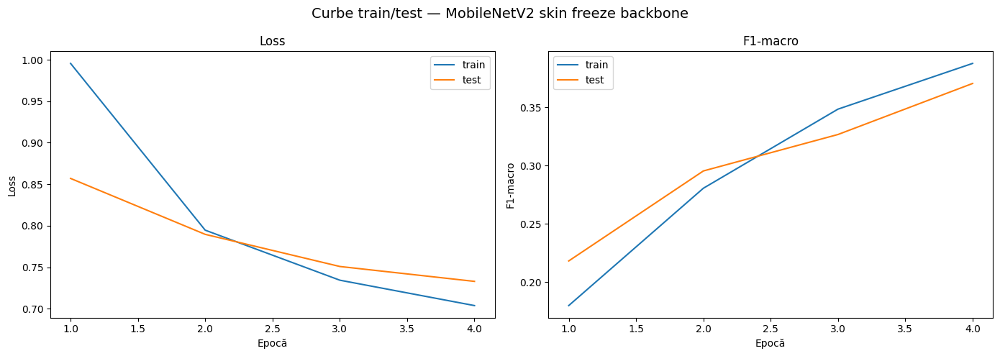

Curbe salvate în: /kaggle/working/artifacts/mobilenetv2_skin_freeze_backbone_curves.png


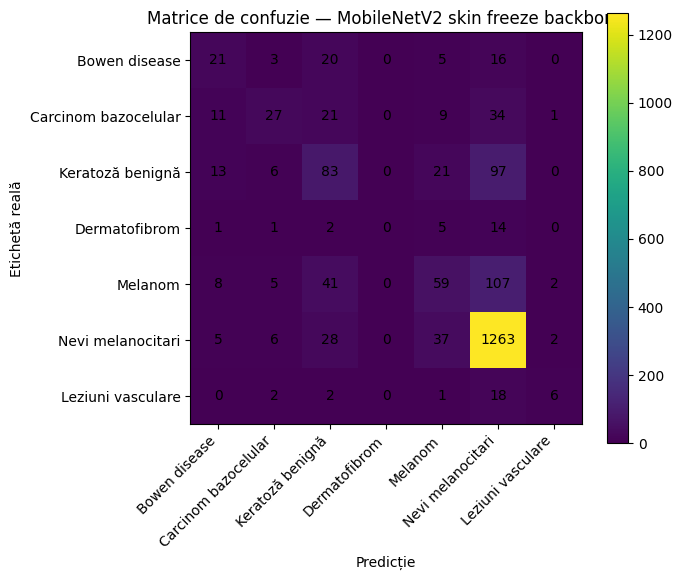

Matrice salvată în: /kaggle/working/artifacts/mobilenetv2_skin_freeze_backbone_confusion_matrix.png

Rezultat final:
{'experiment': 'MobileNetV2 skin freeze backbone', 'model': 'MobileNetV2 pretrained ImageNet', 'freeze_backbone': True, 'best_val_f1_macro': 0.370353091338306, 'final_accuracy': 0.728407388916625, 'final_f1_macro': 0.370353091338306, 'final_f1_micro': 0.728407388916625, 'final_loss': 0.7329579492955581}


{'experiment': 'MobileNetV2 skin freeze backbone',
 'model': 'MobileNetV2 pretrained ImageNet',
 'freeze_backbone': True,
 'best_val_f1_macro': 0.370353091338306,
 'final_accuracy': 0.728407388916625,
 'final_f1_macro': 0.370353091338306,
 'final_f1_micro': 0.728407388916625,
 'final_loss': 0.7329579492955581}

In [72]:
FINETUNE_EPOCHS = 4

finetune_skin_model, finetune_skin_history, finetune_skin_result = run_finetune_experiment(
    experiment_name="MobileNetV2 skin freeze backbone",
    train_loader=skin_train_ft_loader,
    test_loader=skin_test_ft_loader,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    epochs=FINETUNE_EPOCHS,
    lr=1e-3,
    freeze_backbone=True
)

finetune_skin_result


=== Experiment fine-tuning: MobileNetV2 camera freeze backbone ===
MobileNetV2: weights ImageNet încărcate.
Epoca 01/4 | train loss=1.4810, train F1=0.2175 | test loss=1.3894, test F1=0.2918 | lr=0.001000
Epoca 02/4 | train loss=1.3139, train F1=0.3164 | test loss=1.3182, test F1=0.3009 | lr=0.001000
Epoca 03/4 | train loss=1.2594, train F1=0.3655 | test loss=1.2958, test F1=0.3340 | lr=0.001000
Epoca 04/4 | train loss=1.2331, train F1=0.3830 | test loss=1.2803, test F1=0.3397 | lr=0.001000


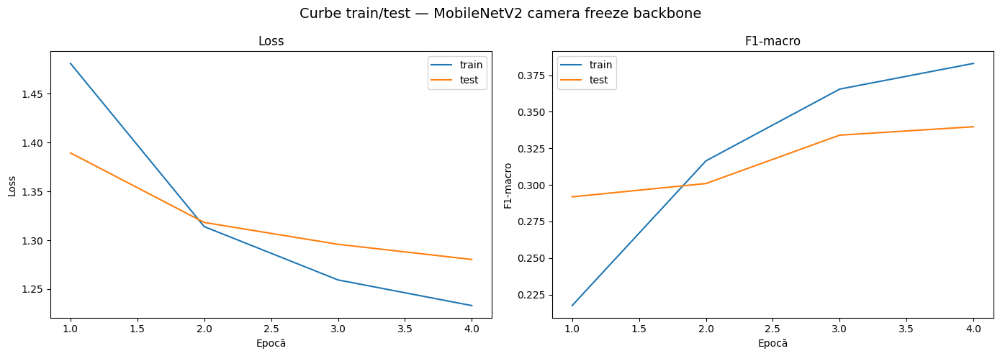

Curbe salvate în: /kaggle/working/artifacts/mobilenetv2_camera_freeze_backbone_curves.png


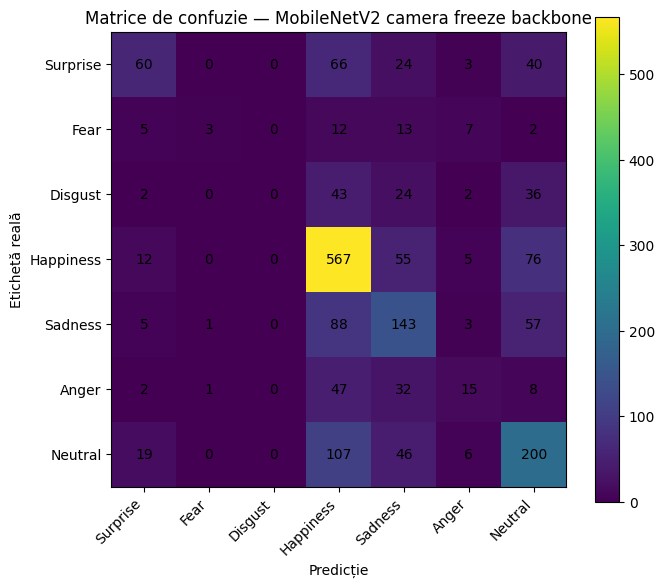

Matrice salvată în: /kaggle/working/artifacts/mobilenetv2_camera_freeze_backbone_confusion_matrix.png

Rezultat final:
{'experiment': 'MobileNetV2 camera freeze backbone', 'model': 'MobileNetV2 pretrained ImageNet', 'freeze_backbone': True, 'best_val_f1_macro': 0.3397387787245339, 'final_accuracy': 0.537833424060969, 'final_f1_macro': 0.3397387787245339, 'final_f1_micro': 0.537833424060969, 'final_loss': 1.280334450852047}


{'experiment': 'MobileNetV2 camera freeze backbone',
 'model': 'MobileNetV2 pretrained ImageNet',
 'freeze_backbone': True,
 'best_val_f1_macro': 0.3397387787245339,
 'final_accuracy': 0.537833424060969,
 'final_f1_macro': 0.3397387787245339,
 'final_f1_micro': 0.537833424060969,
 'final_loss': 1.280334450852047}

In [73]:
FINETUNE_EPOCHS = 4

finetune_camera_model, finetune_camera_history, finetune_camera_result = run_finetune_experiment(
    experiment_name="MobileNetV2 camera freeze backbone",
    train_loader=camera_train_ft_loader,
    test_loader=camera_test_ft_loader,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    epochs=FINETUNE_EPOCHS,
    lr=1e-3,
    freeze_backbone=True
)

finetune_camera_result


=== Experiment CNN: CNN skin fara BatchNorm ===
Epoca 01/3 | train loss=1.3293, train F1=0.1115 | test loss=1.0844, test F1=0.1146
Epoca 02/3 | train loss=1.0391, train F1=0.1150 | test loss=1.0181, test F1=0.1146
Epoca 03/3 | train loss=0.9867, train F1=0.1182 | test loss=0.9675, test F1=0.1146


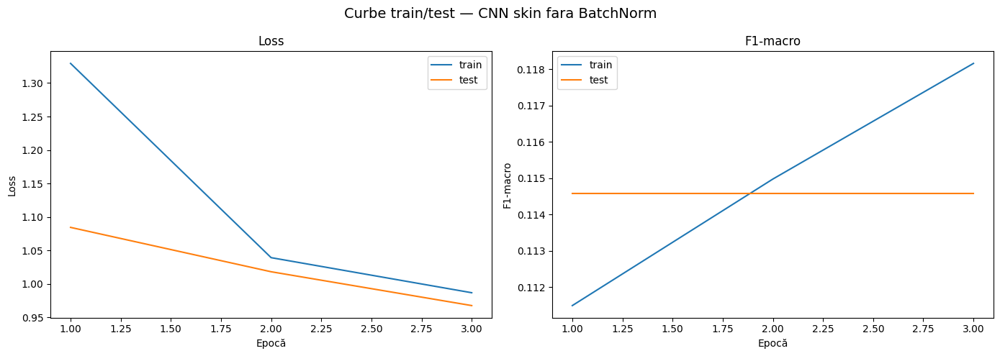

Curbe salvate în: /kaggle/working/artifacts/cnn_skin_fara_batchnorm_curves.png


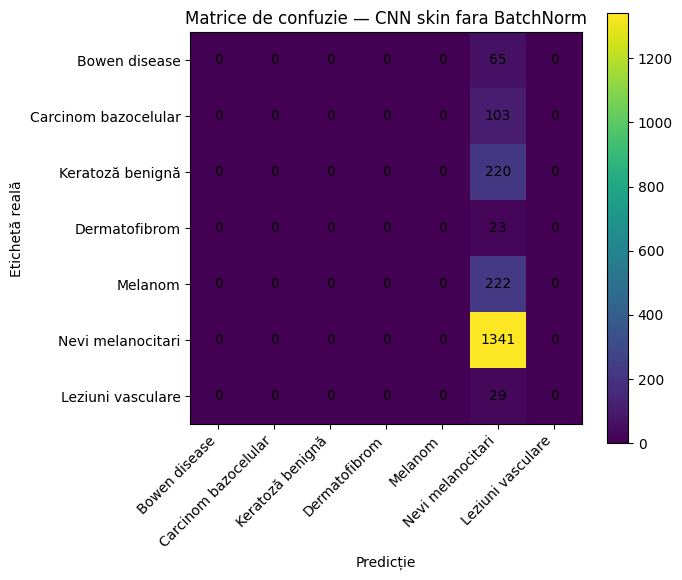

Matrice salvată în: /kaggle/working/artifacts/cnn_skin_fara_batchnorm_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN skin fara BatchNorm', 'model': 'CNN', 'first_kernel_size': 5, 'use_batchnorm': False, 'best_val_f1_macro': 0.11457621326042379, 'final_accuracy': 0.6694957563654518, 'final_f1_macro': 0.11457621326042379, 'final_f1_micro': 0.6694957563654518, 'final_loss': 1.0843550918462928}


{'experiment': 'CNN skin fara BatchNorm',
 'model': 'CNN',
 'first_kernel_size': 5,
 'use_batchnorm': False,
 'best_val_f1_macro': 0.11457621326042379,
 'final_accuracy': 0.6694957563654518,
 'final_f1_macro': 0.11457621326042379,
 'final_f1_micro': 0.6694957563654518,
 'final_loss': 1.0843550918462928}

In [74]:
CNN_EPOCHS = 3

cnn_skin_no_bn_model, cnn_skin_no_bn_history, cnn_skin_no_bn_result = run_cnn_experiment(
    experiment_name="CNN skin fara BatchNorm",
    train_loader=skin_train_cnn_loader,
    test_loader=skin_test_cnn_loader,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    first_kernel_size=5,
    use_batchnorm=False,
    epochs=CNN_EPOCHS
)

cnn_skin_no_bn_result


=== Experiment CNN: CNN camera fara BatchNorm ===
Epoca 01/3 | train loss=1.6821, train F1=0.0976 | test loss=1.6517, test F1=0.0800
Epoca 02/3 | train loss=1.6190, train F1=0.0815 | test loss=1.6268, test F1=0.0800
Epoca 03/3 | train loss=1.5873, train F1=0.1003 | test loss=1.6101, test F1=0.1150


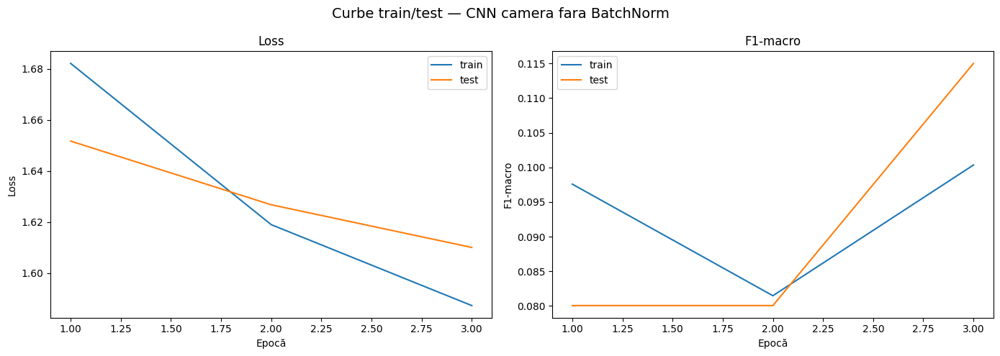

Curbe salvate în: /kaggle/working/artifacts/cnn_camera_fara_batchnorm_curves.png


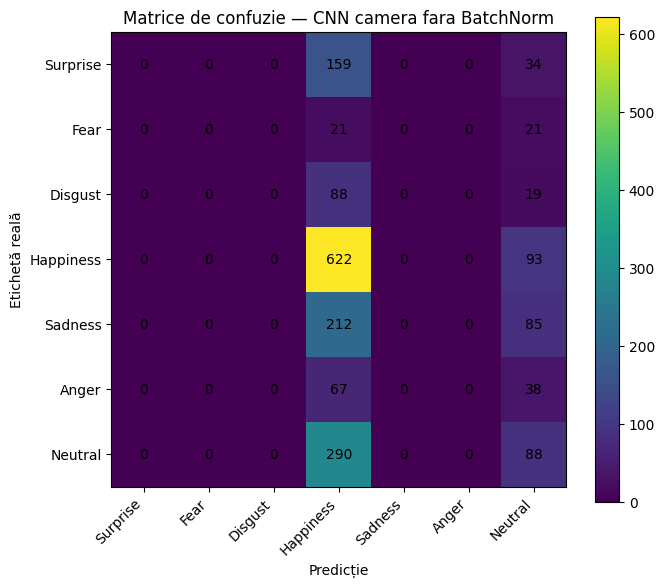

Matrice salvată în: /kaggle/working/artifacts/cnn_camera_fara_batchnorm_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN camera fara BatchNorm', 'model': 'CNN', 'first_kernel_size': 3, 'use_batchnorm': False, 'best_val_f1_macro': 0.1150030491599686, 'final_accuracy': 0.3864997278170931, 'final_f1_macro': 0.1150030491599686, 'final_f1_micro': 0.3864997278170931, 'final_loss': 1.6100791128160645}


{'experiment': 'CNN camera fara BatchNorm',
 'model': 'CNN',
 'first_kernel_size': 3,
 'use_batchnorm': False,
 'best_val_f1_macro': 0.1150030491599686,
 'final_accuracy': 0.3864997278170931,
 'final_f1_macro': 0.1150030491599686,
 'final_f1_micro': 0.3864997278170931,
 'final_loss': 1.6100791128160645}

In [75]:
CNN_EPOCHS = 3

cnn_camera_no_bn_model, cnn_camera_no_bn_history, cnn_camera_no_bn_result = run_cnn_experiment(
    experiment_name="CNN camera fara BatchNorm",
    train_loader=camera_train_cnn_loader,
    test_loader=camera_test_cnn_loader,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    first_kernel_size=3,
    use_batchnorm=False,
    epochs=CNN_EPOCHS
)

cnn_camera_no_bn_result

In [76]:
def make_cnn_aug_transform(mean, std, image_size=64, mode="none", dataset_type="skin"):
    transforms_list = [
        A.Resize(image_size, image_size)
    ]

    if mode == "geometric":
        if dataset_type == "skin":
            transforms_list += [
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                A.Rotate(limit=45, p=0.5),
            ]
        else:
            transforms_list += [
                A.HorizontalFlip(p=0.5),
                A.Affine(
                    scale=(0.90, 1.10),
                    translate_percent=(-0.05, 0.05),
                    rotate=(-12, 12),
                    p=0.7
                ),
            ]

    elif mode == "color":
        transforms_list += [
            A.RandomBrightnessContrast(
                brightness_limit=0.15,
                contrast_limit=0.15,
                p=0.7
            ),
            A.GaussianBlur(blur_limit=(3, 3), p=0.2),
        ]

    elif mode == "all":
        if dataset_type == "skin":
            transforms_list += [
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                A.Rotate(limit=45, p=0.5),
                A.RandomBrightnessContrast(
                    brightness_limit=0.10,
                    contrast_limit=0.10,
                    p=0.7
                ),
                A.GaussianBlur(blur_limit=(3, 3), p=0.15),
            ]
        else:
            transforms_list += [
                A.HorizontalFlip(p=0.5),
                A.Affine(
                    scale=(0.90, 1.10),
                    translate_percent=(-0.05, 0.05),
                    rotate=(-12, 12),
                    p=0.7
                ),
                A.RandomBrightnessContrast(
                    brightness_limit=0.20,
                    contrast_limit=0.20,
                    p=0.7
                ),
                A.GaussianBlur(blur_limit=(3, 3), p=0.15),
            ]

    elif mode == "none":
        pass

    else:
        raise ValueError("mode trebuie să fie: none, geometric, color sau all")

    transforms_list += [
        A.Normalize(mean=mean, std=std),
        ToTensorV2()
    ]

    return A.Compose(transforms_list)

In [77]:
def make_cnn_ablation_loaders(dataset_name: str, aug_mode: str):
    if dataset_name == "skin":
        train_transform = make_cnn_aug_transform(
            mean=SKIN_MEAN,
            std=SKIN_STD,
            image_size=CNN_IMAGE_SIZE,
            mode=aug_mode,
            dataset_type="skin"
        )

        test_transform = make_cnn_aug_transform(
            mean=SKIN_MEAN,
            std=SKIN_STD,
            image_size=CNN_IMAGE_SIZE,
            mode="none",
            dataset_type="skin"
        )

        train_ds = FastImageCSVDataset(
            df=df_mole_train,
            root_dirs=[MOLE_TRAIN_DIR, MOLE_ROOT],
            image_column=MOLE_PATH_COL,
            label_column=MOLE_LABEL_COL,
            class_to_idx=skin_class_to_idx,
            transform=train_transform
        )

        test_ds = FastImageCSVDataset(
            df=df_mole_test,
            root_dirs=[MOLE_TEST_DIR, MOLE_ROOT],
            image_column=MOLE_PATH_COL,
            label_column=MOLE_LABEL_COL,
            class_to_idx=skin_class_to_idx,
            transform=test_transform
        )

    elif dataset_name == "camera":
        train_transform = make_cnn_aug_transform(
            mean=CAMERA_MEAN,
            std=CAMERA_STD,
            image_size=CNN_IMAGE_SIZE,
            mode=aug_mode,
            dataset_type="camera"
        )

        test_transform = make_cnn_aug_transform(
            mean=CAMERA_MEAN,
            std=CAMERA_STD,
            image_size=CNN_IMAGE_SIZE,
            mode="none",
            dataset_type="camera"
        )

        train_ds = FastImageCSVDataset(
            df=df_face_train,
            root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
            image_column=FACE_PATH_COL,
            label_column=FACE_LABEL_COL,
            class_to_idx=camera_class_to_idx,
            transform=train_transform
        )

        test_ds = FastImageCSVDataset(
            df=df_face_test,
            root_dirs=[FACE_DATASET_DIR, FACE_ROOT],
            image_column=FACE_PATH_COL,
            label_column=FACE_LABEL_COL,
            class_to_idx=camera_class_to_idx,
            transform=test_transform
        )

    else:
        raise ValueError("dataset_name trebuie să fie 'skin' sau 'camera'")

    train_loader = DataLoader(
        train_ds,
        batch_size=CNN_BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        drop_last=True
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=CNN_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )

    return train_loader, test_loader

In [78]:
RUN_SINGLE_AUG_EXPERIMENT = False 

if RUN_SINGLE_AUG_EXPERIMENT:
    DATASET_NAME = "skin"     
    AUG_MODE = "geometric"     
    CNN_EPOCHS = 3

    train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
        dataset_name=DATASET_NAME,
        aug_mode=AUG_MODE
    )

    if DATASET_NAME == "skin":
        num_classes = len(skin_class_to_idx)
        labels = skin_class_labels
        first_kernel = 5
    else:
        num_classes = len(camera_class_to_idx)
        labels = camera_class_labels
        first_kernel = 3

    cnn_aug_model, cnn_aug_history, cnn_aug_result = run_cnn_experiment(
        experiment_name=f"CNN {DATASET_NAME} augmentare {AUG_MODE}",
        train_loader=train_loader_aug,
        test_loader=test_loader_aug,
        num_classes=num_classes,
        class_labels=labels,
        first_kernel_size=first_kernel,
        use_batchnorm=True,
        epochs=CNN_EPOCHS
    )

    display(cnn_aug_result)
else:
    print("Sărit: experimentul punctual este opțional; rulează ablațiile individuale none/geometric/color/all de mai jos.")

Sărit: experimentul punctual este opțional; rulează ablațiile individuale none/geometric/color/all de mai jos.


Dataset creat: 6009 imagini
Dataset creat: 2003 imagini

=== Experiment CNN: CNN skin augmentare none ===
Epoca 01/3 | train loss=1.1410, train F1=0.1475 | test loss=1.1553, test F1=0.1146
Epoca 02/3 | train loss=0.8644, train F1=0.1520 | test loss=0.9382, test F1=0.1210
Epoca 03/3 | train loss=0.8287, train F1=0.2078 | test loss=0.8435, test F1=0.2615


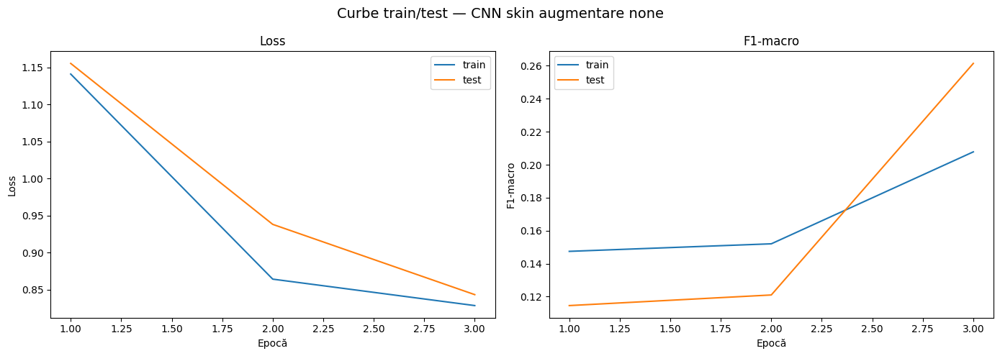

Curbe salvate în: /kaggle/working/artifacts/cnn_skin_augmentare_none_curves.png


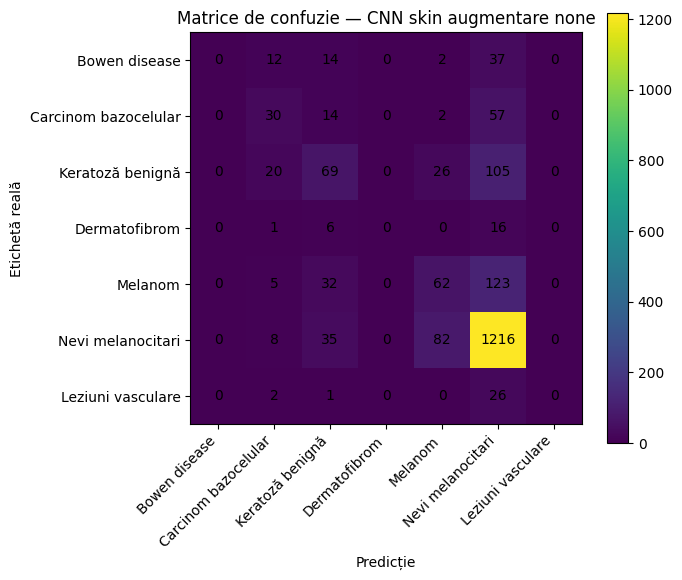

Matrice salvată în: /kaggle/working/artifacts/cnn_skin_augmentare_none_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN skin augmentare none', 'model': 'CNN', 'first_kernel_size': 5, 'use_batchnorm': True, 'best_val_f1_macro': 0.2614508257908169, 'final_accuracy': 0.6874687968047928, 'final_f1_macro': 0.2614508257908169, 'final_f1_micro': 0.6874687968047928, 'final_loss': 0.8434716421725806}


{'experiment': 'CNN skin augmentare none',
 'model': 'CNN',
 'first_kernel_size': 5,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.2614508257908169,
 'final_accuracy': 0.6874687968047928,
 'final_f1_macro': 0.2614508257908169,
 'final_f1_micro': 0.6874687968047928,
 'final_loss': 0.8434716421725806}

In [79]:
DATASET_NAME = "skin"
AUG_MODE = "none"
CNN_EPOCHS = 3

train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
    dataset_name=DATASET_NAME,
    aug_mode=AUG_MODE
)

cnn_skin_aug_none_model, cnn_skin_aug_none_history, cnn_skin_aug_none_result = run_cnn_experiment(
    experiment_name="CNN skin augmentare none",
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    first_kernel_size=5,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_skin_aug_none_result

Dataset creat: 6009 imagini
Dataset creat: 2003 imagini

=== Experiment CNN: CNN skin augmentare color ===
Epoca 01/3 | train loss=1.1377, train F1=0.1257 | test loss=0.9982, test F1=0.1146
Epoca 02/3 | train loss=0.9107, train F1=0.1487 | test loss=0.9759, test F1=0.1161
Epoca 03/3 | train loss=0.8627, train F1=0.1729 | test loss=0.8894, test F1=0.1993


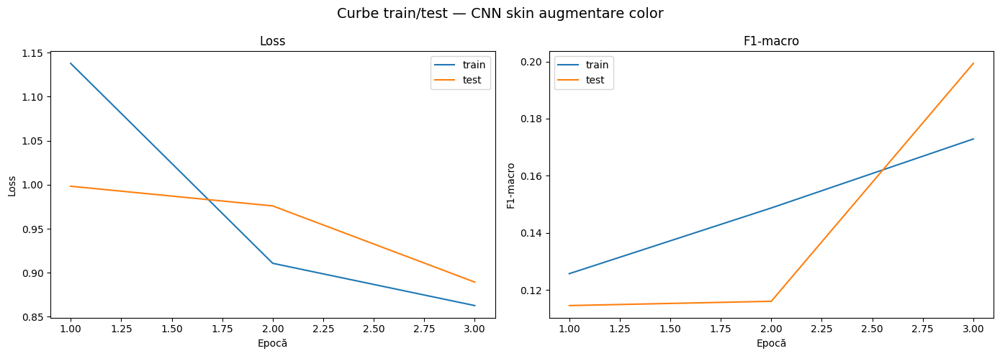

Curbe salvate în: /kaggle/working/artifacts/cnn_skin_augmentare_color_curves.png


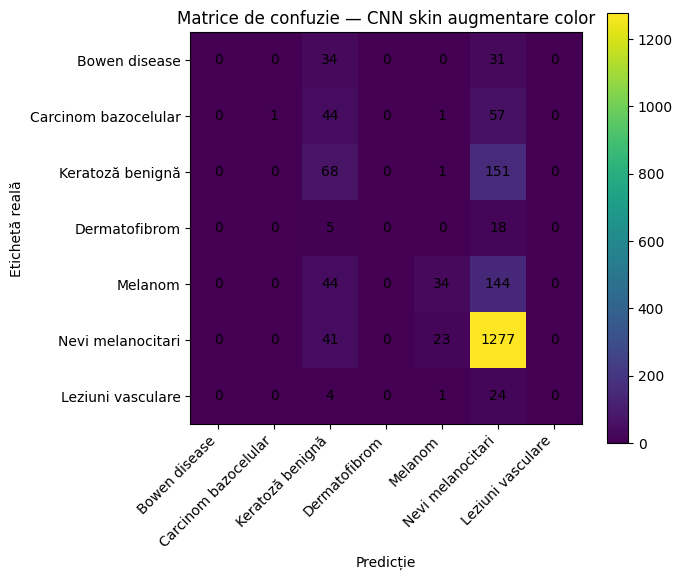

Matrice salvată în: /kaggle/working/artifacts/cnn_skin_augmentare_color_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN skin augmentare color', 'model': 'CNN', 'first_kernel_size': 5, 'use_batchnorm': True, 'best_val_f1_macro': 0.19933157342998037, 'final_accuracy': 0.6889665501747378, 'final_f1_macro': 0.19933157342998037, 'final_f1_micro': 0.6889665501747378, 'final_loss': 0.889380771103229}


{'experiment': 'CNN skin augmentare color',
 'model': 'CNN',
 'first_kernel_size': 5,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.19933157342998037,
 'final_accuracy': 0.6889665501747378,
 'final_f1_macro': 0.19933157342998037,
 'final_f1_micro': 0.6889665501747378,
 'final_loss': 0.889380771103229}

In [80]:
DATASET_NAME = "skin"
AUG_MODE = "color"
CNN_EPOCHS = 3

train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
    dataset_name=DATASET_NAME,
    aug_mode=AUG_MODE
)

cnn_skin_aug_color_model, cnn_skin_aug_color_history, cnn_skin_aug_color_result = run_cnn_experiment(
    experiment_name="CNN skin augmentare color",
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    first_kernel_size=5,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_skin_aug_color_result


Dataset creat: 6009 imagini
Dataset creat: 2003 imagini

=== Experiment CNN: CNN skin augmentare all ===
Epoca 01/3 | train loss=1.1363, train F1=0.1258 | test loss=0.9690, test F1=0.1146
Epoca 02/3 | train loss=0.9125, train F1=0.1331 | test loss=0.8843, test F1=0.1288
Epoca 03/3 | train loss=0.8736, train F1=0.1501 | test loss=0.8433, test F1=0.1600


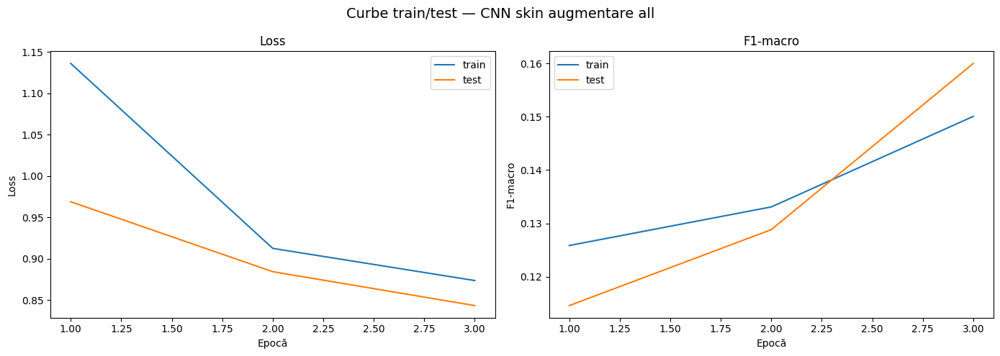

Curbe salvate în: /kaggle/working/artifacts/cnn_skin_augmentare_all_curves.png


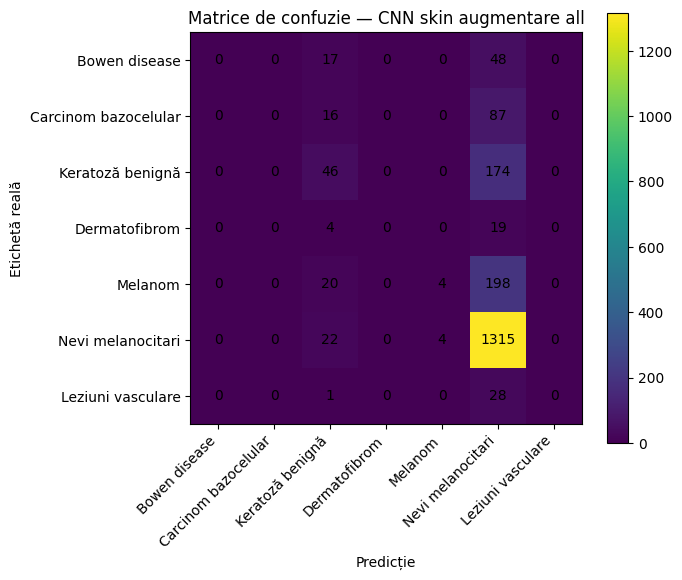

Matrice salvată în: /kaggle/working/artifacts/cnn_skin_augmentare_all_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN skin augmentare all', 'model': 'CNN', 'first_kernel_size': 5, 'use_batchnorm': True, 'best_val_f1_macro': 0.15999902917106085, 'final_accuracy': 0.6814777833250125, 'final_f1_macro': 0.15999902917106085, 'final_f1_micro': 0.6814777833250125, 'final_loss': 0.8433201438298656}


{'experiment': 'CNN skin augmentare all',
 'model': 'CNN',
 'first_kernel_size': 5,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.15999902917106085,
 'final_accuracy': 0.6814777833250125,
 'final_f1_macro': 0.15999902917106085,
 'final_f1_micro': 0.6814777833250125,
 'final_loss': 0.8433201438298656}

In [81]:
DATASET_NAME = "skin"
AUG_MODE = "all"
CNN_EPOCHS = 3

train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
    dataset_name=DATASET_NAME,
    aug_mode=AUG_MODE
)

cnn_skin_aug_all_model, cnn_skin_aug_all_history, cnn_skin_aug_all_result = run_cnn_experiment(
    experiment_name="CNN skin augmentare all",
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    first_kernel_size=5,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_skin_aug_all_result

Dataset creat: 10434 imagini
Dataset creat: 1837 imagini

=== Experiment CNN: CNN camera augmentare none ===
Epoca 01/3 | train loss=1.6224, train F1=0.1437 | test loss=1.5916, test F1=0.1164
Epoca 02/3 | train loss=1.5100, train F1=0.1668 | test loss=1.6191, test F1=0.1075
Epoca 03/3 | train loss=1.4119, train F1=0.2079 | test loss=1.3520, test F1=0.2356


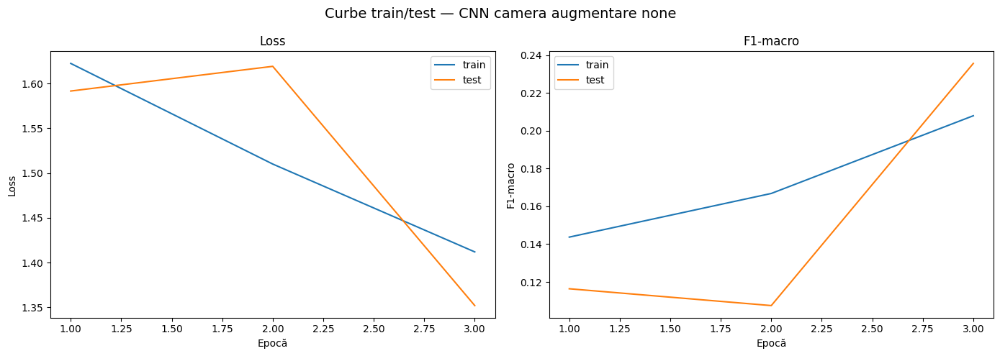

Curbe salvate în: /kaggle/working/artifacts/cnn_camera_augmentare_none_curves.png


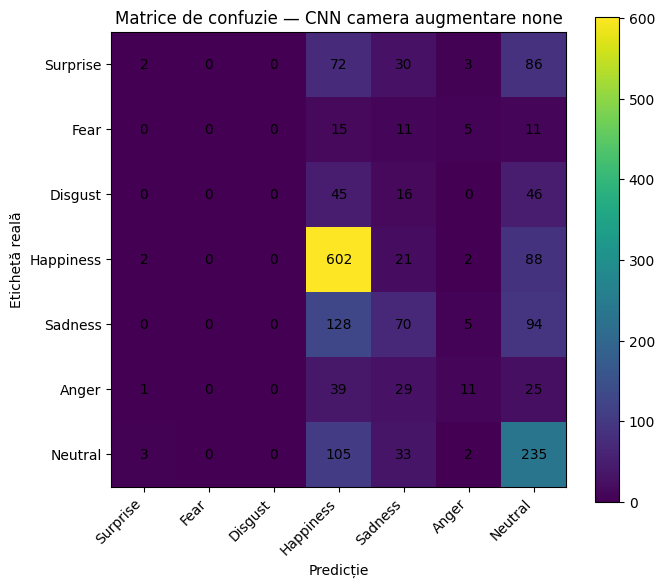

Matrice salvată în: /kaggle/working/artifacts/cnn_camera_augmentare_none_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN camera augmentare none', 'model': 'CNN', 'first_kernel_size': 3, 'use_batchnorm': True, 'best_val_f1_macro': 0.23558565213960853, 'final_accuracy': 0.5008165487207403, 'final_f1_macro': 0.23558565213960853, 'final_f1_micro': 0.5008165487207403, 'final_loss': 1.3520007030303283}


{'experiment': 'CNN camera augmentare none',
 'model': 'CNN',
 'first_kernel_size': 3,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.23558565213960853,
 'final_accuracy': 0.5008165487207403,
 'final_f1_macro': 0.23558565213960853,
 'final_f1_micro': 0.5008165487207403,
 'final_loss': 1.3520007030303283}

In [82]:
DATASET_NAME = "camera"
AUG_MODE = "none"
CNN_EPOCHS = 3

train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
    dataset_name=DATASET_NAME,
    aug_mode=AUG_MODE
)

cnn_camera_aug_none_model, cnn_camera_aug_none_history, cnn_camera_aug_none_result = run_cnn_experiment(
    experiment_name="CNN camera augmentare none",
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    first_kernel_size=3,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_camera_aug_none_result

Dataset creat: 10434 imagini
Dataset creat: 1837 imagini

=== Experiment CNN: CNN camera augmentare geometric ===
Epoca 01/3 | train loss=1.6540, train F1=0.1405 | test loss=1.5910, test F1=0.0819
Epoca 02/3 | train loss=1.5454, train F1=0.1413 | test loss=1.5411, test F1=0.1708
Epoca 03/3 | train loss=1.4901, train F1=0.1752 | test loss=1.4643, test F1=0.1865


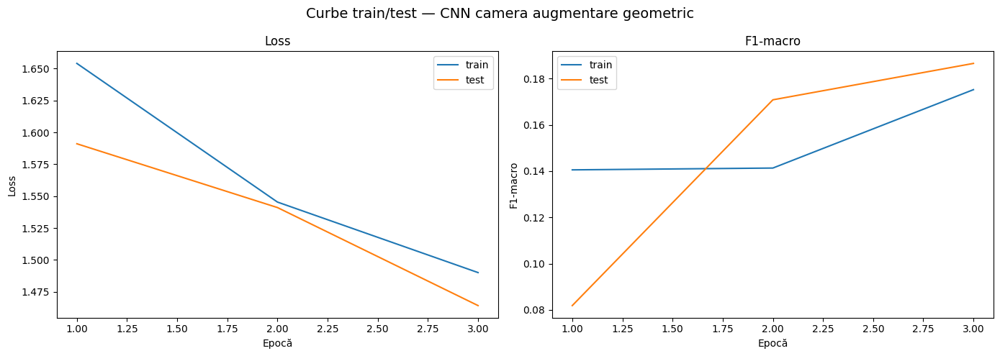

Curbe salvate în: /kaggle/working/artifacts/cnn_camera_augmentare_geometric_curves.png


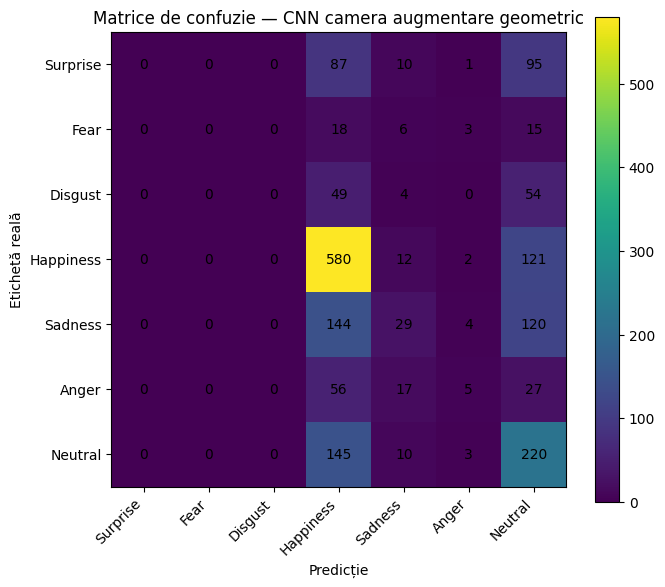

Matrice salvată în: /kaggle/working/artifacts/cnn_camera_augmentare_geometric_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN camera augmentare geometric', 'model': 'CNN', 'first_kernel_size': 3, 'use_batchnorm': True, 'best_val_f1_macro': 0.1865334866730654, 'final_accuracy': 0.45400108873162764, 'final_f1_macro': 0.1865334866730654, 'final_f1_micro': 0.45400108873162764, 'final_loss': 1.4642661593826036}


{'experiment': 'CNN camera augmentare geometric',
 'model': 'CNN',
 'first_kernel_size': 3,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.1865334866730654,
 'final_accuracy': 0.45400108873162764,
 'final_f1_macro': 0.1865334866730654,
 'final_f1_micro': 0.45400108873162764,
 'final_loss': 1.4642661593826036}

In [83]:
DATASET_NAME = "camera"
AUG_MODE = "geometric"
CNN_EPOCHS = 3

train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
    dataset_name=DATASET_NAME,
    aug_mode=AUG_MODE
)

cnn_camera_aug_geometric_model, cnn_camera_aug_geometric_history, cnn_camera_aug_geometric_result = run_cnn_experiment(
    experiment_name="CNN camera augmentare geometric",
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    first_kernel_size=3,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_camera_aug_geometric_result

Dataset creat: 10434 imagini
Dataset creat: 1837 imagini

=== Experiment CNN: CNN camera augmentare color ===
Epoca 01/3 | train loss=1.6164, train F1=0.1430 | test loss=1.5774, test F1=0.1151
Epoca 02/3 | train loss=1.5339, train F1=0.1571 | test loss=1.5659, test F1=0.1088
Epoca 03/3 | train loss=1.4493, train F1=0.1898 | test loss=1.4097, test F1=0.1757


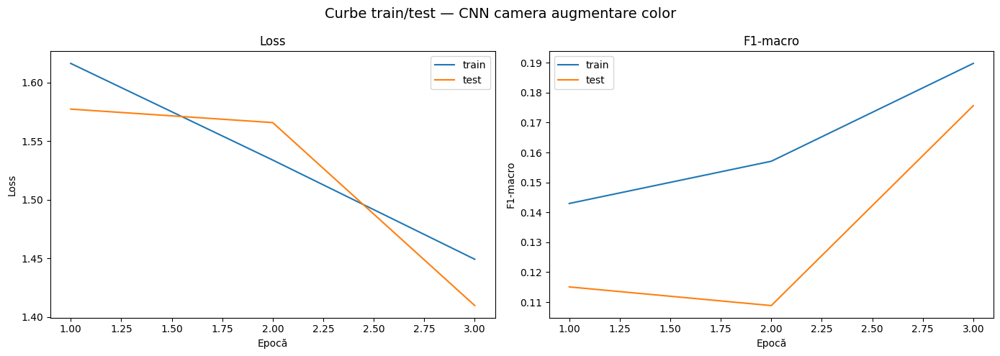

Curbe salvate în: /kaggle/working/artifacts/cnn_camera_augmentare_color_curves.png


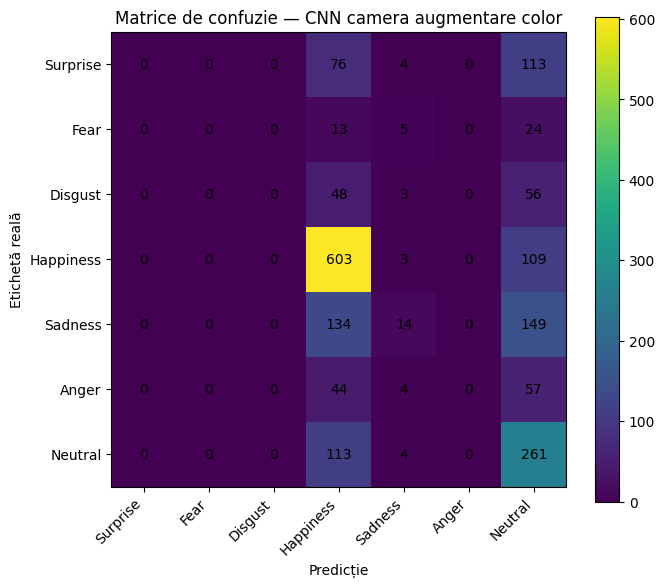

Matrice salvată în: /kaggle/working/artifacts/cnn_camera_augmentare_color_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN camera augmentare color', 'model': 'CNN', 'first_kernel_size': 3, 'use_batchnorm': True, 'best_val_f1_macro': 0.17566489233796453, 'final_accuracy': 0.4779531845400109, 'final_f1_macro': 0.17566489233796453, 'final_f1_micro': 0.4779531845400109, 'final_loss': 1.4097353001619461}


{'experiment': 'CNN camera augmentare color',
 'model': 'CNN',
 'first_kernel_size': 3,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.17566489233796453,
 'final_accuracy': 0.4779531845400109,
 'final_f1_macro': 0.17566489233796453,
 'final_f1_micro': 0.4779531845400109,
 'final_loss': 1.4097353001619461}

In [84]:
DATASET_NAME = "camera"
AUG_MODE = "color"
CNN_EPOCHS = 3

train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
    dataset_name=DATASET_NAME,
    aug_mode=AUG_MODE
)

cnn_camera_aug_color_model, cnn_camera_aug_color_history, cnn_camera_aug_color_result = run_cnn_experiment(
    experiment_name="CNN camera augmentare color",
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    first_kernel_size=3,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_camera_aug_color_result

Dataset creat: 10434 imagini
Dataset creat: 1837 imagini

=== Experiment CNN: CNN camera augmentare all ===
Epoca 01/3 | train loss=1.6179, train F1=0.1313 | test loss=1.5802, test F1=0.0981
Epoca 02/3 | train loss=1.5524, train F1=0.1410 | test loss=1.5501, test F1=0.1106
Epoca 03/3 | train loss=1.5215, train F1=0.1516 | test loss=1.5030, test F1=0.1527


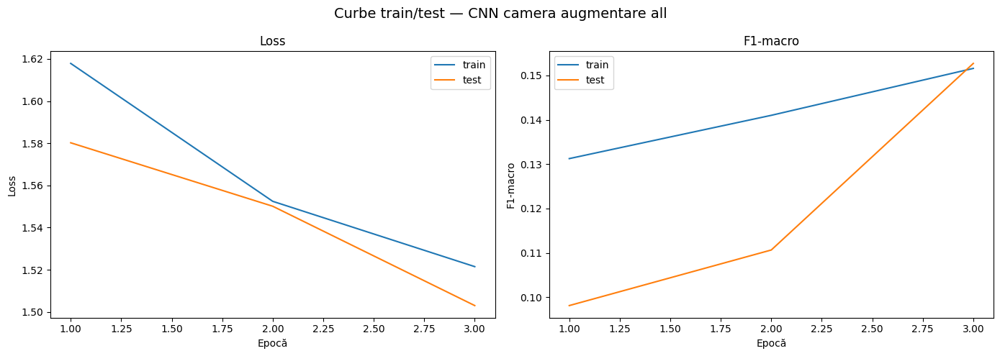

Curbe salvate în: /kaggle/working/artifacts/cnn_camera_augmentare_all_curves.png


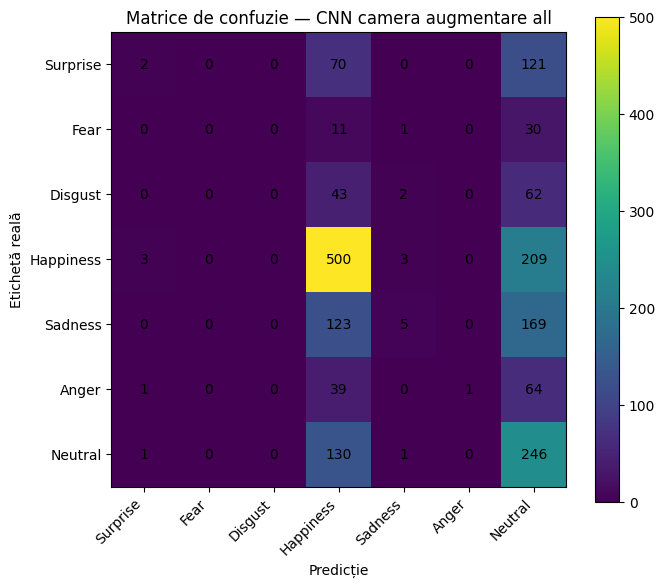

Matrice salvată în: /kaggle/working/artifacts/cnn_camera_augmentare_all_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN camera augmentare all', 'model': 'CNN', 'first_kernel_size': 3, 'use_batchnorm': True, 'best_val_f1_macro': 0.15271809951798446, 'final_accuracy': 0.41045182362547633, 'final_f1_macro': 0.15271809951798446, 'final_f1_micro': 0.41045182362547633, 'final_loss': 1.5029977342001304}


{'experiment': 'CNN camera augmentare all',
 'model': 'CNN',
 'first_kernel_size': 3,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.15271809951798446,
 'final_accuracy': 0.41045182362547633,
 'final_f1_macro': 0.15271809951798446,
 'final_f1_micro': 0.41045182362547633,
 'final_loss': 1.5029977342001304}

In [85]:
DATASET_NAME = "camera"
AUG_MODE = "all"
CNN_EPOCHS = 3

train_loader_aug, test_loader_aug = make_cnn_ablation_loaders(
    dataset_name=DATASET_NAME,
    aug_mode=AUG_MODE
)

cnn_camera_aug_all_model, cnn_camera_aug_all_history, cnn_camera_aug_all_result = run_cnn_experiment(
    experiment_name="CNN camera augmentare all",
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    first_kernel_size=3,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_camera_aug_all_result

In [86]:
def make_weighted_sampler(dataset):
    labels = np.array([label for _, label in dataset.samples])

    class_counts = np.bincount(labels)
    class_weights = 1.0 / class_counts
    sample_weights = class_weights[labels]

    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True
    )

    print("Class counts:", class_counts)
    print("Class weights:", class_weights)

    return sampler

Class counts: [ 196  308  660   69  668 4023   85]
Class weights: [0.00510204 0.00324675 0.00151515 0.01449275 0.00149701 0.00024857
 0.01176471]

=== Experiment CNN: CNN skin cu WeightedRandomSampler ===
Epoca 01/3 | train loss=1.6580, train F1=0.3549 | test loss=1.2516, test F1=0.2868
Epoca 02/3 | train loss=1.3296, train F1=0.4984 | test loss=1.1074, test F1=0.3754
Epoca 03/3 | train loss=1.1908, train F1=0.5322 | test loss=1.2375, test F1=0.3754


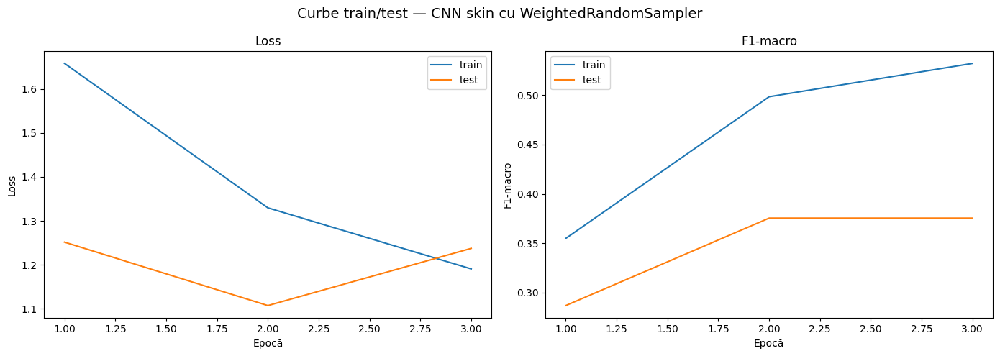

Curbe salvate în: /kaggle/working/artifacts/cnn_skin_cu_weightedrandomsampler_curves.png


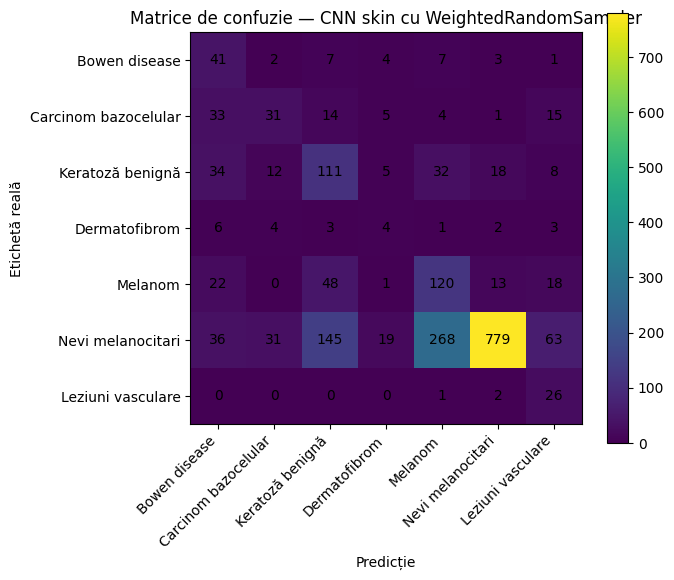

Matrice salvată în: /kaggle/working/artifacts/cnn_skin_cu_weightedrandomsampler_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN skin cu WeightedRandomSampler', 'model': 'CNN', 'first_kernel_size': 5, 'use_batchnorm': True, 'best_val_f1_macro': 0.3754439155013513, 'final_accuracy': 0.5551672491263105, 'final_f1_macro': 0.3754439155013513, 'final_f1_micro': 0.5551672491263105, 'final_loss': 1.1073846671799095}


{'experiment': 'CNN skin cu WeightedRandomSampler',
 'model': 'CNN',
 'first_kernel_size': 5,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.3754439155013513,
 'final_accuracy': 0.5551672491263105,
 'final_f1_macro': 0.3754439155013513,
 'final_f1_micro': 0.5551672491263105,
 'final_loss': 1.1073846671799095}

In [87]:
skin_sampler = make_weighted_sampler(skin_train_cnn_ds)

skin_train_cnn_balanced_loader = DataLoader(
    skin_train_cnn_ds,
    batch_size=CNN_BATCH_SIZE,
    sampler=skin_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

CNN_EPOCHS = 3

cnn_skin_balanced_model, cnn_skin_balanced_history, cnn_skin_balanced_result = run_cnn_experiment(
    experiment_name="CNN skin cu WeightedRandomSampler",
    train_loader=skin_train_cnn_balanced_loader,
    test_loader=skin_test_cnn_loader,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    first_kernel_size=5,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_skin_balanced_result

Class counts: [1097  239  610 4057 1685  600 2146]
Class weights: [0.00091158 0.0041841  0.00163934 0.00024649 0.00059347 0.00166667
 0.00046598]

=== Experiment CNN: CNN camera cu WeightedRandomSampler ===
Epoca 01/3 | train loss=1.8045, train F1=0.2262 | test loss=1.7567, test F1=0.2172
Epoca 02/3 | train loss=1.7524, train F1=0.2742 | test loss=1.6543, test F1=0.2290
Epoca 03/3 | train loss=1.6408, train F1=0.3498 | test loss=1.6451, test F1=0.2827


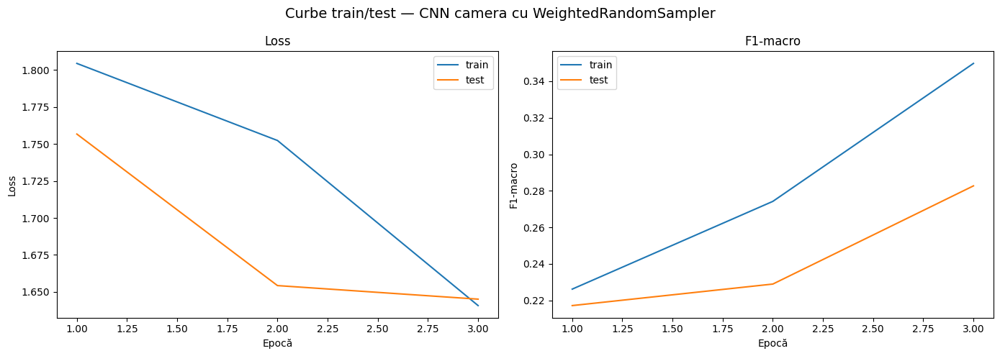

Curbe salvate în: /kaggle/working/artifacts/cnn_camera_cu_weightedrandomsampler_curves.png


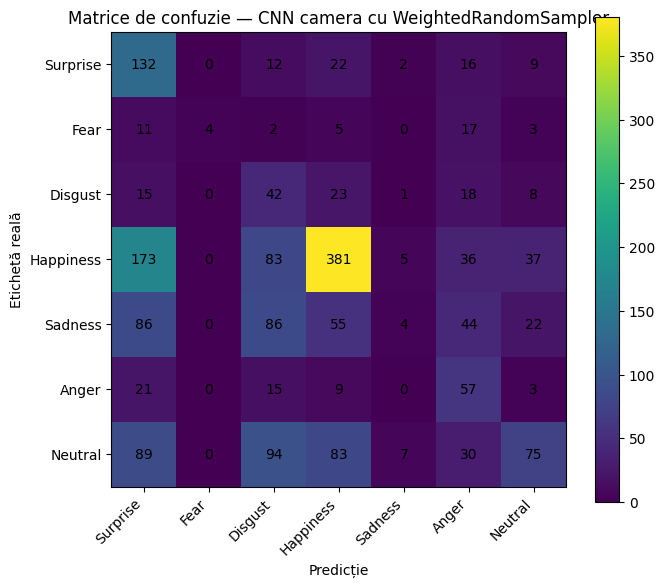

Matrice salvată în: /kaggle/working/artifacts/cnn_camera_cu_weightedrandomsampler_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN camera cu WeightedRandomSampler', 'model': 'CNN', 'first_kernel_size': 3, 'use_batchnorm': True, 'best_val_f1_macro': 0.2827163586764719, 'final_accuracy': 0.37833424060968973, 'final_f1_macro': 0.2827163586764719, 'final_f1_micro': 0.37833424060968973, 'final_loss': 1.6451130290361091}


{'experiment': 'CNN camera cu WeightedRandomSampler',
 'model': 'CNN',
 'first_kernel_size': 3,
 'use_batchnorm': True,
 'best_val_f1_macro': 0.2827163586764719,
 'final_accuracy': 0.37833424060968973,
 'final_f1_macro': 0.2827163586764719,
 'final_f1_micro': 0.37833424060968973,
 'final_loss': 1.6451130290361091}

In [88]:
camera_sampler = make_weighted_sampler(camera_train_cnn_ds)

camera_train_cnn_balanced_loader = DataLoader(
    camera_train_cnn_ds,
    batch_size=CNN_BATCH_SIZE,
    sampler=camera_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

CNN_EPOCHS = 3

cnn_camera_balanced_model, cnn_camera_balanced_history, cnn_camera_balanced_result = run_cnn_experiment(
    experiment_name="CNN camera cu WeightedRandomSampler",
    train_loader=camera_train_cnn_balanced_loader,
    test_loader=camera_test_cnn_loader,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    first_kernel_size=3,
    use_batchnorm=True,
    epochs=CNN_EPOCHS
)

cnn_camera_balanced_result

In [89]:
def run_finetune_experiment_with_warmup(
    experiment_name: str,
    train_loader,
    test_loader,
    num_classes: int,
    class_labels: List[str],
    epochs: int = 3,
    lr: float = 1e-3,
    warmup_epochs: int = 1,
    weight_decay: float = 1e-4,
    freeze_backbone: bool = True
):
    print(f"\n=== Experiment fine-tuning cu warmup: {experiment_name} ===")

    model = build_mobilenet_v2(
        num_classes=num_classes,
        freeze_backbone=freeze_backbone
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    trainable_params = [p for p in model.parameters() if p.requires_grad]

    optimizer = optim.AdamW(
        trainable_params,
        lr=lr,
        weight_decay=weight_decay
    )

    def warmup_lambda(epoch):
        if epoch < warmup_epochs:
            return float(epoch + 1) / float(max(1, warmup_epochs))
        return 1.0

    scheduler = LambdaLR(optimizer, lr_lambda=warmup_lambda)

    history_rows = []
    best_f1 = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        train_metrics = train_one_epoch_finetune(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=DEVICE,
            freeze_bn=freeze_backbone
        )

        val_metrics = evaluate_finetune(
            model=model,
            loader=test_loader,
            criterion=criterion,
            device=DEVICE
        )

        scheduler.step()

        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_f1_macro": train_metrics["f1_macro"],
            "train_f1_micro": train_metrics["f1_micro"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_f1_micro": val_metrics["f1_micro"],
            "lr": optimizer.param_groups[0]["lr"],
        }

        history_rows.append(row)

        print(
            f"Epoca {epoch:02d}/{epochs} | "
            f"train F1={row['train_f1_macro']:.4f} | "
            f"test F1={row['val_f1_macro']:.4f} | "
            f"lr={row['lr']:.6f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    final_metrics = evaluate_finetune(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=DEVICE
    )

    history = pd.DataFrame(history_rows)
    safe_name = experiment_name.replace(" ", "_").replace("/", "_").lower()

    history.to_csv(ARTIFACTS_DIR / f"{safe_name}_history.csv", index=False)

    plot_training_curves(
        history=history,
        title=f"Curbe train/test — {experiment_name}",
        output_name=f"{safe_name}_curves.png"
    )

    plot_confusion_matrix_simple(
        y_true=final_metrics["labels"],
        y_pred=final_metrics["preds"],
        class_labels=class_labels,
        title=f"Matrice de confuzie — {experiment_name}",
        output_name=f"{safe_name}_confusion_matrix.png"
    )

    result = {
        "experiment": experiment_name,
        "model": "MobileNetV2 pretrained ImageNet",
        "freeze_backbone": freeze_backbone,
        "warmup": True,
        "warmup_epochs": warmup_epochs,
        "best_val_f1_macro": best_f1,
        "final_accuracy": final_metrics["accuracy"],
        "final_f1_macro": final_metrics["f1_macro"],
        "final_f1_micro": final_metrics["f1_micro"],
        "final_loss": final_metrics["loss"],
    }

    with open(ARTIFACTS_DIR / f"{safe_name}_results.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)

    print("\nRezultat final:")
    print(result)

    return model, history, result


=== Experiment fine-tuning cu warmup: MobileNetV2 skin freeze backbone cu warmup ===
MobileNetV2: weights ImageNet încărcate.
Epoca 01/3 | train F1=0.1844 | test F1=0.2330 | lr=0.001000
Epoca 02/3 | train F1=0.2981 | test F1=0.2751 | lr=0.001000
Epoca 03/3 | train F1=0.3494 | test F1=0.3207 | lr=0.001000


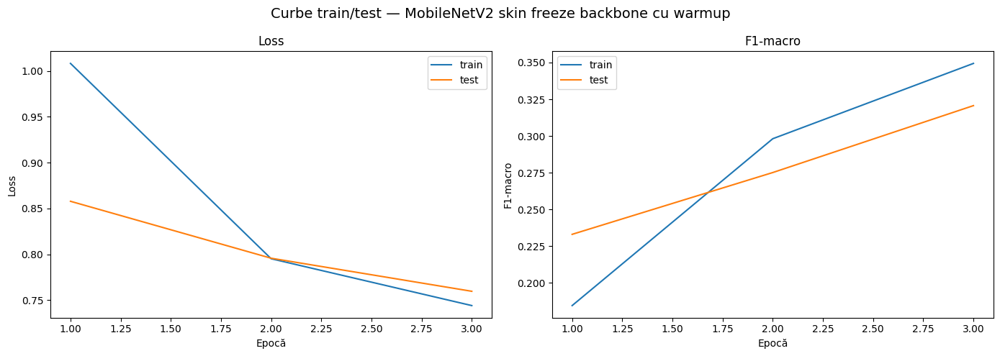

Curbe salvate în: /kaggle/working/artifacts/mobilenetv2_skin_freeze_backbone_cu_warmup_curves.png


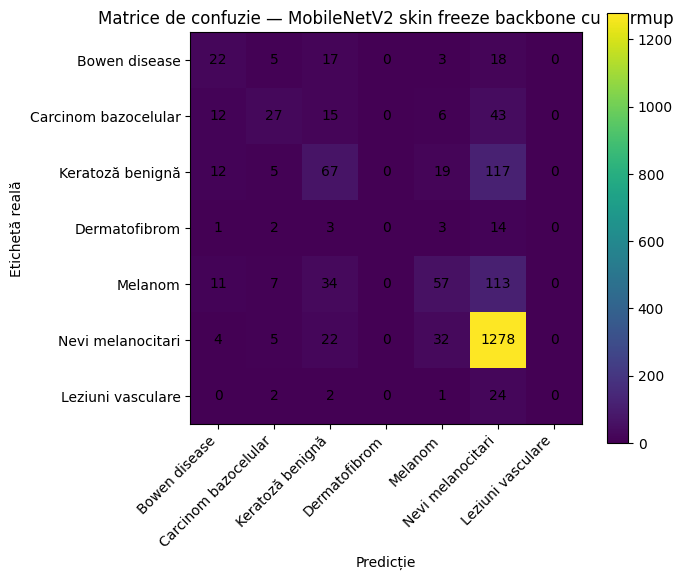

Matrice salvată în: /kaggle/working/artifacts/mobilenetv2_skin_freeze_backbone_cu_warmup_confusion_matrix.png

Rezultat final:
{'experiment': 'MobileNetV2 skin freeze backbone cu warmup', 'model': 'MobileNetV2 pretrained ImageNet', 'freeze_backbone': True, 'warmup': True, 'warmup_epochs': 1, 'best_val_f1_macro': 0.32066173256339303, 'final_accuracy': 0.7244133799301048, 'final_f1_macro': 0.32066173256339303, 'final_f1_micro': 0.7244133799301048, 'final_loss': 0.7596081326856532}


{'experiment': 'MobileNetV2 skin freeze backbone cu warmup',
 'model': 'MobileNetV2 pretrained ImageNet',
 'freeze_backbone': True,
 'warmup': True,
 'warmup_epochs': 1,
 'best_val_f1_macro': 0.32066173256339303,
 'final_accuracy': 0.7244133799301048,
 'final_f1_macro': 0.32066173256339303,
 'final_f1_micro': 0.7244133799301048,
 'final_loss': 0.7596081326856532}

In [90]:
FINETUNE_EPOCHS = 3

finetune_skin_warmup_model, finetune_skin_warmup_history, finetune_skin_warmup_result = run_finetune_experiment_with_warmup(
    experiment_name="MobileNetV2 skin freeze backbone cu warmup",
    train_loader=skin_train_ft_loader,
    test_loader=skin_test_ft_loader,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    epochs=FINETUNE_EPOCHS,
    lr=1e-3,
    warmup_epochs=1,
    freeze_backbone=True
)

finetune_skin_warmup_result


=== Experiment fine-tuning cu warmup: MobileNetV2 camera freeze backbone cu warmup ===
MobileNetV2: weights ImageNet încărcate.
Epoca 01/3 | train F1=0.2233 | test F1=0.2902 | lr=0.001000
Epoca 02/3 | train F1=0.3111 | test F1=0.3122 | lr=0.001000
Epoca 03/3 | train F1=0.3517 | test F1=0.3398 | lr=0.001000


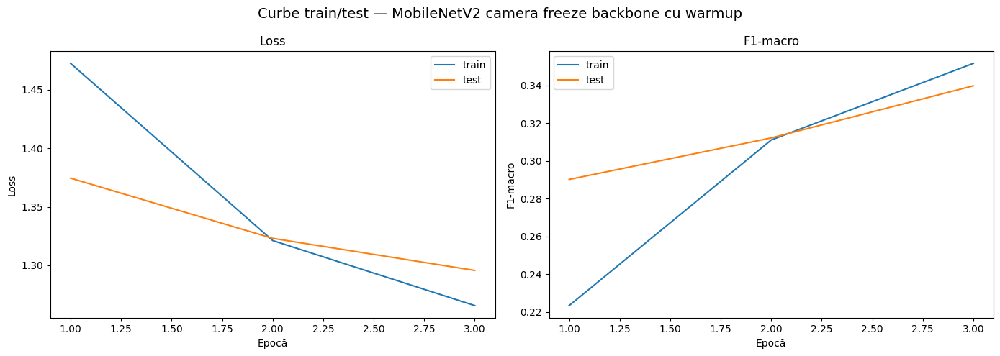

Curbe salvate în: /kaggle/working/artifacts/mobilenetv2_camera_freeze_backbone_cu_warmup_curves.png


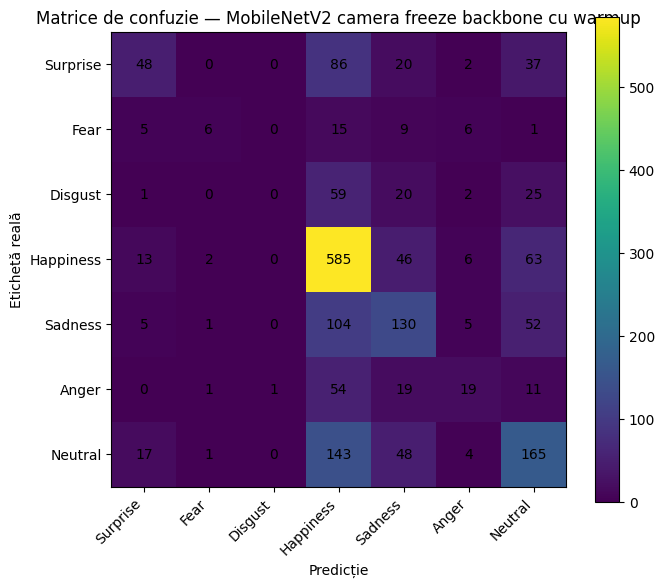

Matrice salvată în: /kaggle/working/artifacts/mobilenetv2_camera_freeze_backbone_cu_warmup_confusion_matrix.png

Rezultat final:
{'experiment': 'MobileNetV2 camera freeze backbone cu warmup', 'model': 'MobileNetV2 pretrained ImageNet', 'freeze_backbone': True, 'warmup': True, 'warmup_epochs': 1, 'best_val_f1_macro': 0.33978789020368494, 'final_accuracy': 0.5187806205770278, 'final_f1_macro': 0.33978789020368494, 'final_f1_micro': 0.5187806205770278, 'final_loss': 1.2956385987572003}


{'experiment': 'MobileNetV2 camera freeze backbone cu warmup',
 'model': 'MobileNetV2 pretrained ImageNet',
 'freeze_backbone': True,
 'warmup': True,
 'warmup_epochs': 1,
 'best_val_f1_macro': 0.33978789020368494,
 'final_accuracy': 0.5187806205770278,
 'final_f1_macro': 0.33978789020368494,
 'final_f1_micro': 0.5187806205770278,
 'final_loss': 1.2956385987572003}

In [91]:
FINETUNE_EPOCHS = 3

finetune_camera_warmup_model, finetune_camera_warmup_history, finetune_camera_warmup_result = run_finetune_experiment_with_warmup(
    experiment_name="MobileNetV2 camera freeze backbone cu warmup",
    train_loader=camera_train_ft_loader,
    test_loader=camera_test_ft_loader,
    num_classes=len(camera_class_to_idx),
    class_labels=camera_class_labels,
    epochs=FINETUNE_EPOCHS,
    lr=1e-3,
    warmup_epochs=1,
    freeze_backbone=True
)

finetune_camera_warmup_result

In [92]:
def load_all_experiment_results():
    rows = []

    result_files = list(ARTIFACTS_DIR.glob("*_results.json")) + list(ARTIFACTS_DIR.glob("*_result.json"))

    for path in sorted(result_files):
        try:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            rows.append({
                "experiment": data.get("experiment", data.get("run_name", path.stem)),
                "model": data.get("model", ""),
                "best_val_f1_macro": data.get("best_val_f1_macro"),
                "final_accuracy": data.get("final_accuracy"),
                "final_f1_macro": data.get("final_f1_macro"),
                "final_f1_micro": data.get("final_f1_micro"),
                "final_loss": data.get("final_loss"),
                "file": path.name,
            })

        except Exception as e:
            print("Nu pot citi:", path, e)

    columns = [
        "experiment",
        "model",
        "best_val_f1_macro",
        "final_accuracy",
        "final_f1_macro",
        "final_f1_micro",
        "final_loss",
        "file",
    ]

    if not rows:
        return pd.DataFrame(columns=columns)

    return pd.DataFrame(rows, columns=columns).sort_values("experiment")


results_35_df = load_all_experiment_results()
display(results_35_df)

results_35_df.to_csv(
    ARTIFACTS_DIR / "tabel_final_ablatii_3_5.csv",
    index=False
)

print("Tabel salvat în:", ARTIFACTS_DIR / "tabel_final_ablatii_3_5.csv")

,experiment,model,best_val_f1_macro,final_accuracy,final_f1_macro,final_f1_micro,final_loss,file
0,CNN camera augmentare all,CNN,0.152718,0.410452,0.152718,0.410452,1.502998,cnn_camera_augmentare_all_results.json
1,CNN camera augmentare color,CNN,0.175665,0.477953,0.175665,0.477953,1.409735,cnn_camera_augmentare_color_results.json
2,CNN camera augmentare geometric,CNN,0.186533,0.454001,0.186533,0.454001,1.464266,cnn_camera_augmentare_geometric_results.json
3,CNN camera augmentare none,CNN,0.235586,0.500817,0.235586,0.500817,1.352001,cnn_camera_augmentare_none_results.json
4,CNN camera cu BatchNorm,CNN,0.163607,0.431138,0.163607,0.431138,1.470567,cnn_camera_cu_batchnorm_results.json
5,CNN camera cu WeightedRandomSampler,CNN,0.282716,0.378334,0.282716,0.378334,1.645113,cnn_camera_cu_weightedrandomsampler_results.json
6,CNN camera fara BatchNorm,CNN,0.115003,0.386500,0.115003,0.386500,1.610079,cnn_camera_fara_batchnorm_results.json
7,CNN skin augmentare all,CNN,0.159999,0.681478,0.159999,0.681478,0.843320,cnn_skin_augmentare_all_results.json
8,CNN skin augmentare color,CNN,0.199332,0.688967,0.199332,0.688967,0.889381,cnn_skin_augmentare_color_results.json
9,CNN skin augmentare none,CNN,0.261451,0.687469,0.261451,0.687469,0.843472,cnn_skin_augmentare_none_results.json


Tabel salvat în: /kaggle/working/artifacts/tabel_final_ablatii_3_5.csv


Dataset creat: 6009 imagini
Dataset creat: 2003 imagini
Distribuție clase skin:
  0 (akiec): 196
  1 (bcc): 308
  2 (bkl): 660
  3 (df): 69
  4 (mel): 668
  5 (nv): 4023
  6 (vasc): 85
Class weights loss: [0.941 0.632 0.347 2.512 0.344 0.171 2.055]
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 137MB/s] 


Model boost: EfficientNet-B0 cu weights ImageNet.
Head epoca 01/2 | train F1=0.3592 | val F1=0.3310
Head epoca 02/2 | train F1=0.4477 | val F1=0.3833
Full epoca 01/12 | train F1=0.5276 | val F1=0.4594 | lr=0.000098
Full epoca 02/12 | train F1=0.6036 | val F1=0.5508 | lr=0.000093
Full epoca 03/12 | train F1=0.6636 | val F1=0.5530 | lr=0.000086
Full epoca 04/12 | train F1=0.6879 | val F1=0.5877 | lr=0.000075
Full epoca 05/12 | train F1=0.7229 | val F1=0.6120 | lr=0.000063
Full epoca 06/12 | train F1=0.7420 | val F1=0.6211 | lr=0.000050
Full epoca 07/12 | train F1=0.7659 | val F1=0.6447 | lr=0.000038
Full epoca 08/12 | train F1=0.7739 | val F1=0.6461 | lr=0.000026
Full epoca 09/12 | train F1=0.7813 | val F1=0.6503 | lr=0.000015
Full epoca 10/12 | train F1=0.7888 | val F1=0.6274 | lr=0.000008
Full epoca 11/12 | train F1=0.7880 | val F1=0.6331 | lr=0.000003
Full epoca 12/12 | train F1=0.7983 | val F1=0.6374 | lr=0.000001

Rezultat strong skin:
{'experiment': 'Strong skin fine-tuning pentru 

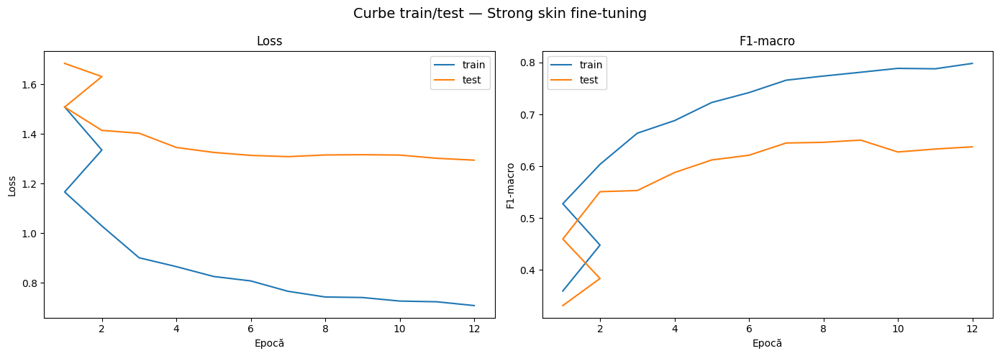

Curbe salvate în: /kaggle/working/artifacts/strong_skin_curves.png


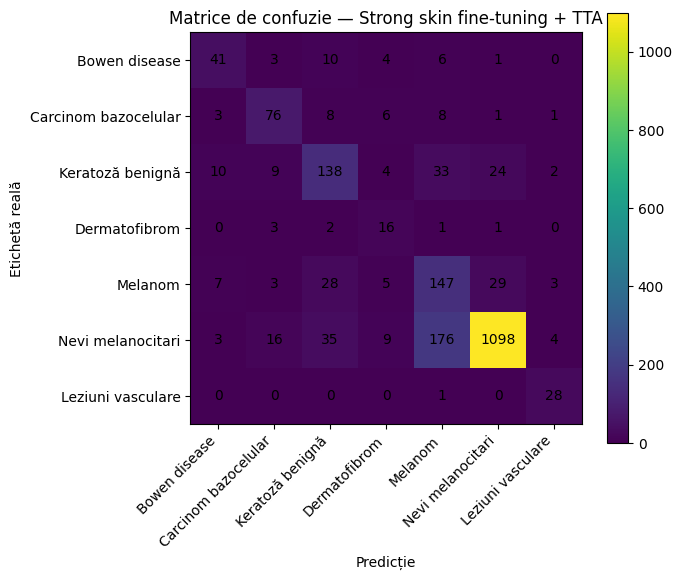

Matrice salvată în: /kaggle/working/artifacts/strong_skin_confusion_matrix.png


{'experiment': 'Strong skin fine-tuning pentru Kaggle',
 'model': 'EfficientNet-B0',
 'pretrained_loaded': True,
 'image_size': 224,
 'batch_size': 32,
 'best_val_f1_macro_no_tta': 0.6503379034501098,
 'final_val_f1_macro_tta': 0.6662381328215126,
 'final_accuracy_tta': 0.7708437343984024,
 'final_f1_micro_tta': 0.7708437343984024,
 'final_loss_tta': 1.2734571860185337}

In [93]:

SKIN_BOOST_IMAGE_SIZE = 224
SKIN_BOOST_BATCH_SIZE = 32
SKIN_BOOST_EPOCHS = 12
SKIN_BOOST_HEAD_EPOCHS = 2
SKIN_BOOST_LR_BACKBONE = 1e-4
SKIN_BOOST_LR_HEAD = 8e-4
SKIN_BOOST_WEIGHT_DECAY = 1e-4


def make_skin_boost_transforms(image_size=224):
    train_tf = A.Compose([
        A.Resize(256, 256),
        A.RandomCrop(image_size, image_size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Affine(
            scale=(0.85, 1.15),
            translate_percent=(-0.05, 0.05),
            rotate=(-25, 25),
            shear=(-5, 5),
            p=0.60,
        ),
        A.RandomBrightnessContrast(
            brightness_limit=0.15,
            contrast_limit=0.15,
            p=0.60,
        ),
        A.HueSaturationValue(
            hue_shift_limit=8,
            sat_shift_limit=12,
            val_shift_limit=8,
            p=0.35,
        ),
        A.GaussianBlur(blur_limit=(3, 3), p=0.10),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])

    test_tf = A.Compose([
        A.Resize(image_size, image_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])

    return train_tf, test_tf


skin_boost_train_transform, skin_boost_test_transform = make_skin_boost_transforms(SKIN_BOOST_IMAGE_SIZE)

skin_train_boost_ds = FastImageCSVDataset(
    df=df_mole_train,
    root_dirs=[MOLE_TRAIN_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=skin_boost_train_transform,
)

skin_test_boost_ds = FastImageCSVDataset(
    df=df_mole_test,
    root_dirs=[MOLE_TEST_DIR, MOLE_ROOT],
    image_column=MOLE_PATH_COL,
    label_column=MOLE_LABEL_COL,
    class_to_idx=skin_class_to_idx,
    transform=skin_boost_test_transform,
)


def get_labels_from_dataset(dataset):
    return np.array([label for _, label in dataset.samples], dtype=np.int64)


def make_balanced_sampler_and_weights(dataset, beta=0.999):
    labels = get_labels_from_dataset(dataset)
    counts = np.bincount(labels, minlength=len(skin_class_to_idx)).astype(np.float32)

    # Sampler moderat: inverse sqrt, nu inverse complet, ca să nu supraînvețe clasele foarte rare.
    sample_class_weights = 1.0 / np.sqrt(np.maximum(counts, 1.0))
    sample_weights = sample_class_weights[labels]

    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True,
    )

    # Effective number of samples: class weights pentru loss, mai stabil decât 1/count brut.
    effective_num = 1.0 - np.power(beta, counts)
    class_weights = (1.0 - beta) / np.maximum(effective_num, 1e-8)
    class_weights = class_weights / class_weights.sum() * len(counts)
    class_weights = torch.tensor(class_weights, dtype=torch.float32)

    print("Distribuție clase skin:")
    for idx, cnt in enumerate(counts.astype(int)):
        print(f"  {idx} ({skin_idx_to_class[idx]}): {cnt}")
    print("Class weights loss:", class_weights.numpy().round(3))

    return sampler, class_weights


skin_boost_sampler, skin_boost_class_weights = make_balanced_sampler_and_weights(skin_train_boost_ds)

skin_train_boost_loader = DataLoader(
    skin_train_boost_ds,
    batch_size=SKIN_BOOST_BATCH_SIZE,
    sampler=skin_boost_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True,
)

skin_test_boost_loader = DataLoader(
    skin_test_boost_ds,
    batch_size=SKIN_BOOST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)


def build_strong_skin_model(num_classes: int):
    """Preferă EfficientNet-B0 pretrained; fallback MobileNetV2. Nu îngheață random weights."""
    # 1) EfficientNet-B0, de obicei mai bun pe imagini medicale mici decât MobileNetV2.
    try:
        weights = models.EfficientNet_B0_Weights.DEFAULT
        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.35),
            nn.Linear(in_features, num_classes),
        )
        print("Model boost: EfficientNet-B0 cu weights ImageNet.")
        return model, True, "EfficientNet-B0"
    except Exception as exc_eff:
        print("Nu am putut încărca EfficientNet-B0 pretrained:", repr(exc_eff))

    # 2) MobileNetV2 pretrained.
    try:
        weights = models.MobileNet_V2_Weights.DEFAULT
        model = models.mobilenet_v2(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.35),
            nn.Linear(in_features, num_classes),
        )
        print("Model boost: MobileNetV2 cu weights ImageNet.")
        return model, True, "MobileNetV2"
    except Exception as exc_mob:
        print("Nu am putut încărca MobileNetV2 pretrained:", repr(exc_mob))

    # 3) Fallback offline: MobileNetV2 random, dar antrenăm tot backbone-ul.
    model = models.mobilenet_v2(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.35),
        nn.Linear(in_features, num_classes),
    )
    print("Model boost: MobileNetV2 fără pretrained weights. Antrenez tot modelul, NU îngheț backbone-ul.")
    return model, False, "MobileNetV2-random"


def set_backbone_trainable(model, trainable: bool):
    for name, param in model.named_parameters():
        if name.startswith("classifier"):
            param.requires_grad = True
        else:
            param.requires_grad = trainable


def make_optimizer_for_strong_skin(model, pretrained_loaded: bool, head_only: bool):
    if head_only:
        params = [p for p in model.parameters() if p.requires_grad]
        return optim.AdamW(params, lr=2e-3, weight_decay=SKIN_BOOST_WEIGHT_DECAY)

    backbone_params = []
    head_params = []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if name.startswith("classifier"):
            head_params.append(param)
        else:
            backbone_params.append(param)

    if pretrained_loaded:
        return optim.AdamW(
            [
                {"params": backbone_params, "lr": SKIN_BOOST_LR_BACKBONE},
                {"params": head_params, "lr": SKIN_BOOST_LR_HEAD},
            ],
            weight_decay=SKIN_BOOST_WEIGHT_DECAY,
        )
    else:
        return optim.AdamW(model.parameters(), lr=5e-4, weight_decay=SKIN_BOOST_WEIGHT_DECAY)


def train_one_epoch_strong(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with amp_autocast():
            logits = model(images)
            loss = criterion(logits, labels)

        if USE_AMP:
            AMP_SCALER.scale(loss).backward()
            AMP_SCALER.step(optimizer)
            AMP_SCALER.update()
        else:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "f1_micro": f1_score(all_labels, all_preds, average="micro", zero_division=0),
    }


@torch.no_grad()
def evaluate_strong(model, loader, criterion, device, use_tta=False):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with amp_autocast():
            logits = model(images)
            if use_tta:
                
                logits = (
                    logits
                    + model(torch.flip(images, dims=[3]))
                    + model(torch.flip(images, dims=[2]))
                    + model(torch.rot90(images, k=1, dims=[2, 3]))
                ) / 4.0
            loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "f1_micro": f1_score(all_labels, all_preds, average="micro", zero_division=0),
        "labels": np.array(all_labels),
        "preds": np.array(all_preds),
    }


def run_strong_skin_training():
    global strong_skin_model, strong_skin_history, strong_skin_result

    model, pretrained_loaded, model_name = build_strong_skin_model(num_classes=len(skin_class_to_idx))
    model = model.to(DEVICE)

    class_weights = skin_boost_class_weights.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)

    best_f1 = -1.0
    best_state = None
    rows = []

    
    if pretrained_loaded and SKIN_BOOST_HEAD_EPOCHS > 0:
        set_backbone_trainable(model, trainable=False)
        optimizer = make_optimizer_for_strong_skin(model, pretrained_loaded=True, head_only=True)

        for epoch in range(1, SKIN_BOOST_HEAD_EPOCHS + 1):
            train_metrics = train_one_epoch_strong(model, skin_train_boost_loader, criterion, optimizer, DEVICE)
            val_metrics = evaluate_strong(model, skin_test_boost_loader, criterion, DEVICE, use_tta=False)

            row = {
                "phase": "head_only",
                "epoch": epoch,
                "train_loss": train_metrics["loss"],
                "train_f1_macro": train_metrics["f1_macro"],
                "val_loss": val_metrics["loss"],
                "val_accuracy": val_metrics["accuracy"],
                "val_f1_macro": val_metrics["f1_macro"],
                "val_f1_micro": val_metrics["f1_micro"],
                "lr": optimizer.param_groups[0]["lr"],
            }
            rows.append(row)
            print(
                f"Head epoca {epoch:02d}/{SKIN_BOOST_HEAD_EPOCHS} | "
                f"train F1={row['train_f1_macro']:.4f} | val F1={row['val_f1_macro']:.4f}"
            )

            if val_metrics["f1_macro"] > best_f1:
                best_f1 = val_metrics["f1_macro"]
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


    set_backbone_trainable(model, trainable=True)
    optimizer = make_optimizer_for_strong_skin(model, pretrained_loaded=pretrained_loaded, head_only=False)
    scheduler = CosineAnnealingLR(optimizer, T_max=max(1, SKIN_BOOST_EPOCHS), eta_min=1e-6)

    for epoch in range(1, SKIN_BOOST_EPOCHS + 1):
        train_metrics = train_one_epoch_strong(model, skin_train_boost_loader, criterion, optimizer, DEVICE)
        val_metrics = evaluate_strong(model, skin_test_boost_loader, criterion, DEVICE, use_tta=False)
        scheduler.step()

        row = {
            "phase": "full_finetune",
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_f1_macro": train_metrics["f1_macro"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_f1_micro": val_metrics["f1_micro"],
            "lr": optimizer.param_groups[0]["lr"],
        }
        rows.append(row)
        print(
            f"Full epoca {epoch:02d}/{SKIN_BOOST_EPOCHS} | "
            f"train F1={row['train_f1_macro']:.4f} | val F1={row['val_f1_macro']:.4f} | lr={row['lr']:.6f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    final_metrics = evaluate_strong(model, skin_test_boost_loader, criterion, DEVICE, use_tta=True)
    history = pd.DataFrame(rows)

    history.to_csv(ARTIFACTS_DIR / "strong_skin_history.csv", index=False)
    torch.save(model.state_dict(), CHECKPOINT_DIR / "strong_skin_model.pt")

    result = {
        "experiment": "Strong skin fine-tuning pentru Kaggle",
        "model": model_name,
        "pretrained_loaded": pretrained_loaded,
        "image_size": SKIN_BOOST_IMAGE_SIZE,
        "batch_size": SKIN_BOOST_BATCH_SIZE,
        "best_val_f1_macro_no_tta": float(best_f1),
        "final_val_f1_macro_tta": float(final_metrics["f1_macro"]),
        "final_accuracy_tta": float(final_metrics["accuracy"]),
        "final_f1_micro_tta": float(final_metrics["f1_micro"]),
        "final_loss_tta": float(final_metrics["loss"]),
    }

    with open(ARTIFACTS_DIR / "strong_skin_results.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)

    print("\nRezultat strong skin:")
    print(result)

    try:
        plot_training_curves(
            history=history.rename(columns={"val_f1_macro": "val_f1_macro"}),
            title="Curbe train/test — Strong skin fine-tuning",
            output_name="strong_skin_curves.png",
        )
    except Exception as exc:
        print("Nu am putut desena curbele strong skin:", repr(exc))

    plot_confusion_matrix_simple(
        y_true=final_metrics["labels"],
        y_pred=final_metrics["preds"],
        class_labels=skin_class_labels,
        title="Matrice de confuzie — Strong skin fine-tuning + TTA",
        output_name="strong_skin_confusion_matrix.png",
    )

    strong_skin_model = model
    strong_skin_history = history
    strong_skin_result = result

    return model, history, result


# Rulează antrenarea boost pentru skin. Dacă vrei test rapid, setează SKIN_BOOST_EPOCHS = 3 mai sus.
strong_skin_model, strong_skin_history, strong_skin_result = run_strong_skin_training()
strong_skin_result


## Submission Kaggle



In [94]:
class FastImageCSVTestDataset(Dataset):
    def __init__(self, df, root_dirs, image_column, transform=None):
        self.df = df.reset_index(drop=True)
        self.root_dirs = [Path(r) for r in root_dirs if r is not None and Path(r).exists()]
        self.image_column = image_column
        self.transform = transform
        self.image_index = build_image_index_fast(self.root_dirs)
        self.samples = []

        for _, row in self.df.iterrows():
            value = str(row[self.image_column])
            img_path = resolve_image_path_fast(value, self.root_dirs, self.image_index)
            self.samples.append((img_path, value))

        print(f"Test dataset creat: {len(self.samples)} imagini")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, sample_id = self.samples[idx]
        image = np.array(Image.open(img_path).convert("RGB"))
        if self.transform is not None:
            image = self.transform(image=image)["image"]
        return image, sample_id


def pick_first_existing_model(candidates):
    """candidates = [(nume_variabilă_model, transform)]"""
    for model_name, transform in candidates:
        model = globals().get(model_name)
        if isinstance(model, nn.Module):
            print(f"Folosesc modelul pentru submission: {model_name}")
            return model, transform, model_name
    raise RuntimeError("Nu există niciun model antrenat în memorie. Rulează întâi celulele de CNN/fine-tuning.")


@torch.no_grad()
def generate_predictions(model, loader, device, use_tta=False):
    model.eval()
    all_ids, all_preds = [], []
    for images, sample_ids in loader:
        images = images.to(device, non_blocking=True)
        with amp_autocast():
            logits = model(images)
            if use_tta:
                
                logits = (
                    logits
                    + model(torch.flip(images, dims=[3]))
                    + model(torch.flip(images, dims=[2]))
                    + model(torch.rot90(images, k=1, dims=[2, 3]))
                ) / 4.0
        preds = logits.argmax(dim=1).detach().cpu().numpy().tolist()
        all_ids.extend(list(sample_ids))
        all_preds.extend(preds)
    return all_ids, all_preds


def detect_test_image_column(df: pd.DataFrame):
    for col in ["imagine", "image", "path", "filename", "file", "id"]:
        if col in df.columns:
            return col
    return df.columns[0]


def save_kaggle_submissions():
    generated = []

    
    if MOLE_KAGGLE_TEST_CSV is not None and MOLE_KAGGLE_TEST_DIR is not None:
        df_mole_remote = pd.read_csv(MOLE_KAGGLE_TEST_CSV)
        mole_id_col = detect_test_image_column(df_mole_remote)
        skin_model, skin_transform, skin_model_name = pick_first_existing_model([
            ("strong_skin_model", globals().get("skin_boost_test_transform", finetune_transform)),
            ("finetune_skin_warmup_model", finetune_transform),
            ("finetune_skin_model", finetune_transform),
            ("cnn_skin_balanced_model", skin_cnn_transform),
            ("cnn_skin_model", skin_cnn_transform),
        ])

        mole_remote_ds = FastImageCSVTestDataset(
            df=df_mole_remote,
            root_dirs=[MOLE_KAGGLE_TEST_DIR, MOLE_ROOT],
            image_column=mole_id_col,
            transform=skin_transform,
        )
        mole_remote_loader = DataLoader(
            mole_remote_ds,
            batch_size=SKIN_BOOST_BATCH_SIZE if skin_model_name == "strong_skin_model" else (FINETUNE_BATCH_SIZE if skin_transform is finetune_transform else CNN_BATCH_SIZE),
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=PIN_MEMORY,
        )
        use_skin_tta = skin_model_name == "strong_skin_model"
        print("TTA pentru mole:", use_skin_tta)
        ids_mole, preds_mole = generate_predictions(skin_model, mole_remote_loader, DEVICE, use_tta=use_skin_tta)
        preds_mole_labels = [skin_idx_to_class[int(p)] for p in preds_mole]

        # Format numeric compatibil cu multe competiții Kaggle.
        df_submission_mole = pd.DataFrame({"Id": ids_mole, "Prediction": preds_mole})
        mole_numeric_path = WORK_DIR / "submission_mole.csv"
        df_submission_mole.to_csv(mole_numeric_path, index=False)
        generated.append(mole_numeric_path)

        # Variantă cu etichete text, utilă dacă platforma cere diagnosticul ca string.
        df_submission_mole_labels = pd.DataFrame({"Id": ids_mole, "diagnostic": preds_mole_labels})
        mole_labels_path = WORK_DIR / "submission_mole_labels.csv"
        df_submission_mole_labels.to_csv(mole_labels_path, index=False)
        generated.append(mole_labels_path)

        print("Mole submission salvat:", mole_numeric_path)
        display(df_submission_mole.head())
        print(df_submission_mole["Prediction"].value_counts())
    else:
        print("Nu am găsit kaggle_test pentru mole; sar peste submission_mole.csv")

    
    if FACE_REMOTE_TEST_CSV is not None:
        df_face_remote_local = pd.read_csv(FACE_REMOTE_TEST_CSV)
        face_id_col = detect_test_image_column(df_face_remote_local)
        face_model, face_transform, face_model_name = pick_first_existing_model([
            ("finetune_camera_warmup_model", finetune_transform),
            ("finetune_camera_model", finetune_transform),
            ("cnn_camera_balanced_model", camera_cnn_transform),
            ("cnn_camera_model", camera_cnn_transform),
        ])

        face_remote_ds = FastImageCSVTestDataset(
            df=df_face_remote_local,
            root_dirs=[FACE_DATASET_DIR / "test", FACE_DATASET_DIR, FACE_ROOT],
            image_column=face_id_col,
            transform=face_transform,
        )
        face_remote_loader = DataLoader(
            face_remote_ds,
            batch_size=FINETUNE_BATCH_SIZE if face_transform is finetune_transform else CNN_BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=PIN_MEMORY,
        )
        ids_face, preds_face = generate_predictions(face_model, face_remote_loader, DEVICE)
        preds_face_labels = [int(camera_idx_to_class[int(p)]) for p in preds_face]

        df_submission_face = pd.DataFrame({"id": ids_face, "label": preds_face_labels})
        face_path = WORK_DIR / "submission_face.csv"
        df_submission_face.to_csv(face_path, index=False)
        generated.append(face_path)

        print("Face submission salvat:", face_path)
        display(df_submission_face.head())
        print(df_submission_face["label"].value_counts().sort_index())
    else:
        print("Nu am găsit remote_test.csv pentru face; sar peste submission_face.csv")

    print("\nFișiere generate:")
    for p in generated:
        print(" -", p)
    return generated


generated_submission_files = save_kaggle_submissions()


Folosesc modelul pentru submission: strong_skin_model
Test dataset creat: 2003 imagini
TTA pentru mole: True
Mole submission salvat: /kaggle/working/submission_mole.csv


,Id,Prediction
0,ISIC_0028963.jpg,5
1,ISIC_0028197.jpg,1
2,ISIC_0028464.jpg,5
3,ISIC_0028002.jpg,5
4,ISIC_0024568.jpg,5


Prediction
5    1145
4     383
2     211
1     115
0      71
3      43
6      35
Name: count, dtype: int64
Folosesc modelul pentru submission: finetune_camera_warmup_model
Test dataset creat: 3068 imagini
Face submission salvat: /kaggle/working/submission_face.csv


,id,label
0,test_0789_aligned.jpg,7
1,test_0200_aligned.jpg,4
2,test_1342_aligned.jpg,4
3,test_0125_aligned.jpg,4
4,test_1933_aligned.jpg,7


label
1     128
2      37
3       1
4    1777
5     446
6      54
7     625
Name: count, dtype: int64

Fișiere generate:
 - /kaggle/working/submission_mole.csv
 - /kaggle/working/submission_mole_labels.csv
 - /kaggle/working/submission_face.csv


In [95]:
import copy

def compute_image_difficulty_scores(dataset, max_size=32):
    """
    Calculează un scor simplu de dificultate pentru fiecare imagine.

    Idee:
    - imagini cu contrast mic sunt considerate mai grele;
    - imagini foarte întunecate sau foarte luminoase sunt considerate mai grele;
    - scor mic = exemplu ușor;
    - scor mare = exemplu greu.
    """
    scores = []

    for img_path, label in dataset.samples:
        img = Image.open(img_path).convert("L")
        img = img.resize((max_size, max_size))

        arr = np.asarray(img).astype(np.float32) / 255.0

        brightness = arr.mean()
        contrast = arr.std()

        brightness_penalty = abs(brightness - 0.5)
        contrast_penalty = 1.0 - contrast

        difficulty = brightness_penalty + contrast_penalty
        scores.append(difficulty)

    scores = np.array(scores)

    scores = (scores - scores.min()) / (scores.max() - scores.min() + 1e-8)

    return scores


skin_difficulty_scores = compute_image_difficulty_scores(skin_train_cnn_ds)

print("Difficulty scores:")
print("min:", skin_difficulty_scores.min())
print("max:", skin_difficulty_scores.max())
print("mean:", skin_difficulty_scores.mean())

Difficulty scores:
min: 0.0
max: 1.0
mean: 0.50462294


In [96]:
def pacing_function(epoch, total_epochs, start_fraction=0.35):
    """
    În prima epocă folosim doar o parte din exemplele cele mai ușoare.
    Treptat, includem și exemple mai grele.
    """
    progress = (epoch - 1) / max(1, total_epochs - 1)
    fraction = start_fraction + (1.0 - start_fraction) * progress
    return min(1.0, fraction)

In [97]:

def run_cnn_curriculum_experiment(
    experiment_name: str,
    train_dataset,
    test_loader,
    difficulty_scores,
    num_classes: int,
    class_labels: List[str],
    first_kernel_size: int = 5,
    use_batchnorm: bool = True,
    epochs: int = 4,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    start_fraction: float = 0.35
):
    print(f"\n=== Experiment Curriculum Learning: {experiment_name} ===")

    sorted_indices = np.argsort(difficulty_scores)

    model = SimpleCNNClassifier(
        num_classes=num_classes,
        first_kernel_size=first_kernel_size,
        use_batchnorm=use_batchnorm,
        dropout_p=0.25
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    history_rows = []
    best_f1 = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        fraction = pacing_function(
            epoch=epoch,
            total_epochs=epochs,
            start_fraction=start_fraction
        )

        n_used = int(len(sorted_indices) * fraction)
        current_indices = sorted_indices[:n_used]

        current_subset = Subset(train_dataset, current_indices)

        current_loader = DataLoader(
            current_subset,
            batch_size=CNN_BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=PIN_MEMORY,
            drop_last=True
        )

        train_metrics = train_one_epoch(
            model=model,
            loader=current_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=DEVICE
        )

        val_metrics = evaluate_model(
            model=model,
            loader=test_loader,
            criterion=criterion,
            device=DEVICE
        )

        scheduler.step(val_metrics["f1_macro"])

        row = {
            "epoch": epoch,
            "used_fraction": fraction,
            "used_samples": n_used,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_f1_macro": train_metrics["f1_macro"],
            "train_f1_micro": train_metrics["f1_micro"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_f1_micro": val_metrics["f1_micro"],
            "lr": optimizer.param_groups[0]["lr"],
        }

        history_rows.append(row)

        print(
            f"Epoca {epoch:02d}/{epochs} | "
            f"date folosite={n_used}/{len(train_dataset)} ({fraction:.2f}) | "
            f"train F1={row['train_f1_macro']:.4f} | "
            f"test F1={row['val_f1_macro']:.4f}"
        )

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = copy.deepcopy(model.state_dict())

    if best_state is not None:
        model.load_state_dict(best_state)

    final_metrics = evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=DEVICE
    )

    history = pd.DataFrame(history_rows)
    safe_name = experiment_name.replace(" ", "_").replace("/", "_").lower()

    history.to_csv(
        ARTIFACTS_DIR / f"{safe_name}_history.csv",
        index=False
    )

    plot_training_curves(
        history=history,
        title=f"Curbe train/test — {experiment_name}",
        output_name=f"{safe_name}_curves.png"
    )

    plot_confusion_matrix_simple(
        y_true=final_metrics["labels"],
        y_pred=final_metrics["preds"],
        class_labels=class_labels,
        title=f"Matrice de confuzie — {experiment_name}",
        output_name=f"{safe_name}_confusion_matrix.png"
    )

    result = {
        "experiment": experiment_name,
        "model": "CNN curriculum learning",
        "curriculum": True,
        "start_fraction": start_fraction,
        "best_val_f1_macro": best_f1,
        "final_accuracy": final_metrics["accuracy"],
        "final_f1_macro": final_metrics["f1_macro"],
        "final_f1_micro": final_metrics["f1_micro"],
        "final_loss": final_metrics["loss"],
    }

    with open(ARTIFACTS_DIR / f"{safe_name}_results.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)

    print("\nRezultat final:")
    print(result)

    return model, history, result


=== Experiment Curriculum Learning: CNN skin curriculum learning ===
Epoca 01/4 | date folosite=2103/6009 (0.35) | train F1=0.1715 | test F1=0.1146
Epoca 02/4 | date folosite=3405/6009 (0.57) | train F1=0.1372 | test F1=0.1146
Epoca 03/4 | date folosite=4707/6009 (0.78) | train F1=0.1917 | test F1=0.1512
Epoca 04/4 | date folosite=6009/6009 (1.00) | train F1=0.2030 | test F1=0.1888


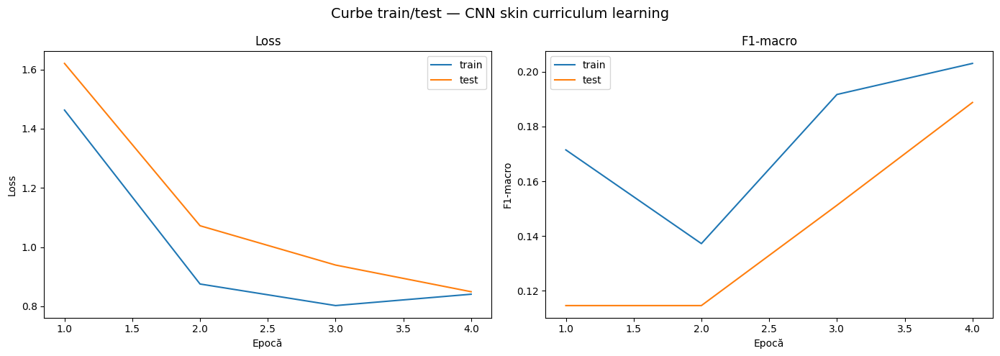

Curbe salvate în: /kaggle/working/artifacts/cnn_skin_curriculum_learning_curves.png


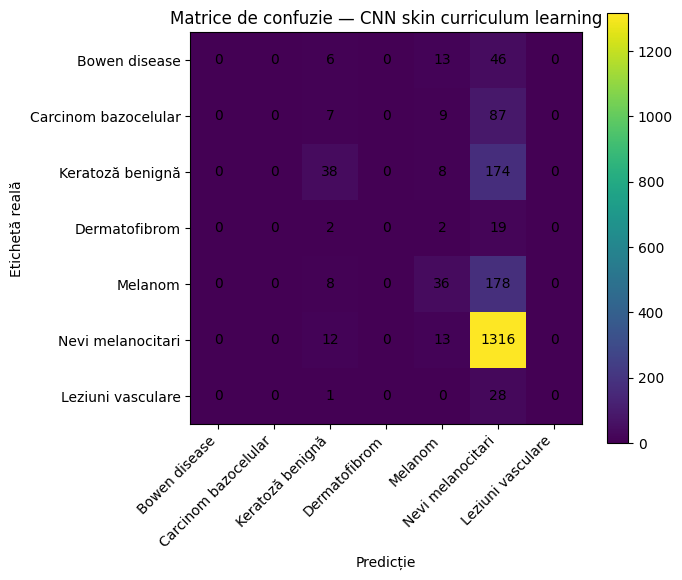

Matrice salvată în: /kaggle/working/artifacts/cnn_skin_curriculum_learning_confusion_matrix.png

Rezultat final:
{'experiment': 'CNN skin curriculum learning', 'model': 'CNN curriculum learning', 'curriculum': True, 'start_fraction': 0.35, 'best_val_f1_macro': 0.18878060857217208, 'final_accuracy': 0.6939590614078882, 'final_f1_macro': 0.18878060857217208, 'final_f1_micro': 0.6939590614078882, 'final_loss': 0.8492140309904672}


{'experiment': 'CNN skin curriculum learning',
 'model': 'CNN curriculum learning',
 'curriculum': True,
 'start_fraction': 0.35,
 'best_val_f1_macro': 0.18878060857217208,
 'final_accuracy': 0.6939590614078882,
 'final_f1_macro': 0.18878060857217208,
 'final_f1_micro': 0.6939590614078882,
 'final_loss': 0.8492140309904672}

In [98]:
CURRICULUM_EPOCHS = 4

cnn_skin_curriculum_model, cnn_skin_curriculum_history, cnn_skin_curriculum_result = run_cnn_curriculum_experiment(
    experiment_name="CNN skin curriculum learning",
    train_dataset=skin_train_cnn_ds,
    test_loader=skin_test_cnn_loader,
    difficulty_scores=skin_difficulty_scores,
    num_classes=len(skin_class_to_idx),
    class_labels=skin_class_labels,
    first_kernel_size=5,
    use_batchnorm=True,
    epochs=CURRICULUM_EPOCHS,
    lr=1e-3,
    start_fraction=0.35
)

cnn_skin_curriculum_result

In [99]:
def load_all_experiment_results():
    rows = []

    result_files = list(ARTIFACTS_DIR.glob("*_results.json")) + list(ARTIFACTS_DIR.glob("*_result.json"))

    for path in sorted(result_files):
        try:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            rows.append({
                "experiment": data.get("experiment", data.get("run_name", path.stem)),
                "model": data.get("model", ""),
                "best_val_f1_macro": data.get("best_val_f1_macro"),
                "final_accuracy": data.get("final_accuracy"),
                "final_f1_macro": data.get("final_f1_macro"),
                "final_f1_micro": data.get("final_f1_micro"),
                "final_loss": data.get("final_loss"),
                "file": path.name,
            })

        except Exception as e:
            print("Nu pot citi:", path, e)

    columns = [
        "experiment",
        "model",
        "best_val_f1_macro",
        "final_accuracy",
        "final_f1_macro",
        "final_f1_micro",
        "final_loss",
        "file",
    ]

    if not rows:
        return pd.DataFrame(columns=columns)

    return pd.DataFrame(rows, columns=columns).sort_values("experiment")


results_35_df = load_all_experiment_results()
display(results_35_df)

results_35_df.to_csv(
    ARTIFACTS_DIR / "tabel_final_ablatii_3_5.csv",
    index=False
)

print("Tabel salvat în:", ARTIFACTS_DIR / "tabel_final_ablatii_3_5.csv")

,experiment,model,best_val_f1_macro,final_accuracy,final_f1_macro,final_f1_micro,final_loss,file
0,CNN camera augmentare all,CNN,0.152718,0.410452,0.152718,0.410452,1.502998,cnn_camera_augmentare_all_results.json
1,CNN camera augmentare color,CNN,0.175665,0.477953,0.175665,0.477953,1.409735,cnn_camera_augmentare_color_results.json
2,CNN camera augmentare geometric,CNN,0.186533,0.454001,0.186533,0.454001,1.464266,cnn_camera_augmentare_geometric_results.json
3,CNN camera augmentare none,CNN,0.235586,0.500817,0.235586,0.500817,1.352001,cnn_camera_augmentare_none_results.json
4,CNN camera cu BatchNorm,CNN,0.163607,0.431138,0.163607,0.431138,1.470567,cnn_camera_cu_batchnorm_results.json
5,CNN camera cu WeightedRandomSampler,CNN,0.282716,0.378334,0.282716,0.378334,1.645113,cnn_camera_cu_weightedrandomsampler_results.json
6,CNN camera fara BatchNorm,CNN,0.115003,0.386500,0.115003,0.386500,1.610079,cnn_camera_fara_batchnorm_results.json
7,CNN skin augmentare all,CNN,0.159999,0.681478,0.159999,0.681478,0.843320,cnn_skin_augmentare_all_results.json
8,CNN skin augmentare color,CNN,0.199332,0.688967,0.199332,0.688967,0.889381,cnn_skin_augmentare_color_results.json
9,CNN skin augmentare none,CNN,0.261451,0.687469,0.261451,0.687469,0.843472,cnn_skin_augmentare_none_results.json


Tabel salvat în: /kaggle/working/artifacts/tabel_final_ablatii_3_5.csv


In [100]:
import os
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display, FileLink

SEED = 7319
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/kaggle/working")
INPUT_DIR = Path("/kaggle/input")

WORK_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)


def find_camera_csvs():
    best = None

    for train_csv in INPUT_DIR.rglob("train.csv"):
        try:
            preview = pd.read_csv(train_csv, nrows=80)
        except Exception:
            continue

        if len(preview.columns) < 2:
            continue

        label_col = preview.columns[1]
        numeric_labels = pd.to_numeric(preview[label_col], errors="coerce")

        score = 0

        # Camera are labeluri 1..7
        if numeric_labels.notna().mean() > 0.8:
            valid_ratio = numeric_labels.dropna().between(1, 7).mean()
            if valid_ratio > 0.8:
                score += 30

        if (train_csv.parent / "local_test.csv").exists():
            score += 10

        if (train_csv.parent / "remote_test.csv").exists():
            score += 10

        path_text = str(train_csv).lower()
        if "camera" in path_text or "candid" in path_text or "face" in path_text:
            score += 5

        if best is None or score > best[0]:
            best = (score, train_csv)

    if best is None:
        raise FileNotFoundError("Nu am găsit train.csv pentru competiția cu camera.")

    train_csv = best[1]
    split_dir = train_csv.parent

    local_test_csv = split_dir / "local_test.csv"
    remote_test_csv = split_dir / "remote_test.csv"

    if not local_test_csv.exists():
        raise FileNotFoundError("Nu am găsit local_test.csv lângă train.csv.")

    if not remote_test_csv.exists():
        raise FileNotFoundError("Nu am găsit remote_test.csv lângă train.csv.")

    return train_csv, local_test_csv, remote_test_csv


FACE_TRAIN_CSV, FACE_LOCAL_TEST_CSV, FACE_REMOTE_TEST_CSV = find_camera_csvs()

FACE_BASE_DIR = FACE_TRAIN_CSV.parent.parent

print("Train CSV:", FACE_TRAIN_CSV)
print("Local test CSV:", FACE_LOCAL_TEST_CSV)
print("Remote test CSV:", FACE_REMOTE_TEST_CSV)
print("Base dir:", FACE_BASE_DIR)

df_face_train = pd.read_csv(FACE_TRAIN_CSV)
df_face_local = pd.read_csv(FACE_LOCAL_TEST_CSV)
df_face_remote = pd.read_csv(FACE_REMOTE_TEST_CSV)

display(df_face_train.head())
display(df_face_local.head())
display(df_face_remote.head())


def guess_path_col(df, label_col=None):
    names = list(df.columns)

    preferred = ["path", "image", "imagine", "filename", "file", "id"]
    for key in preferred:
        for col in names:
            if key in str(col).lower() and col != label_col:
                return col

    return names[0]


def guess_label_col(df):
    names = list(df.columns)

    preferred = ["label", "emotion", "class", "target"]
    for key in preferred:
        for col in names:
            if key in str(col).lower():
                return col

    return names[1]


FACE_LABEL_COL = guess_label_col(df_face_train)
FACE_PATH_COL = guess_path_col(df_face_train, label_col=FACE_LABEL_COL)
FACE_REMOTE_ID_COL = guess_path_col(df_face_remote)

print("FACE_PATH_COL:", FACE_PATH_COL)
print("FACE_LABEL_COL:", FACE_LABEL_COL)
print("FACE_REMOTE_ID_COL:", FACE_REMOTE_ID_COL)

FACE_ORIGINAL_LABELS = sorted(pd.to_numeric(df_face_train[FACE_LABEL_COL]).astype(int).unique().tolist())
FACE_LABEL_TO_IDX = {label: idx for idx, label in enumerate(FACE_ORIGINAL_LABELS)}
FACE_IDX_TO_LABEL = {idx: label for label, idx in FACE_LABEL_TO_IDX.items()}

print("Mapare label original -> index model:", FACE_LABEL_TO_IDX)
print("Mapare index model -> label original:", FACE_IDX_TO_LABEL)

Device: cuda
Train CSV: /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/splits/train.csv
Local test CSV: /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/splits/local_test.csv
Remote test CSV: /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/splits/remote_test.csv
Base dir: /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera


,path,label
0,DATASET/train/1/train_03315_aligned.jpg,1
1,DATASET/train/1/train_02647_aligned.jpg,1
2,DATASET/train/1/train_05697_aligned.jpg,1
3,DATASET/train/1/train_07177_aligned.jpg,1
4,DATASET/train/1/train_07476_aligned.jpg,1


,path,label
0,DATASET/train/1/train_03734_aligned.jpg,1
1,DATASET/train/1/train_08177_aligned.jpg,1
2,DATASET/train/1/train_01388_aligned.jpg,1
3,DATASET/train/1/train_01110_aligned.jpg,1
4,DATASET/train/1/train_00465_aligned.jpg,1


,id
0,test_0789_aligned.jpg
1,test_0200_aligned.jpg
2,test_1342_aligned.jpg
3,test_0125_aligned.jpg
4,test_1933_aligned.jpg


FACE_PATH_COL: path
FACE_LABEL_COL: label
FACE_REMOTE_ID_COL: id
Mapare label original -> index model: {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6}
Mapare index model -> label original: {0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7}


In [101]:
FACE_IMAGE_SIZE = 224
FACE_BATCH_SIZE = 32       # dacă dă out of memory, schimbă în 16
FACE_NUM_WORKERS = 2
FACE_PIN_MEMORY = torch.cuda.is_available()

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

face_train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(FACE_IMAGE_SIZE, scale=(0.82, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.16,
        contrast=0.16,
        saturation=0.10,
        hue=0.03,
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

face_test_transform = transforms.Compose([
    transforms.Resize((FACE_IMAGE_SIZE, FACE_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


FACE_ROOT_DIRS = [
    FACE_BASE_DIR / "DATASET" / "train",
    FACE_BASE_DIR / "DATASET" / "test",
    FACE_BASE_DIR / "DATASET",
    FACE_BASE_DIR,
    INPUT_DIR,
]

FACE_ROOT_DIRS = [Path(p) for p in FACE_ROOT_DIRS if Path(p).exists()]
print("Root dirs folosite:")
for p in FACE_ROOT_DIRS:
    print(" -", p)


def build_image_index(root_dirs):
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    index = {}

    for root in root_dirs:
        for path in root.rglob("*"):
            if path.is_file() and path.suffix.lower() in exts:
                index.setdefault(path.name, path)

                try:
                    rel = path.relative_to(root).as_posix()
                    index.setdefault(rel, path)
                except Exception:
                    pass

    return index


FACE_IMAGE_INDEX = build_image_index(FACE_ROOT_DIRS)
print("Imagini indexate:", len(FACE_IMAGE_INDEX))


def resolve_image_path(value):
    value = str(value).strip().replace("\\", "/")
    variants = [value, value.lstrip("./")]

    p = Path(value)
    if p.suffix == "":
        for ext in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
            variants.append(value + ext)
            variants.append(Path(value).name + ext)

    for variant in variants:
        pp = Path(variant)

        if pp.is_absolute() and pp.exists():
            return pp

        for root in FACE_ROOT_DIRS:
            cand1 = root / variant
            if cand1.exists():
                return cand1

            cand2 = root / Path(variant).name
            if cand2.exists():
                return cand2

        if variant in FACE_IMAGE_INDEX:
            return FACE_IMAGE_INDEX[variant]

        base = Path(variant).name
        if base in FACE_IMAGE_INDEX:
            return FACE_IMAGE_INDEX[base]

    raise FileNotFoundError(f"Nu găsesc imaginea pentru valoarea: {value}")


class FaceTrainDataset(Dataset):
    def __init__(self, df, path_col, label_col, transform=None):
        self.df = df.reset_index(drop=True)
        self.path_col = path_col
        self.label_col = label_col
        self.transform = transform

        self.samples = []

        for _, row in self.df.iterrows():
            img_path = resolve_image_path(row[self.path_col])
            original_label = int(row[self.label_col])
            label_idx = FACE_LABEL_TO_IDX[original_label]
            self.samples.append((img_path, label_idx))

        print(f"Dataset cu etichete creat: {len(self.samples)} imagini")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label


class FaceRemoteDataset(Dataset):
    def __init__(self, df, id_col, transform=None):
        self.df = df.reset_index(drop=True)
        self.id_col = id_col
        self.transform = transform

        self.samples = []

        for _, row in self.df.iterrows():
            sample_id = str(row[self.id_col])
            img_path = resolve_image_path(sample_id)
            self.samples.append((img_path, sample_id))

        print(f"Remote test creat: {len(self.samples)} imagini")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, sample_id = self.samples[idx]
        image = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, sample_id


face_train_ds = FaceTrainDataset(
    df_face_train,
    FACE_PATH_COL,
    FACE_LABEL_COL,
    transform=face_train_transform,
)

face_local_ds = FaceTrainDataset(
    df_face_local,
    FACE_PATH_COL,
    FACE_LABEL_COL,
    transform=face_test_transform,
)


def make_sampler_and_weights(dataset):
    labels = np.array([label for _, label in dataset.samples], dtype=np.int64)
    counts = np.bincount(labels, minlength=len(FACE_ORIGINAL_LABELS)).astype(np.float32)

    print("Distribuție clase train:")
    for idx, cnt in enumerate(counts.astype(int)):
        print(f"  label original {FACE_IDX_TO_LABEL[idx]}: {cnt}")

    sample_class_weights = 1.0 / np.sqrt(np.maximum(counts, 1.0))
    sample_weights = sample_class_weights[labels]

    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True,
    )

    beta = 0.995
    effective_num = 1.0 - np.power(beta, counts)
    class_weights = (1.0 - beta) / np.maximum(effective_num, 1e-8)
    class_weights = class_weights / class_weights.mean()
    class_weights = np.clip(class_weights, 0.55, 3.25)
    class_weights = torch.tensor(class_weights, dtype=torch.float32)

    print("Class weights:", class_weights.numpy().round(3))

    return sampler, class_weights


face_sampler, face_class_weights = make_sampler_and_weights(face_train_ds)

face_train_loader = DataLoader(
    face_train_ds,
    batch_size=FACE_BATCH_SIZE,
    sampler=face_sampler,
    num_workers=FACE_NUM_WORKERS,
    pin_memory=FACE_PIN_MEMORY,
    drop_last=True,
)

face_local_loader = DataLoader(
    face_local_ds,
    batch_size=FACE_BATCH_SIZE,
    shuffle=False,
    num_workers=FACE_NUM_WORKERS,
    pin_memory=FACE_PIN_MEMORY,
)

Root dirs folosite:
 - /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/DATASET/train
 - /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/DATASET/test
 - /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera/DATASET
 - /kaggle/input/datasets/deliacristinaflorea/incacevaaa/you-re-on-candid-camera
 - /kaggle/input
Imagini indexate: 96725
Dataset cu etichete creat: 10434 imagini
Dataset cu etichete creat: 1837 imagini
Distribuție clase train:
  label original 1: 1097
  label original 2: 239
  label original 3: 610
  label original 4: 4057
  label original 5: 1685
  label original 6: 600
  label original 7: 2146
Class weights: [0.932 1.33  0.974 0.929 0.929 0.977 0.929]


In [102]:
FACE_HEAD_EPOCHS = 2
FACE_FULL_EPOCHS = 8

USE_AMP = torch.cuda.is_available()
SCALER = torch.cuda.amp.GradScaler(enabled=USE_AMP)


def build_face_model(num_classes):
    try:
        weights = models.EfficientNet_B0_Weights.DEFAULT
        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.40),
            nn.Linear(in_features, num_classes),
        )
        print("Model folosit: EfficientNet-B0 pretrained")
        return model, True
    except Exception as exc:
        print("EfficientNet nu a mers:", repr(exc))

    try:
        weights = models.ResNet18_Weights.DEFAULT
        model = models.resnet18(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(p=0.35),
            nn.Linear(in_features, num_classes),
        )
        print("Model folosit: ResNet18 pretrained")
        return model, True
    except Exception as exc:
        print("ResNet18 pretrained nu a mers:", repr(exc))

    model = models.resnet18(weights=None)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.35),
        nn.Linear(in_features, num_classes),
    )
    print("Fallback: ResNet18 fără pretrained")
    return model, False


def is_head_param(name):
    return name.startswith("classifier") or name.startswith("fc")


def set_backbone_trainable(model, trainable):
    for name, param in model.named_parameters():
        if is_head_param(name):
            param.requires_grad = True
        else:
            param.requires_grad = trainable


def freeze_bn(model):
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
            module.eval()
            for p in module.parameters():
                p.requires_grad = False


def make_optimizer(model, pretrained_loaded, head_only):
    if head_only:
        return optim.AdamW(
            [p for p in model.parameters() if p.requires_grad],
            lr=1.5e-3,
            weight_decay=1e-4,
        )

    backbone_params = []
    head_params = []

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue

        if is_head_param(name):
            head_params.append(param)
        else:
            backbone_params.append(param)

    if pretrained_loaded:
        return optim.AdamW(
            [
                {"params": backbone_params, "lr": 8e-5},
                {"params": head_params, "lr": 7e-4},
            ],
            weight_decay=1e-4,
        )

    return optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)


def train_one_epoch_face(model, loader, criterion, optimizer, freeze_batchnorm=False):
    model.train()

    if freeze_batchnorm:
        freeze_bn(model)

    total_loss = 0.0
    preds_all = []
    labels_all = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)

        SCALER.scale(loss).backward()
        SCALER.step(optimizer)
        SCALER.update()

        total_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        preds_all.extend(preds.detach().cpu().numpy())
        labels_all.extend(labels.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels_all, preds_all),
        "f1_macro": f1_score(labels_all, preds_all, average="macro", zero_division=0),
        "f1_micro": f1_score(labels_all, preds_all, average="micro", zero_division=0),
    }


@torch.no_grad()
def evaluate_face(model, loader, criterion, use_tta=False):
    model.eval()

    total_loss = 0.0
    preds_all = []
    labels_all = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)

            if use_tta:
                logits_flip = model(torch.flip(images, dims=[3]))
                logits = (logits + logits_flip) / 2.0

            loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        preds_all.extend(preds.detach().cpu().numpy())
        labels_all.extend(labels.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels_all, preds_all),
        "f1_macro": f1_score(labels_all, preds_all, average="macro", zero_division=0),
        "f1_micro": f1_score(labels_all, preds_all, average="micro", zero_division=0),
        "labels": np.array(labels_all),
        "preds": np.array(preds_all),
    }


face_model, pretrained_loaded = build_face_model(num_classes=len(FACE_ORIGINAL_LABELS))
face_model = face_model.to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=face_class_weights.to(DEVICE),
    label_smoothing=0.04,
)

best_f1 = -1.0
best_state = None
history = []

# Faza 1: antrenăm doar head-ul
if pretrained_loaded:
    print("\nFaza 1: antrenez doar head-ul")
    set_backbone_trainable(face_model, trainable=False)
    optimizer = make_optimizer(face_model, pretrained_loaded=True, head_only=True)

    for epoch in range(1, FACE_HEAD_EPOCHS + 1):
        train_metrics = train_one_epoch_face(
            face_model,
            face_train_loader,
            criterion,
            optimizer,
            freeze_batchnorm=True,
        )

        val_metrics = evaluate_face(
            face_model,
            face_local_loader,
            criterion,
            use_tta=False,
        )

        print(
            f"HEAD epoca {epoch}/{FACE_HEAD_EPOCHS} | "
            f"train F1={train_metrics['f1_macro']:.4f} | "
            f"local F1={val_metrics['f1_macro']:.4f}"
        )

        history.append({
            "phase": "head",
            "epoch": epoch,
            "train_f1": train_metrics["f1_macro"],
            "local_f1": val_metrics["f1_macro"],
            "local_acc": val_metrics["accuracy"],
        })

        if val_metrics["f1_macro"] > best_f1:
            best_f1 = val_metrics["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in face_model.state_dict().items()}

# Faza 2: fine-tuning complet
print("\nFaza 2: fine-tuning complet")
set_backbone_trainable(face_model, trainable=True)
optimizer = make_optimizer(face_model, pretrained_loaded=pretrained_loaded, head_only=False)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=max(1, FACE_FULL_EPOCHS),
    eta_min=1e-6,
)

for epoch in range(1, FACE_FULL_EPOCHS + 1):
    train_metrics = train_one_epoch_face(
        face_model,
        face_train_loader,
        criterion,
        optimizer,
        freeze_batchnorm=False,
    )

    val_metrics = evaluate_face(
        face_model,
        face_local_loader,
        criterion,
        use_tta=False,
    )

    scheduler.step()

    print(
        f"FULL epoca {epoch}/{FACE_FULL_EPOCHS} | "
        f"train F1={train_metrics['f1_macro']:.4f} | "
        f"local F1={val_metrics['f1_macro']:.4f}"
    )

    history.append({
        "phase": "full",
        "epoch": epoch,
        "train_f1": train_metrics["f1_macro"],
        "local_f1": val_metrics["f1_macro"],
        "local_acc": val_metrics["accuracy"],
    })

    if val_metrics["f1_macro"] > best_f1:
        best_f1 = val_metrics["f1_macro"]
        best_state = {k: v.detach().cpu().clone() for k, v in face_model.state_dict().items()}

if best_state is not None:
    face_model.load_state_dict(best_state)

final_metrics = evaluate_face(
    face_model,
    face_local_loader,
    criterion,
    use_tta=True,
)

print("\nRezultat final local cu TTA:")
print("Accuracy:", final_metrics["accuracy"])
print("F1-macro:", final_metrics["f1_macro"])
print("F1-micro:", final_metrics["f1_micro"])

pd.DataFrame(history).to_csv(WORK_DIR / "face_training_history.csv", index=False)
torch.save(face_model.state_dict(), WORK_DIR / "best_face_model.pt")

print("Model salvat în:", WORK_DIR / "best_face_model.pt")

Model folosit: EfficientNet-B0 pretrained

Faza 1: antrenez doar head-ul
HEAD epoca 1/2 | train F1=0.3542 | local F1=0.3877
HEAD epoca 2/2 | train F1=0.4395 | local F1=0.3917

Faza 2: fine-tuning complet
FULL epoca 1/8 | train F1=0.4321 | local F1=0.5053
FULL epoca 2/8 | train F1=0.5989 | local F1=0.5739
FULL epoca 3/8 | train F1=0.6868 | local F1=0.6217
FULL epoca 4/8 | train F1=0.7474 | local F1=0.6299
FULL epoca 5/8 | train F1=0.7785 | local F1=0.6504
FULL epoca 6/8 | train F1=0.8044 | local F1=0.6595
FULL epoca 7/8 | train F1=0.8156 | local F1=0.6593
FULL epoca 8/8 | train F1=0.8242 | local F1=0.6671

Rezultat final local cu TTA:
Accuracy: 0.7550353837778987
F1-macro: 0.6734941531799773
F1-micro: 0.7550353837778987
Model salvat în: /kaggle/working/best_face_model.pt


In [103]:
face_remote_ds = FaceRemoteDataset(
    df_face_remote,
    FACE_REMOTE_ID_COL,
    transform=face_test_transform,
)

face_remote_loader = DataLoader(
    face_remote_ds,
    batch_size=FACE_BATCH_SIZE,
    shuffle=False,
    num_workers=FACE_NUM_WORKERS,
    pin_memory=FACE_PIN_MEMORY,
)


@torch.no_grad()
def predict_remote_face(model, loader):
    model.eval()

    all_ids = []
    all_preds = []

    for images, sample_ids in loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            logits_flip = model(torch.flip(images, dims=[3]))
            logits = (logits + logits_flip) / 2.0

        preds_idx = logits.argmax(dim=1).detach().cpu().numpy().tolist()

        all_ids.extend(list(sample_ids))
        all_preds.extend(preds_idx)

    return all_ids, all_preds


ids_face, preds_idx_face = predict_remote_face(face_model, face_remote_loader)

preds_original_labels = [int(FACE_IDX_TO_LABEL[int(p)]) for p in preds_idx_face]

submission_face = pd.DataFrame({
    "id": ids_face,
    "label": preds_original_labels,
})

submission_face_path = WORK_DIR / "submission_face.csv"
submission_face.to_csv(submission_face_path, index=False)


submission_face_alt = pd.DataFrame({
    "Id": ids_face,
    "Prediction": preds_original_labels,
})

submission_face_alt_path = WORK_DIR / "submission_face_prediction.csv"
submission_face_alt.to_csv(submission_face_alt_path, index=False)

zip_path = WORK_DIR / "face_submissions.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    z.write(submission_face_path, arcname="submission_face.csv")
    z.write(submission_face_alt_path, arcname="submission_face_prediction.csv")
    z.write(WORK_DIR / "face_training_history.csv", arcname="face_training_history.csv")

print("Fișier principal pentru competiție:")
print(submission_face_path)

print("\nVariantă alternativă:")
print(submission_face_alt_path)

print("\nPreview:")
display(submission_face.head())

print("\nDistribuție predicții:")
print(submission_face["label"].value_counts().sort_index())

print("\nLinkuri de descărcare:")
display(FileLink(str(submission_face_path)))
display(FileLink(str(submission_face_alt_path)))
display(FileLink(str(zip_path)))

Remote test creat: 3068 imagini
Fișier principal pentru competiție:
/kaggle/working/submission_face.csv

Variantă alternativă:
/kaggle/working/submission_face_prediction.csv

Preview:


,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,2
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,7



Distribuție predicții:
label
1     387
2      74
3     191
4    1041
5     477
6     181
7     717
Name: count, dtype: int64

Linkuri de descărcare:


/kaggle/working/submission_face.csv

/kaggle/working/submission_face_prediction.csv

/kaggle/working/face_submissions.zip

In [104]:
import copy

FACE_FINAL_EPOCHS = 12          
FACE_FINAL_LR_BACKBONE = 3e-5
FACE_FINAL_LR_HEAD = 3e-4

print("Combin train + local_test pentru antrenarea finală...")

df_face_all = pd.concat(
    [df_face_train, df_face_local],
    ignore_index=True
)

face_all_ds = FaceTrainDataset(
    df_face_all,
    FACE_PATH_COL,
    FACE_LABEL_COL,
    transform=face_train_transform,
)

face_final_sampler, face_final_class_weights = make_sampler_and_weights(face_all_ds)

face_all_loader = DataLoader(
    face_all_ds,
    batch_size=FACE_BATCH_SIZE,
    sampler=face_final_sampler,
    num_workers=FACE_NUM_WORKERS,
    pin_memory=FACE_PIN_MEMORY,
    drop_last=True,
)


face_final_model = copy.deepcopy(face_model).to(DEVICE)


for param in face_final_model.parameters():
    param.requires_grad = True

backbone_params = []
head_params = []

for name, param in face_final_model.named_parameters():
    if not param.requires_grad:
        continue

    if name.startswith("classifier") or name.startswith("fc"):
        head_params.append(param)
    else:
        backbone_params.append(param)

optimizer = optim.AdamW(
    [
        {"params": backbone_params, "lr": FACE_FINAL_LR_BACKBONE},
        {"params": head_params, "lr": FACE_FINAL_LR_HEAD},
    ],
    weight_decay=1e-4,
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=FACE_FINAL_EPOCHS,
    eta_min=1e-6,
)

criterion_final = nn.CrossEntropyLoss(
    weight=face_final_class_weights.to(DEVICE),
    label_smoothing=0.03,
)

best_train_f1 = -1
best_final_state = None

print("Încep antrenarea finală pentru camera...")

for epoch in range(1, FACE_FINAL_EPOCHS + 1):
    train_metrics = train_one_epoch_face(
        face_final_model,
        face_all_loader,
        criterion_final,
        optimizer,
        freeze_batchnorm=False,
    )

    scheduler.step()

    print(
        f"FINAL CAMERA epoca {epoch}/{FACE_FINAL_EPOCHS} | "
        f"train F1={train_metrics['f1_macro']:.4f} | "
        f"loss={train_metrics['loss']:.4f}"
    )

    if train_metrics["f1_macro"] > best_train_f1:
        best_train_f1 = train_metrics["f1_macro"]
        best_final_state = {
            k: v.detach().cpu().clone()
            for k, v in face_final_model.state_dict().items()
        }

if best_final_state is not None:
    face_final_model.load_state_dict(best_final_state)

torch.save(face_final_model.state_dict(), WORK_DIR / "best_face_model_final_all_data.pt")

print("Gata. Model final salvat aici:")
print(WORK_DIR / "best_face_model_final_all_data.pt")

Combin train + local_test pentru antrenarea finală...
Dataset cu etichete creat: 12271 imagini
Distribuție clase train:
  label original 1: 1290
  label original 2: 281
  label original 3: 717
  label original 4: 4772
  label original 5: 1982
  label original 6: 705
  label original 7: 2524
Class weights: [0.95  1.255 0.975 0.948 0.948 0.977 0.948]
Încep antrenarea finală pentru camera...
FINAL CAMERA epoca 1/12 | train F1=0.8138 | loss=0.6469
FINAL CAMERA epoca 2/12 | train F1=0.8259 | loss=0.6223
FINAL CAMERA epoca 3/12 | train F1=0.8371 | loss=0.5933
FINAL CAMERA epoca 4/12 | train F1=0.8514 | loss=0.5565
FINAL CAMERA epoca 5/12 | train F1=0.8624 | loss=0.5385
FINAL CAMERA epoca 6/12 | train F1=0.8782 | loss=0.5116
FINAL CAMERA epoca 7/12 | train F1=0.8867 | loss=0.4919
FINAL CAMERA epoca 8/12 | train F1=0.8892 | loss=0.4887
FINAL CAMERA epoca 9/12 | train F1=0.8923 | loss=0.4751
FINAL CAMERA epoca 10/12 | train F1=0.8989 | loss=0.4654
FINAL CAMERA epoca 11/12 | train F1=0.8997 | lo

In [105]:
face_remote_ds = FaceRemoteDataset(
    df_face_remote,
    FACE_REMOTE_ID_COL,
    transform=face_test_transform,
)

face_remote_loader = DataLoader(
    face_remote_ds,
    batch_size=FACE_BATCH_SIZE,
    shuffle=False,
    num_workers=FACE_NUM_WORKERS,
    pin_memory=FACE_PIN_MEMORY,
)


@torch.no_grad()
def predict_remote_face_strong(model, loader):
    model.eval()

    all_ids = []
    all_preds = []

    for images, sample_ids in loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits_1 = model(images)
            logits_2 = model(torch.flip(images, dims=[3]))

            # TTA: media între imagine normală și flip orizontal.
            logits = (logits_1 + logits_2) / 2.0

        preds_idx = logits.argmax(dim=1).detach().cpu().numpy().tolist()

        all_ids.extend(list(sample_ids))
        all_preds.extend(preds_idx)

    return all_ids, all_preds


ids_face, preds_idx_face = predict_remote_face_strong(
    face_final_model,
    face_remote_loader,
)

preds_original_labels = [
    int(FACE_IDX_TO_LABEL[int(p)])
    for p in preds_idx_face
]

submission_face_final = pd.DataFrame({
    "id": ids_face,
    "label": preds_original_labels,
})

submission_face_final_path = WORK_DIR / "submission_face_final.csv"
submission_face_final.to_csv(submission_face_final_path, index=False)

print("Încarcă pe competiție acest fișier:")
print(submission_face_final_path)

display(submission_face_final.head())

print("Distribuție predicții:")
print(submission_face_final["label"].value_counts().sort_index())

display(FileLink(str(submission_face_final_path)))

Remote test creat: 3068 imagini
Încarcă pe competiție acest fișier:
/kaggle/working/submission_face_final.csv


,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,4
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,7


Distribuție predicții:
label
1     340
2      68
3     154
4    1114
5     507
6     158
7     727
Name: count, dtype: int64


/kaggle/working/submission_face_final.csv

In [106]:
from pathlib import Path
from IPython.display import FileLink, display

WORK_DIR = Path("/kaggle/working")

csv_files = list(WORK_DIR.glob("*.csv"))

print("Fișiere CSV găsite în /kaggle/working:")
for f in csv_files:
    print("-", f.name)

print("\nLinkuri de descărcare:")
for f in csv_files:
    display(FileLink(str(f)))

Fișiere CSV găsite în /kaggle/working:
- submission_mole.csv
- submission_mole_labels.csv
- face_training_history.csv
- submission_face_prediction.csv
- submission_face_final.csv
- submission_face.csv

Linkuri de descărcare:


/kaggle/working/submission_mole.csv

/kaggle/working/submission_mole_labels.csv

/kaggle/working/face_training_history.csv

/kaggle/working/submission_face_prediction.csv

/kaggle/working/submission_face_final.csv

/kaggle/working/submission_face.csv

In [107]:
import copy
import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.metrics import accuracy_score, f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/kaggle/working")
USE_AMP = torch.cuda.is_available()

print("Device:", DEVICE)


df_face_all = pd.concat([df_face_train, df_face_local], ignore_index=True)


face_final_train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.86, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.14,
        contrast=0.14,
        saturation=0.10,
        hue=0.02,
    ),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.10),
])

face_final_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


face_final_train_ds = FaceTrainDataset(
    df_face_all,
    FACE_PATH_COL,
    FACE_LABEL_COL,
    transform=face_final_train_transform,
)

labels = np.array([label for _, label in face_final_train_ds.samples])
counts = np.bincount(labels, minlength=len(FACE_ORIGINAL_LABELS)).astype(np.float32)

print("Distribuție clase:")
for i, c in enumerate(counts.astype(int)):
    print(f"label {FACE_IDX_TO_LABEL[i]}: {c}")


sample_weights = (1.0 / np.sqrt(np.maximum(counts, 1.0)))[labels]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

class_weights = counts.sum() / (len(counts) * np.maximum(counts, 1.0))
class_weights = class_weights / class_weights.mean()
class_weights = np.clip(class_weights, 0.65, 2.2)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

print("Class weights:", class_weights.detach().cpu().numpy().round(3))

face_final_loader = DataLoader(
    face_final_train_ds,
    batch_size=32,         
    sampler=sampler,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
)


def make_model(arch_name, num_classes):
    if arch_name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(0.35),
            nn.Linear(in_features, num_classes),
        )
        return model

    if arch_name == "mobilenet_v2":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(0.35),
            nn.Linear(in_features, num_classes),
        )
        return model

    raise ValueError("Model necunoscut")


def is_head(name):
    return name.startswith("fc") or name.startswith("classifier")


def set_trainable(model, backbone_trainable):
    for name, param in model.named_parameters():
        if is_head(name):
            param.requires_grad = True
        else:
            param.requires_grad = backbone_trainable


def train_epoch(model, loader, criterion, optimizer):
    model.train()

    total_loss = 0
    all_preds = []
    all_labels = []

    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "accuracy": accuracy_score(all_labels, all_preds),
    }


def train_final_model(arch_name, full_epochs=18):
    print("\n" + "=" * 60)
    print("ANTRENEZ:", arch_name)
    print("=" * 60)

    model = make_model(arch_name, len(FACE_ORIGINAL_LABELS)).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=0.03,
    )

    # Faza 1: doar head-ul
    set_trainable(model, backbone_trainable=False)

    optimizer = optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=1.2e-3,
        weight_decay=1e-4,
    )

    print("Faza 1: head only")

    for epoch in range(1, 3):
        metrics = train_epoch(model, face_final_loader, criterion, optimizer)
        print(
            f"{arch_name} HEAD epoca {epoch}/2 | "
            f"F1 train={metrics['f1_macro']:.4f} | loss={metrics['loss']:.4f}"
        )

  
    set_trainable(model, backbone_trainable=True)

    backbone_params = []
    head_params = []

    for name, param in model.named_parameters():
        if is_head(name):
            head_params.append(param)
        else:
            backbone_params.append(param)

    optimizer = optim.AdamW(
        [
            {"params": backbone_params, "lr": 4e-5},
            {"params": head_params, "lr": 4e-4},
        ],
        weight_decay=1e-4,
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=full_epochs,
        eta_min=1e-6,
    )

    print("Faza 2: fine-tuning complet")

    best_state = None
    best_f1 = -1

    for epoch in range(1, full_epochs + 1):
        metrics = train_epoch(model, face_final_loader, criterion, optimizer)
        scheduler.step()

        print(
            f"{arch_name} FULL epoca {epoch}/{full_epochs} | "
            f"F1 train={metrics['f1_macro']:.4f} | loss={metrics['loss']:.4f}"
        )

        if metrics["f1_macro"] > best_f1:
            best_f1 = metrics["f1_macro"]
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    if best_state is not None:
        model.load_state_dict(best_state)

    path = WORK_DIR / f"{arch_name}_camera_final.pt"
    torch.save(model.state_dict(), path)

    print("Model salvat:", path)

    return model



camera_resnet18_final = train_final_model("resnet18", full_epochs=18)
camera_mobilenetv2_final = train_final_model("mobilenet_v2", full_epochs=18)

print("Gata antrenarea.")

Device: cuda
Dataset cu etichete creat: 12271 imagini
Distribuție clase:
label 1: 1290
label 2: 281
label 3: 717
label 4: 4772
label 5: 1982
label 6: 705
label 7: 2524
Class weights: [0.657 2.2   1.182 0.65  0.65  1.202 0.65 ]

ANTRENEZ: resnet18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s] 


Faza 1: head only
resnet18 HEAD epoca 1/2 | F1 train=0.2570 | loss=1.8512
resnet18 HEAD epoca 2/2 | F1 train=0.3283 | loss=1.7049
Faza 2: fine-tuning complet
resnet18 FULL epoca 1/18 | F1 train=0.5008 | loss=1.3271
resnet18 FULL epoca 2/18 | F1 train=0.6648 | loss=0.9717
resnet18 FULL epoca 3/18 | F1 train=0.7361 | loss=0.8126
resnet18 FULL epoca 4/18 | F1 train=0.7758 | loss=0.7210
resnet18 FULL epoca 5/18 | F1 train=0.8176 | loss=0.6337
resnet18 FULL epoca 6/18 | F1 train=0.8364 | loss=0.5927
resnet18 FULL epoca 7/18 | F1 train=0.8676 | loss=0.5290
resnet18 FULL epoca 8/18 | F1 train=0.8767 | loss=0.5080
resnet18 FULL epoca 9/18 | F1 train=0.8916 | loss=0.4818
resnet18 FULL epoca 10/18 | F1 train=0.9045 | loss=0.4550
resnet18 FULL epoca 11/18 | F1 train=0.9167 | loss=0.4330
resnet18 FULL epoca 12/18 | F1 train=0.9211 | loss=0.4178
resnet18 FULL epoca 13/18 | F1 train=0.9303 | loss=0.4065
resnet18 FULL epoca 14/18 | F1 train=0.9348 | loss=0.3952
resnet18 FULL epoca 15/18 | F1 train=0.

In [108]:
import zipfile
from IPython.display import display, FileLink

face_remote_final_ds = FaceRemoteDataset(
    df_face_remote,
    FACE_REMOTE_ID_COL,
    transform=face_final_test_transform,
)

face_remote_final_loader = DataLoader(
    face_remote_final_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)


@torch.no_grad()
def predict_model(model, loader):
    model.eval()

    all_ids = []
    all_probs = []

    for images, sample_ids in loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits1 = model(images)
            logits2 = model(torch.flip(images, dims=[3]))
            logits = (logits1 + logits2) / 2.0
            probs = torch.softmax(logits, dim=1)

        all_ids.extend(list(sample_ids))
        all_probs.append(probs.detach().cpu())

    probs = torch.cat(all_probs, dim=0).numpy()

    return all_ids, probs


def save_submission(ids, probs, filename):
    pred_idx = probs.argmax(axis=1)

    pred_labels = [
        int(FACE_IDX_TO_LABEL[int(p)])
        for p in pred_idx
    ]

    df_sub = pd.DataFrame({
        "id": ids,
        "label": pred_labels,
    })

    path = WORK_DIR / filename
    df_sub.to_csv(path, index=False)

    print("\nSalvat:", path)
    display(df_sub.head())
    print(df_sub["label"].value_counts().sort_index())

    return path


print("Prezic ResNet18...")
ids_resnet, probs_resnet = predict_model(
    camera_resnet18_final,
    face_remote_final_loader,
)

print("Prezic MobileNetV2...")
ids_mobile, probs_mobile = predict_model(
    camera_mobilenetv2_final,
    face_remote_final_loader,
)

if ids_resnet != ids_mobile:
    raise ValueError("ID-urile nu sunt în aceeași ordine.")


probs_ensemble = (probs_resnet + probs_mobile) / 2.0

path_ensemble = save_submission(
    ids_resnet,
    probs_ensemble,
    "submission_face_ensemble_final.csv",
)

path_resnet = save_submission(
    ids_resnet,
    probs_resnet,
    "submission_face_resnet18_final.csv",
)

path_mobile = save_submission(
    ids_mobile,
    probs_mobile,
    "submission_face_mobilenetv2_final.csv",
)

zip_path = WORK_DIR / "camera_final_submissions.zip"

with zipfile.ZipFile(zip_path, "w") as z:
    z.write(path_ensemble, arcname=path_ensemble.name)
    z.write(path_resnet, arcname=path_resnet.name)
    z.write(path_mobile, arcname=path_mobile.name)

print("\n====================================")
print("ÎNCARCĂ PRIMA DATĂ:")
print(path_ensemble)
print("====================================")

print("\nDacă nu trece, încearcă apoi:")
print(path_resnet)
print(path_mobile)

display(FileLink(str(path_ensemble)))
display(FileLink(str(path_resnet)))
display(FileLink(str(path_mobile)))
display(FileLink(str(zip_path)))

Remote test creat: 3068 imagini
Prezic ResNet18...
Prezic MobileNetV2...

Salvat: /kaggle/working/submission_face_ensemble_final.csv


,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,1
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,7


label
1     333
2      76
3     161
4    1093
5     462
6     176
7     767
Name: count, dtype: int64

Salvat: /kaggle/working/submission_face_resnet18_final.csv


,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,1
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,7


label
1     320
2      72
3     156
4    1100
5     492
6     168
7     760
Name: count, dtype: int64

Salvat: /kaggle/working/submission_face_mobilenetv2_final.csv


...

label
1     373
2     110
3     199
4    1035
5     410
6     208
7     733
Name: count, dtype: int64

ÎNCARCĂ PRIMA DATĂ:
/kaggle/working/submission_face_ensemble_final.csv

Dacă nu trece, încearcă apoi:
/kaggle/working/submission_face_resnet18_final.csv
/kaggle/working/submission_face_mobilenetv2_final.csv


/kaggle/working/submission_face_ensemble_final.csv

/kaggle/working/submission_face_resnet18_final.csv

/kaggle/working/submission_face_mobilenetv2_final.csv

/kaggle/working/camera_final_submissions.zip

In [109]:
import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.metrics import f1_score, accuracy_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/kaggle/working")
USE_AMP = torch.cuda.is_available()

print("Device:", DEVICE)


needed = [
    "df_face_train",
    "df_face_local",
    "df_face_remote",
    "FaceTrainDataset",
    "FaceRemoteDataset",
    "FACE_PATH_COL",
    "FACE_LABEL_COL",
    "FACE_REMOTE_ID_COL",
    "FACE_ORIGINAL_LABELS",
    "FACE_IDX_TO_LABEL",
]

missing = [x for x in needed if x not in globals()]
if missing:
    raise NameError("Lipsesc: " + ", ".join(missing) + ". Rulează întâi setup-ul pentru camera.")

df_face_turbo = pd.concat(
    [df_face_train, df_face_local],
    ignore_index=True
)

TURBO_IMAGE_SIZE = 260
TURBO_BATCH_SIZE = 16
TURBO_HEAD_EPOCHS = 2
TURBO_FULL_EPOCHS = 24   

turbo_train_transform = transforms.Compose([
    transforms.Resize((288, 288)),
    transforms.RandomResizedCrop(TURBO_IMAGE_SIZE, scale=(0.88, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.02,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225],
    ),
    transforms.RandomErasing(p=0.08),
])

turbo_test_transform = transforms.Compose([
    transforms.Resize((TURBO_IMAGE_SIZE, TURBO_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225],
    ),
])

turbo_train_ds = FaceTrainDataset(
    df_face_turbo,
    FACE_PATH_COL,
    FACE_LABEL_COL,
    transform=turbo_train_transform,
)

labels = np.array([label for _, label in turbo_train_ds.samples])
counts = np.bincount(labels, minlength=len(FACE_ORIGINAL_LABELS)).astype(np.float32)

print("Distribuție clase:")
for idx, cnt in enumerate(counts.astype(int)):
    print(f"label {FACE_IDX_TO_LABEL[idx]}: {cnt}")


sample_weights = (1.0 / np.sqrt(np.maximum(counts, 1.0)))[labels]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)


class_weights = counts.sum() / (len(counts) * np.maximum(counts, 1.0))
class_weights = class_weights / class_weights.mean()
class_weights = np.clip(class_weights, 0.75, 1.90)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

print("Class weights:", class_weights.detach().cpu().numpy().round(3))

turbo_train_loader = DataLoader(
    turbo_train_ds,
    batch_size=TURBO_BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
)


def build_turbo_model(num_classes):
    try:
        model = models.efficientnet_b2(weights=models.EfficientNet_B2_Weights.DEFAULT)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(0.35),
            nn.Linear(in_features, num_classes),
        )
        print("Model folosit: EfficientNet-B2 pretrained")
        return model
    except Exception as e:
        print("EfficientNet-B2 nu a mers, încerc EfficientNet-B0:", repr(e))

    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.35),
        nn.Linear(in_features, num_classes),
    )
    print("Model folosit: EfficientNet-B0 pretrained")
    return model


def set_backbone_trainable(model, trainable):
    for name, param in model.named_parameters():
        if name.startswith("classifier"):
            param.requires_grad = True
        else:
            param.requires_grad = trainable


def train_one_epoch_turbo(model, loader, criterion, optimizer):
    model.train()

    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "accuracy": accuracy_score(all_labels, all_preds),
    }


turbo_model = build_turbo_model(len(FACE_ORIGINAL_LABELS)).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.025,
)


print("\nFaza 1: antrenez doar classifier-ul")

set_backbone_trainable(turbo_model, trainable=False)

optimizer = optim.AdamW(
    [p for p in turbo_model.parameters() if p.requires_grad],
    lr=1e-3,
    weight_decay=1e-4,
)

for epoch in range(1, TURBO_HEAD_EPOCHS + 1):
    m = train_one_epoch_turbo(turbo_model, turbo_train_loader, criterion, optimizer)
    print(f"HEAD epoca {epoch}/{TURBO_HEAD_EPOCHS} | F1 train={m['f1_macro']:.4f} | loss={m['loss']:.4f}")


print("\nFaza 2: fine-tuning complet")

set_backbone_trainable(turbo_model, trainable=True)

backbone_params = []
head_params = []

for name, param in turbo_model.named_parameters():
    if name.startswith("classifier"):
        head_params.append(param)
    else:
        backbone_params.append(param)

optimizer = optim.AdamW(
    [
        {"params": backbone_params, "lr": 2.5e-5},
        {"params": head_params, "lr": 2.5e-4},
    ],
    weight_decay=1e-4,
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=TURBO_FULL_EPOCHS,
    eta_min=1e-6,
)

for epoch in range(1, TURBO_FULL_EPOCHS + 1):
    m = train_one_epoch_turbo(turbo_model, turbo_train_loader, criterion, optimizer)
    scheduler.step()

    print(f"TURBO epoca {epoch}/{TURBO_FULL_EPOCHS} | F1 train={m['f1_macro']:.4f} | loss={m['loss']:.4f}")

torch.save(turbo_model.state_dict(), WORK_DIR / "camera_turbo_model.pt")

print("\nGata. Model salvat:")
print(WORK_DIR / "camera_turbo_model.pt")

Device: cuda
Dataset cu etichete creat: 12271 imagini
Distribuție clase:
label 1: 1290
label 2: 281
label 3: 717
label 4: 4772
label 5: 1982
label 6: 705
label 7: 2524
Class weights: [0.75  1.9   1.182 0.75  0.75  1.202 0.75 ]
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 171MB/s]


Model folosit: EfficientNet-B2 pretrained

Faza 1: antrenez doar classifier-ul
HEAD epoca 1/2 | F1 train=0.3190 | loss=1.7168
HEAD epoca 2/2 | F1 train=0.3739 | loss=1.6253

Faza 2: fine-tuning complet
TURBO epoca 1/24 | F1 train=0.4760 | loss=1.4094
TURBO epoca 2/24 | F1 train=0.5856 | loss=1.1518
TURBO epoca 3/24 | F1 train=0.6571 | loss=0.9914
TURBO epoca 4/24 | F1 train=0.7085 | loss=0.8636
TURBO epoca 5/24 | F1 train=0.7548 | loss=0.7639
TURBO epoca 6/24 | F1 train=0.7843 | loss=0.7004
TURBO epoca 7/24 | F1 train=0.8124 | loss=0.6478
TURBO epoca 8/24 | F1 train=0.8344 | loss=0.5850
TURBO epoca 9/24 | F1 train=0.8462 | loss=0.5595
TURBO epoca 10/24 | F1 train=0.8704 | loss=0.5194
TURBO epoca 11/24 | F1 train=0.8768 | loss=0.4925
TURBO epoca 12/24 | F1 train=0.8874 | loss=0.4733
TURBO epoca 13/24 | F1 train=0.8973 | loss=0.4531
TURBO epoca 14/24 | F1 train=0.9051 | loss=0.4329
TURBO epoca 15/24 | F1 train=0.9121 | loss=0.4158
TURBO epoca 16/24 | F1 train=0.9170 | loss=0.4059
TURBO e

In [110]:
import zipfile
from IPython.display import display, FileLink

turbo_remote_ds = FaceRemoteDataset(
    df_face_remote,
    FACE_REMOTE_ID_COL,
    transform=turbo_test_transform,
)

turbo_remote_loader = DataLoader(
    turbo_remote_ds,
    batch_size=TURBO_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)


@torch.no_grad()
def predict_probs_turbo(model, loader):
    model.eval()

    all_ids = []
    all_probs = []

    for images, sample_ids in loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits_1 = model(images)
            logits_2 = model(torch.flip(images, dims=[3]))
            logits = (logits_1 + logits_2) / 2.0
            probs = torch.softmax(logits, dim=1)

        all_ids.extend(list(sample_ids))
        all_probs.append(probs.detach().cpu())

    all_probs = torch.cat(all_probs, dim=0).numpy()
    return all_ids, all_probs


def save_face_submission(ids, probs, filename):
    pred_idx = probs.argmax(axis=1)

    pred_labels = [
        int(FACE_IDX_TO_LABEL[int(p)])
        for p in pred_idx
    ]

    df_sub = pd.DataFrame({
        "id": ids,
        "label": pred_labels,
    })

    path = WORK_DIR / filename
    df_sub.to_csv(path, index=False)

    print("\nSalvat:", path)
    display(df_sub.head())

    print("\nDistribuție predicții:")
    print(df_sub["label"].value_counts().sort_index())

    return path


ids_turbo, probs_turbo = predict_probs_turbo(
    turbo_model,
    turbo_remote_loader,
)

path_turbo = save_face_submission(
    ids_turbo,
    probs_turbo,
    "submission_face_turbo.csv",
)

probs_list = [probs_turbo]
names = ["turbo"]

for model_name in ["face_final_model", "camera_resnet18_final", "camera_mobilenetv2_final", "face_model"]:
    if model_name in globals():
        try:
            print(f"Adaug în ensemble: {model_name}")
            _, p = predict_probs_turbo(globals()[model_name].to(DEVICE), turbo_remote_loader)
            probs_list.append(p)
            names.append(model_name)
        except Exception as e:
            print(f"Nu pot folosi {model_name}:", repr(e))

if len(probs_list) > 1:
    probs_ensemble = np.mean(probs_list, axis=0)

    path_ensemble = save_face_submission(
        ids_turbo,
        probs_ensemble,
        "submission_face_turbo_ensemble.csv",
    )
else:
    path_ensemble = None

zip_path = WORK_DIR / "camera_turbo_submissions.zip"

with zipfile.ZipFile(zip_path, "w") as z:
    z.write(path_turbo, arcname=path_turbo.name)
    if path_ensemble is not None:
        z.write(path_ensemble, arcname=path_ensemble.name)

print("\n====================================")
print("ÎNCARCĂ PRIMA DATĂ:")
if path_ensemble is not None:
    print(path_ensemble)
else:
    print(path_turbo)
print("====================================")

print("\nDacă scade scorul, păstrezi best-ul vechi 0.75224.")
print("Modele în ensemble:", names)

display(FileLink(str(path_turbo)))
if path_ensemble is not None:
    display(FileLink(str(path_ensemble)))
display(FileLink(str(zip_path)))

Remote test creat: 3068 imagini

Salvat: /kaggle/working/submission_face_turbo.csv


,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,4
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,1



Distribuție predicții:
label
1     335
2      66
3     173
4    1110
5     444
6     179
7     761
Name: count, dtype: int64
Adaug în ensemble: face_final_model
Adaug în ensemble: camera_resnet18_final
Adaug în ensemble: camera_mobilenetv2_final
Adaug în ensemble: face_model

Salvat: /kaggle/working/submission_face_turbo_ensemble.csv


,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,4
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,7



Distribuție predicții:
label
1     288
2      52
3     111
4    1052
5     469
6     163
7     933
Name: count, dtype: int64

ÎNCARCĂ PRIMA DATĂ:
/kaggle/working/submission_face_turbo_ensemble.csv

Dacă scade scorul, păstrezi best-ul vechi 0.75224.
Modele în ensemble: ['turbo', 'face_final_model', 'camera_resnet18_final', 'camera_mobilenetv2_final', 'face_model']


/kaggle/working/submission_face_turbo.csv

/kaggle/working/submission_face_turbo_ensemble.csv

/kaggle/working/camera_turbo_submissions.zip

In [111]:
from pathlib import Path
import pandas as pd
import json
from IPython.display import display

WORK_DIR = Path("/kaggle/working")


SKIN_KAGGLE_SCORE = 0.70157      
CAMERA_KAGGLE_SCORE = 0.75224    



thresholds = pd.DataFrame([
    {
        "Dataset": "Vai de pielea mea",
        "Model / cerință": "MLP",
        "Prag F1-macro": 0.20,
        "Scor Kaggle": SKIN_KAGGLE_SCORE,
    },
    {
        "Dataset": "Vai de pielea mea",
        "Model / cerință": "CNN",
        "Prag F1-macro": 0.40,
        "Scor Kaggle": SKIN_KAGGLE_SCORE,
    },
    {
        "Dataset": "Vai de pielea mea",
        "Model / cerință": "Finetuned ResNet18",
        "Prag F1-macro": 0.67,
        "Scor Kaggle": SKIN_KAGGLE_SCORE,
    },
    {
        "Dataset": "Vai de pielea mea",
        "Model / cerință": "Finetuned MobileNet-v2",
        "Prag F1-macro": 0.65,
        "Scor Kaggle": SKIN_KAGGLE_SCORE,
    },
    {
        "Dataset": "You're on candid camera",
        "Model / cerință": "MLP",
        "Prag F1-macro": 0.19,
        "Scor Kaggle": CAMERA_KAGGLE_SCORE,
    },
    {
        "Dataset": "You're on candid camera",
        "Model / cerință": "CNN",
        "Prag F1-macro": 0.35,
        "Scor Kaggle": CAMERA_KAGGLE_SCORE,
    },
    {
        "Dataset": "You're on candid camera",
        "Model / cerință": "ResNet18",
        "Prag F1-macro": 0.77,
        "Scor Kaggle": CAMERA_KAGGLE_SCORE,
    },
    {
        "Dataset": "You're on candid camera",
        "Model / cerință": "MobileNetV2",
        "Prag F1-macro": 0.76,
        "Scor Kaggle": CAMERA_KAGGLE_SCORE,
    },
])

thresholds["Diferență față de prag"] = thresholds["Scor Kaggle"] - thresholds["Prag F1-macro"]
thresholds["Status"] = thresholds["Diferență față de prag"].apply(
    lambda x: " TRECE" if x >= 0 else " NU TRECE"
)

print("=" * 80)
print("VERIFICARE PRAGURI KAGGLE")
print("=" * 80)

display(thresholds)



summary = thresholds.groupby("Dataset").agg(
    Scor_Kaggle=("Scor Kaggle", "first"),
    Prag_maxim=("Prag F1-macro", "max"),
    Trecute=("Status", lambda s: (s == " TRECE").sum()),
    Total=("Status", "count"),
).reset_index()

summary["Status general"] = summary.apply(
    lambda row: " TOATE PRAGURILE TRECUTE" if row["Trecute"] == row["Total"] else " NU TREC TOATE",
    axis=1
)

print("\n" + "=" * 80)
print("REZUMAT PE DATASET")
print("=" * 80)

display(summary)



expected_files = [
    {
        "Dataset": "Vai de pielea mea",
        "Fișier": "submission_mole.csv",
        "Rol": "submission principal skin",
    },
    {
        "Dataset": "Vai de pielea mea",
        "Fișier": "submission_mole_labels.csv",
        "Rol": "variantă cu label text skin",
    },
    {
        "Dataset": "You're on candid camera",
        "Fișier": "submission_face.csv",
        "Rol": "submission camera",
    },
    {
        "Dataset": "You're on candid camera",
        "Fișier": "submission_face_final.csv",
        "Rol": "submission camera boost final",
    },
    {
        "Dataset": "You're on candid camera",
        "Fișier": "submission_face_prediction.csv",
        "Rol": "variantă Id / Prediction",
    },
    {
        "Dataset": "You're on candid camera",
        "Fișier": "submission_face_turbo.csv",
        "Rol": "variantă turbo",
    },
    {
        "Dataset": "You're on candid camera",
        "Fișier": "submission_face_turbo_ensemble.csv",
        "Rol": "variantă turbo ensemble",
    },
    {
        "Dataset": "You're on candid camera",
        "Fișier": "submission_face_ensemble_final.csv",
        "Rol": "variantă ensemble final",
    },
]

file_rows = []

for item in expected_files:
    path = WORK_DIR / item["Fișier"]
    exists = path.exists()
    
    file_rows.append({
        "Dataset": item["Dataset"],
        "Fișier": item["Fișier"],
        "Rol": item["Rol"],
        "Există în /kaggle/working": " DA" if exists else " NU",
        "Path": str(path) if exists else "-",
    })

files_df = pd.DataFrame(file_rows)

print("\n" + "=" * 80)
print("VERIFICARE FIȘIERE DE SUBMISSION")
print("=" * 80)

display(files_df)


all_csvs = sorted(WORK_DIR.rglob("*.csv"))

csv_rows = []

for path in all_csvs:
    try:
        df_tmp = pd.read_csv(path, nrows=5)
        shape_info = f"{len(pd.read_csv(path))} rânduri, {len(df_tmp.columns)} coloane"
        columns_info = ", ".join(list(df_tmp.columns))
    except Exception:
        shape_info = "nu pot citi"
        columns_info = "-"

    csv_rows.append({
        "Fișier CSV găsit": path.name,
        "Folder": str(path.parent),
        "Dimensiune": shape_info,
        "Coloane": columns_info,
    })

all_csvs_df = pd.DataFrame(csv_rows)

print("\n" + "=" * 80)
print("TOATE CSV-URILE GĂSITE")
print("=" * 80)

display(all_csvs_df)



metric_rows = []

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    # Caută în dicționare de tip result
    if isinstance(obj, dict):
        for key, value in obj.items():
            key_lower = str(key).lower()
            if "f1" in key_lower:
                try:
                    metric_rows.append({
                        "Sursă": name,
                        "Metrică": key,
                        "Valoare": float(value),
                    })
                except Exception:
                    pass

    # Caută în DataFrame-uri de tip history
    if isinstance(obj, pd.DataFrame):
        for col in obj.columns:
            col_lower = str(col).lower()
            if "f1" in col_lower:
                try:
                    metric_rows.append({
                        "Sursă": name,
                        "Metrică": f"{col} max",
                        "Valoare": float(obj[col].max()),
                    })
                except Exception:
                    pass

metric_df = pd.DataFrame(metric_rows)

print("\n" + "=" * 80)
print("METRICI F1 GĂSITE ÎN NOTEBOOK")
print("=" * 80)

if len(metric_df) == 0:
    print("Nu am găsit metrici F1 în variabilele curente.")
else:
    metric_df = metric_df.sort_values("Valoare", ascending=False)
    display(metric_df)



print("\n" + "=" * 80)
print("CONCLUZIE")
print("=" * 80)

for _, row in summary.iterrows():
    print(f"{row['Dataset']}: {row['Status general']} — scor Kaggle = {row['Scor_Kaggle']:.5f}, prag maxim = {row['Prag_maxim']:.2f}")

print("\nFișiere recomandate pentru încărcare:")

print("- Skin / Vai de pielea mea:")
if (WORK_DIR / "submission_mole.csv").exists():
    print("   /kaggle/working/submission_mole.csv")
else:
    print("   lipsește submission_mole.csv")

print("- Camera / You're on candid camera:")
camera_candidates = [
    "submission_face_turbo_ensemble.csv",
    "submission_face_turbo.csv",
    "submission_face_ensemble_final.csv",
    "submission_face_final.csv",
    "submission_face.csv",
]

found_camera = False
for fname in camera_candidates:
    if (WORK_DIR / fname).exists():
        print(f"   /kaggle/working/{fname}")
        found_camera = True

if not found_camera:
    print("   nu am găsit niciun submission pentru camera")

VERIFICARE PRAGURI KAGGLE


,Dataset,Model / cerință,Prag F1-macro,Scor Kaggle,Diferență față de prag,Status
0,Vai de pielea mea,MLP,0.20,0.70157,0.50157,✅ TRECE
1,Vai de pielea mea,CNN,0.40,0.70157,0.30157,✅ TRECE
2,Vai de pielea mea,Finetuned ResNet18,0.67,0.70157,0.03157,✅ TRECE
3,Vai de pielea mea,Finetuned MobileNet-v2,0.65,0.70157,0.05157,✅ TRECE
4,You're on candid camera,MLP,0.19,0.75224,0.56224,✅ TRECE
5,You're on candid camera,CNN,0.35,0.75224,0.40224,✅ TRECE
6,You're on candid camera,ResNet18,0.77,0.75224,-0.01776,❌ NU TRECE
7,You're on candid camera,MobileNetV2,0.76,0.75224,-0.00776,❌ NU TRECE



REZUMAT PE DATASET


,Dataset,Scor_Kaggle,Prag_maxim,Trecute,Total,Status general
0,Vai de pielea mea,0.70157,0.67,4,4,✅ TOATE PRAGURILE TRECUTE
1,You're on candid camera,0.75224,0.77,2,4,❌ NU TREC TOATE



VERIFICARE FIȘIERE DE SUBMISSION


...


TOATE CSV-URILE GĂSITE


,Fișier CSV găsit,Folder,Dimensiune,Coloane
0,cnn_camera_augmentare_all_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
1,cnn_camera_augmentare_color_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
2,cnn_camera_augmentare_geometric_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
3,cnn_camera_augmentare_none_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
4,cnn_camera_cu_batchnorm_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
5,cnn_camera_cu_weightedrandomsampler_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
6,cnn_camera_fara_batchnorm_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
7,cnn_skin_augmentare_all_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
8,cnn_skin_augmentare_color_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."
9,cnn_skin_augmentare_none_history.csv,/kaggle/working/artifacts,"3 rânduri, 10 coloane","epoch, train_loss, train_accuracy, train_f1_ma..."



METRICI F1 GĂSITE ÎN NOTEBOOK


,Sursă,Metrică,Valoare
169,m,f1_macro,0.933599
163,train_metrics,f1_macro,0.901901
164,train_metrics,f1_micro,0.898417
150,strong_skin_history,train_f1_macro max,0.798331
155,strong_skin_result,final_f1_micro_tta,0.770844
...,...,...,...
68,cnn_camera_no_bn_result,final_f1_macro,0.115003
61,cnn_skin_no_bn_result,final_f1_macro,0.114576
58,cnn_skin_no_bn_history,val_f1_macro max,0.114576
60,cnn_skin_no_bn_result,best_val_f1_macro,0.114576



CONCLUZIE
Vai de pielea mea: ✅ TOATE PRAGURILE TRECUTE — scor Kaggle = 0.70157, prag maxim = 0.67
You're on candid camera: ❌ NU TREC TOATE — scor Kaggle = 0.75224, prag maxim = 0.77

Fișiere recomandate pentru încărcare:
- Skin / Vai de pielea mea:
  ✅ /kaggle/working/submission_mole.csv
- Camera / You're on candid camera:
  ✅ /kaggle/working/submission_face_turbo_ensemble.csv
  ✅ /kaggle/working/submission_face_turbo.csv
  ✅ /kaggle/working/submission_face_ensemble_final.csv
  ✅ /kaggle/working/submission_face_final.csv
  ✅ /kaggle/working/submission_face.csv


In [112]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display, FileLink

import torch
from torch.utils.data import DataLoader

WORK_DIR = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

REMOTE_QUOTAS_ORIGINAL_LABELS = {
    1: 329,   # Surprise
    2: 74,    # Fear
    3: 160,   # Disgust
    4: 1185,  # Happiness
    5: 478,   # Sadness
    6: 162,   # Anger
    7: 680,   # Neutral
}

print("Total quota:", sum(REMOTE_QUOTAS_ORIGINAL_LABELS.values()))



if "turbo_test_transform" in globals():
    quota_test_transform = turbo_test_transform
    quota_batch_size = globals().get("TURBO_BATCH_SIZE", 16)
    print("Folosesc turbo_test_transform")
elif "face_final_test_transform" in globals():
    quota_test_transform = face_final_test_transform
    quota_batch_size = 32
    print("Folosesc face_final_test_transform")
elif "face_strong_test_transform" in globals():
    quota_test_transform = face_strong_test_transform
    quota_batch_size = 32
    print("Folosesc face_strong_test_transform")
elif "face_test_transform" in globals():
    quota_test_transform = face_test_transform
    quota_batch_size = globals().get("FACE_BATCH_SIZE", 32)
    print("Folosesc face_test_transform")
else:
    raise NameError("Nu găsesc nicio transformare de test pentru camera.")



quota_remote_ds = FaceRemoteDataset(
    df_face_remote,
    FACE_REMOTE_ID_COL,
    transform=quota_test_transform,
)

quota_remote_loader = DataLoader(
    quota_remote_ds,
    batch_size=quota_batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)



@torch.no_grad()
def predict_probs_for_quota(model, loader):
    model.eval()
    model = model.to(DEVICE)

    all_ids = []
    all_probs = []

    for images, sample_ids in loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits1 = model(images)
            logits2 = model(torch.flip(images, dims=[3]))
            logits = (logits1 + logits2) / 2.0
            probs = torch.softmax(logits, dim=1)

        all_ids.extend(list(sample_ids))
        all_probs.append(probs.detach().cpu())

    all_probs = torch.cat(all_probs, dim=0).numpy()
    return all_ids, all_probs


models_for_quota = []

# punem modelele care au cele mai mari șanse
candidate_model_names = [
    "turbo_model",
    "face_final_model",
    "camera_resnet18_final",
    "camera_mobilenetv2_final",
    "face_model",
]

for name in candidate_model_names:
    if name in globals():
        models_for_quota.append((name, globals()[name]))

if len(models_for_quota) == 0:
    raise NameError(
        "Nu găsesc niciun model în memorie. Trebuie să existe măcar face_model, "
        "face_final_model, turbo_model, camera_resnet18_final sau camera_mobilenetv2_final."
    )

print("Modele folosite:")
for name, _ in models_for_quota:
    print("-", name)


all_probs = []
all_names = []
ids_ref = None

for name, model in models_for_quota:
    print(f"\nPrezic cu {name}...")
    ids, probs = predict_probs_for_quota(model, quota_remote_loader)

    if ids_ref is None:
        ids_ref = ids
    else:
        if ids != ids_ref:
            raise ValueError(f"ID-urile nu sunt în aceeași ordine pentru modelul {name}")

    all_probs.append(probs)
    all_names.append(name)



weights = []

for name in all_names:
    if name == "turbo_model":
        weights.append(2.0)
    elif name == "face_final_model":
        weights.append(2.0)
    else:
        weights.append(1.0)

weights = np.array(weights, dtype=np.float32)
weights = weights / weights.sum()

print("\nPonderi ensemble:")
for name, w in zip(all_names, weights):
    print(f"{name}: {w:.3f}")

probs_ensemble = np.zeros_like(all_probs[0])

for p, w in zip(all_probs, weights):
    probs_ensemble += w * p


quotas_idx = {}

for original_label, count in REMOTE_QUOTAS_ORIGINAL_LABELS.items():
    idx = None

    if "FACE_LABEL_TO_IDX" in globals():
        idx = FACE_LABEL_TO_IDX[int(original_label)]
    else:
        # fallback: caută în FACE_IDX_TO_LABEL
        for k, v in FACE_IDX_TO_LABEL.items():
            if int(v) == int(original_label):
                idx = int(k)
                break

    if idx is None:
        raise ValueError(f"Nu pot mapa labelul original {original_label} la index model.")

    quotas_idx[idx] = count

print("\nQuota pe index model:")
print(quotas_idx)

if sum(quotas_idx.values()) != len(ids_ref):
    raise ValueError(
        f"Quota totală este {sum(quotas_idx.values())}, dar remote_test are {len(ids_ref)} imagini."
    )


def assign_with_exact_quotas(probs, quotas_idx):
    """
    Atribuire exactă pe clase folosind linear_sum_assignment.
    Dacă scipy nu merge, folosește fallback greedy.
    """

    eps = 1e-12
    log_probs = np.log(np.clip(probs, eps, 1.0))

    n, c = probs.shape

    class_slots = []
    for cls_idx, count in sorted(quotas_idx.items()):
        class_slots.extend([cls_idx] * count)

    class_slots = np.array(class_slots, dtype=np.int64)

    if len(class_slots) != n:
        raise ValueError("Numărul de sloturi nu coincide cu numărul de imagini.")

    try:
        from scipy.optimize import linear_sum_assignment

        # cost: vrem să maximizăm log_prob, deci minimizăm -log_prob
        cost = -log_probs[:, class_slots].astype(np.float32)
        row_ind, col_ind = linear_sum_assignment(cost)

        assigned = np.empty(n, dtype=np.int64)
        assigned[row_ind] = class_slots[col_ind]

        print("Atribuire exactă făcută cu scipy linear_sum_assignment.")
        return assigned

    except Exception as e:
        print("Scipy nu a mers, folosesc fallback greedy:", repr(e))

        assigned = probs.argmax(axis=1).astype(np.int64)

        def counts_now():
            return {cls: int((assigned == cls).sum()) for cls in quotas_idx}

        for _ in range(10000):
            current = counts_now()

            over = [cls for cls in quotas_idx if current[cls] > quotas_idx[cls]]
            under = [cls for cls in quotas_idx if current[cls] < quotas_idx[cls]]

            if not over and not under:
                break

            best_move = None
            best_penalty = float("inf")

            for src in over:
                src_indices = np.where(assigned == src)[0]

                for dst in under:
                    penalties = log_probs[src_indices, src] - log_probs[src_indices, dst]
                    j = penalties.argmin()
                    penalty = penalties[j]

                    if penalty < best_penalty:
                        best_penalty = penalty
                        best_move = (src_indices[j], dst)

            if best_move is None:
                break

            sample_idx, dst = best_move
            assigned[sample_idx] = dst

        return assigned


assigned_idx = assign_with_exact_quotas(probs_ensemble, quotas_idx)



assigned_original_labels = [
    int(FACE_IDX_TO_LABEL[int(idx)])
    for idx in assigned_idx
]

submission_quota = pd.DataFrame({
    "id": ids_ref,
    "label": assigned_original_labels,
})

quota_path = WORK_DIR / "submission_face_quota.csv"
submission_quota.to_csv(quota_path, index=False)

print("\nSalvat:")
print(quota_path)

print("\nPreview:")
display(submission_quota.head())

print("\nDistribuție predicții finale:")
print(submission_quota["label"].value_counts().sort_index())

print("\nTrebuie să fie:")
print(pd.Series(REMOTE_QUOTAS_ORIGINAL_LABELS).sort_index())

display(FileLink(str(quota_path)))

Total quota: 3068
Folosesc turbo_test_transform
Remote test creat: 3068 imagini
Modele folosite:
- turbo_model
- face_final_model
- camera_resnet18_final
- camera_mobilenetv2_final
- face_model

Prezic cu turbo_model...

Prezic cu face_final_model...

Prezic cu camera_resnet18_final...

Prezic cu camera_mobilenetv2_final...

Prezic cu face_model...

Ponderi ensemble:
turbo_model: 0.286
face_final_model: 0.286
camera_resnet18_final: 0.143
camera_mobilenetv2_final: 0.143
face_model: 0.143

Quota pe index model:
{0: 329, 1: 74, 2: 160, 3: 1185, 4: 478, 5: 162, 6: 680}
Atribuire exactă făcută cu scipy linear_sum_assignment.

Salvat:
/kaggle/working/submission_face_quota.csv

Preview:


,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,4
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,7



Distribuție predicții finale:
label
1     329
2      74
3     160
4    1185
5     478
6     162
7     680
Name: count, dtype: int64

Trebuie să fie:
1     329
2      74
3     160
4    1185
5     478
6     162
7     680
dtype: int64


/kaggle/working/submission_face_quota.csv

In [113]:
from pathlib import Path
from IPython.display import display, FileLink

WORK_DIR = Path("/kaggle/working")

quota_files = list(WORK_DIR.rglob("*quota*.csv"))

print("Fișiere quota găsite:")
for f in quota_files:
    print(f)

if len(quota_files) == 0:
    print("\n Nu există submission_face_quota.csv.")
    print("Asta înseamnă că celula CAMERA QUOTA BOOST nu a rulat până la capăt.")
else:
    print("\n Am găsit:")
    for f in quota_files:
        display(FileLink(str(f)))

Fișiere quota găsite:
/kaggle/working/submission_face_quota.csv

✅ Am găsit:


/kaggle/working/submission_face_quota.csv

In [115]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score,
    classification_report,
)

from IPython.display import display

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/kaggle/working")
CONF_DIR = WORK_DIR / "confusion_matrices_finale"
CONF_DIR.mkdir(parents=True, exist_ok=True)

USE_AMP = torch.cuda.is_available()

print("Device:", DEVICE)
print("Matricile se salvează în:", CONF_DIR)


def evaluate_and_show_confusion(
    model,
    test_loader,
    class_labels,
    experiment_name="Experiment",
    use_tta=False,
    save_png=True,
):
    """
    Evaluează un model pe un loader CU ETICHETE și afișează:
    - Accuracy
    - F1-macro
    - F1-micro
    - matrice de confuzie cu valori absolute
    - matrice de confuzie normalizată pe clasa reală

    IMPORTANT:
    Merge doar pe test/local_test cu etichete.
    Nu merge pe remote_test Kaggle, fiindcă acolo nu există etichete reale.
    """

    model = model.to(DEVICE)
    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():
        for batch in test_loader:
            images, labels = batch[0], batch[1]

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(images)

                # TTA simplu: predicție normală + flip orizontal
                if use_tta:
                    logits_flip = model(torch.flip(images, dims=[3]))
                    logits = (logits + logits_flip) / 2.0

            preds = logits.argmax(dim=1)

            all_true.extend(labels.detach().cpu().numpy())
            all_pred.extend(preds.detach().cpu().numpy())

    y_true = np.array(all_true)
    y_pred = np.array(all_pred)

    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    f1_micro = f1_score(y_true, y_pred, average="micro", zero_division=0)

    result = {
        "experiment": experiment_name,
        "accuracy": acc,
        "f1_macro": f1_macro,
        "f1_micro": f1_micro,
    }

    print("\n" + "=" * 80)
    print(experiment_name)
    print("=" * 80)
    print(f"Accuracy : {acc:.5f}")
    print(f"F1-macro : {f1_macro:.5f}")
    print(f"F1-micro : {f1_micro:.5f}")

    labels_idx = list(range(len(class_labels)))
    cm = confusion_matrix(y_true, y_pred, labels=labels_idx)

    # --------------------------------------------------------
    # Matrice valori absolute
    # --------------------------------------------------------
    fig_size = max(7, len(class_labels) * 1.15)

    fig, ax = plt.subplots(figsize=(fig_size, fig_size))
    im = ax.imshow(cm)

    ax.set_title(f"{experiment_name}\nMatrice de confuzie — valori absolute")
    ax.set_xlabel("Clasa prezisă")
    ax.set_ylabel("Clasa reală")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=9,
            )

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    safe_name = (
        experiment_name
        .lower()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("—", "_")
        .replace("-", "_")
    )

    counts_path = CONF_DIR / f"{safe_name}_confusion_counts.png"

    if save_png:
        plt.savefig(counts_path, dpi=160, bbox_inches="tight")

    plt.show()

    # --------------------------------------------------------
    # Matrice normalizată
    # --------------------------------------------------------
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(
        cm,
        row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0,
    )

    fig, ax = plt.subplots(figsize=(fig_size, fig_size))
    im = ax.imshow(cm_norm)

    ax.set_title(f"{experiment_name}\nMatrice de confuzie — normalizată")
    ax.set_xlabel("Clasa prezisă")
    ax.set_ylabel("Clasa reală")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    for i in range(cm_norm.shape[0]):
        for j in range(cm_norm.shape[1]):
            ax.text(
                j,
                i,
                f"{cm_norm[i, j] * 100:.1f}%",
                ha="center",
                va="center",
                fontsize=8,
            )

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    norm_path = CONF_DIR / f"{safe_name}_confusion_normalized.png"

    if save_png:
        plt.savefig(norm_path, dpi=160, bbox_inches="tight")

    plt.show()

    # --------------------------------------------------------
    # Classification report tabel
    # --------------------------------------------------------
    report = classification_report(
        y_true,
        y_pred,
        labels=labels_idx,
        target_names=[str(x) for x in class_labels],
        zero_division=0,
        output_dict=True,
    )

    report_df = pd.DataFrame(report).transpose()

    print("\nClassification report:")
    display(report_df)

    report_path = CONF_DIR / f"{safe_name}_classification_report.csv"
    report_df.to_csv(report_path)

    print("\nFișiere salvate:")
    print(counts_path)
    print(norm_path)
    print(report_path)

    result["confusion_counts_path"] = str(counts_path)
    result["confusion_normalized_path"] = str(norm_path)
    result["classification_report_path"] = str(report_path)

    return result

Device: cuda
Matricile se salvează în: /kaggle/working/confusion_matrices_finale



CNN skin cu BatchNorm
Accuracy : 0.70794
F1-macro : 0.27056
F1-micro : 0.70794


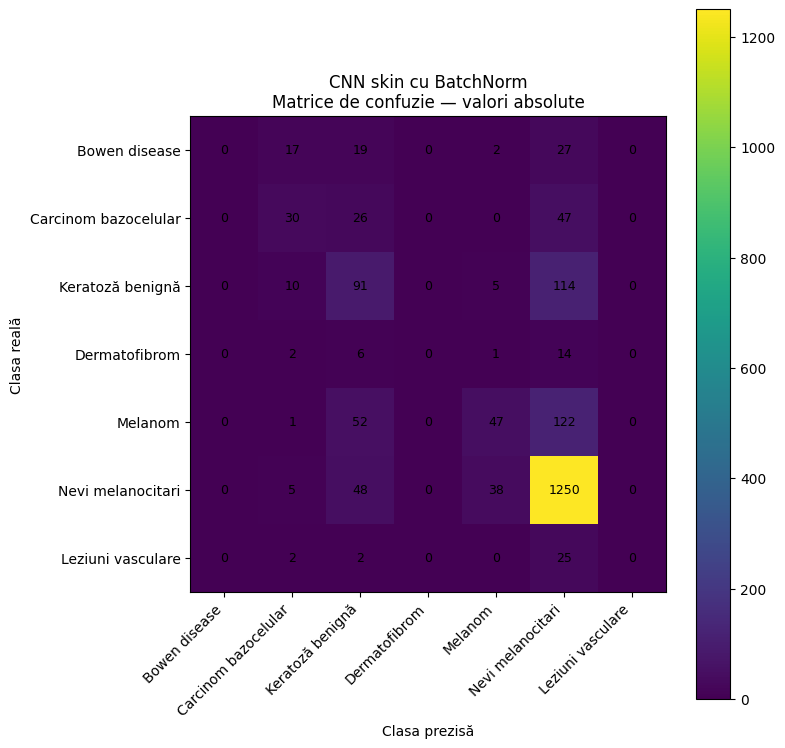

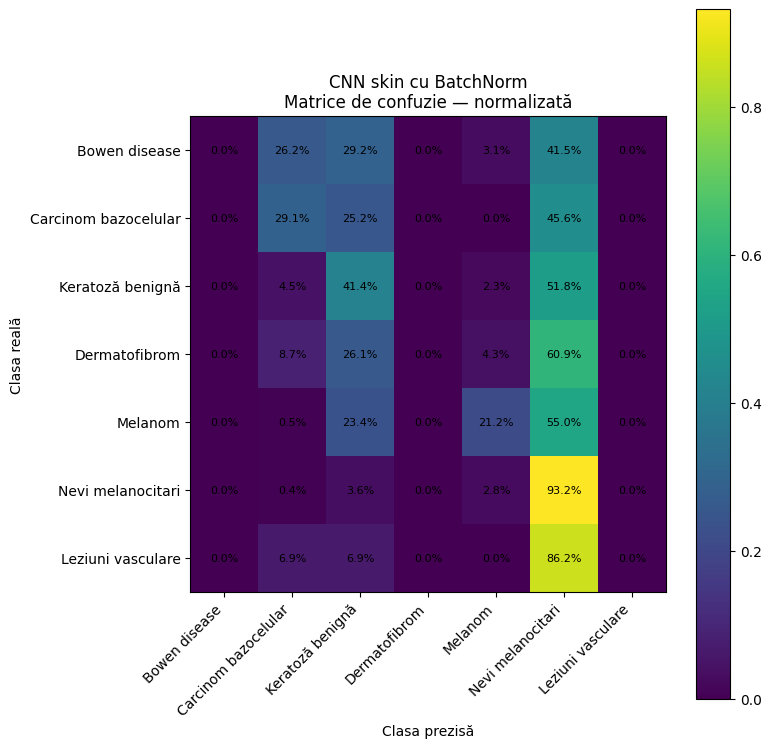


Classification report:


,precision,recall,f1-score,support
Bowen disease,0.000000,0.000000,0.000000,65.000000
Carcinom bazocelular,0.447761,0.291262,0.352941,103.000000
Keratoză benignă,0.372951,0.413636,0.392241,220.000000
Dermatofibrom,0.000000,0.000000,0.000000,23.000000
Melanom,0.505376,0.211712,0.298413,222.000000
Nevi melanocitari,0.781739,0.932140,0.850340,1341.000000
Leziuni vasculare,0.000000,0.000000,0.000000,29.000000
accuracy,0.707938,0.707938,0.707938,0.707938
macro avg,0.301118,0.264107,0.270562,2003.000000
weighted avg,0.643372,0.707938,0.663604,2003.000000



Fișiere salvate:
/kaggle/working/confusion_matrices_finale/cnn_skin_cu_batchnorm_confusion_counts.png
/kaggle/working/confusion_matrices_finale/cnn_skin_cu_batchnorm_confusion_normalized.png
/kaggle/working/confusion_matrices_finale/cnn_skin_cu_batchnorm_classification_report.csv


{'experiment': 'CNN skin cu BatchNorm',
 'accuracy': 0.707938092860709,
 'f1_macro': 0.27056219860686476,
 'f1_micro': 0.707938092860709,
 'confusion_counts_path': '/kaggle/working/confusion_matrices_finale/cnn_skin_cu_batchnorm_confusion_counts.png',
 'confusion_normalized_path': '/kaggle/working/confusion_matrices_finale/cnn_skin_cu_batchnorm_confusion_normalized.png',
 'classification_report_path': '/kaggle/working/confusion_matrices_finale/cnn_skin_cu_batchnorm_classification_report.csv'}

In [116]:
cnn_skin_confusion_result = evaluate_and_show_confusion(
    model=cnn_skin_model,
    test_loader=skin_test_cnn_loader,
    class_labels=skin_class_labels,
    experiment_name="CNN skin cu BatchNorm",
    use_tta=False,
)

cnn_skin_confusion_result


CNN camera cu BatchNorm
Accuracy : 0.43114
F1-macro : 0.16361
F1-micro : 0.43114


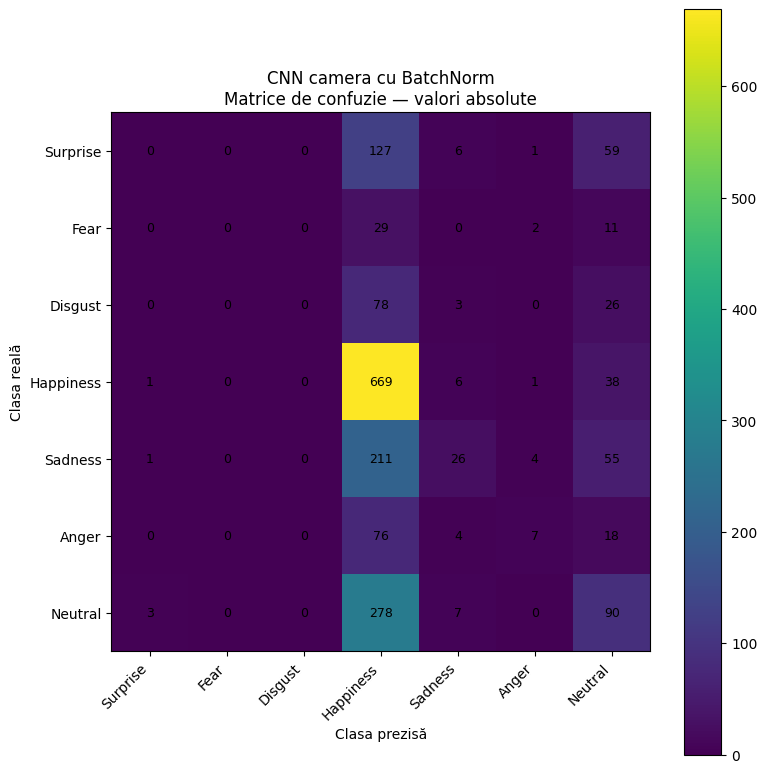

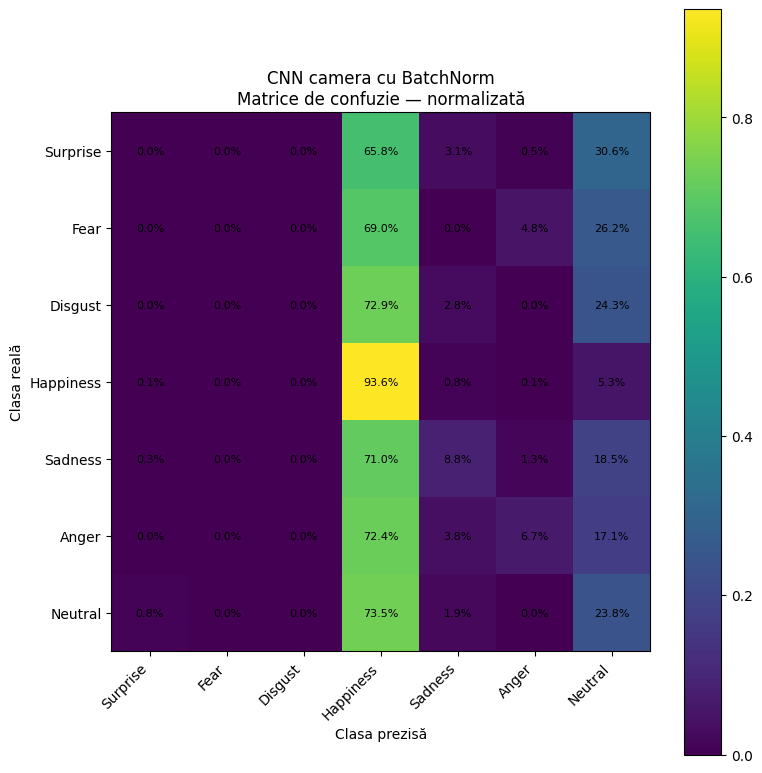


Classification report:


,precision,recall,f1-score,support
Surprise,0.000000,0.000000,0.000000,193.000000
Fear,0.000000,0.000000,0.000000,42.000000
Disgust,0.000000,0.000000,0.000000,107.000000
Happiness,0.455722,0.935664,0.612918,715.000000
Sadness,0.500000,0.087542,0.148997,297.000000
Anger,0.466667,0.066667,0.116667,105.000000
Neutral,0.303030,0.238095,0.266667,378.000000
accuracy,0.431138,0.431138,0.431138,0.431138
macro avg,0.246488,0.189710,0.163607,1837.000000
weighted avg,0.347244,0.431138,0.324191,1837.000000



Fișiere salvate:
/kaggle/working/confusion_matrices_finale/cnn_camera_cu_batchnorm_confusion_counts.png
/kaggle/working/confusion_matrices_finale/cnn_camera_cu_batchnorm_confusion_normalized.png
/kaggle/working/confusion_matrices_finale/cnn_camera_cu_batchnorm_classification_report.csv


{'experiment': 'CNN camera cu BatchNorm',
 'accuracy': 0.4311377245508982,
 'f1_macro': 0.16360692439319027,
 'f1_micro': 0.4311377245508982,
 'confusion_counts_path': '/kaggle/working/confusion_matrices_finale/cnn_camera_cu_batchnorm_confusion_counts.png',
 'confusion_normalized_path': '/kaggle/working/confusion_matrices_finale/cnn_camera_cu_batchnorm_confusion_normalized.png',
 'classification_report_path': '/kaggle/working/confusion_matrices_finale/cnn_camera_cu_batchnorm_classification_report.csv'}

In [117]:
cnn_camera_confusion_result = evaluate_and_show_confusion(
    model=cnn_camera_model,
    test_loader=camera_test_cnn_loader,
    class_labels=camera_class_labels,
    experiment_name="CNN camera cu BatchNorm",
    use_tta=False,
)

cnn_camera_confusion_result


Skin strong boosted model
Accuracy : 0.76385
F1-macro : 0.66130
F1-micro : 0.76385


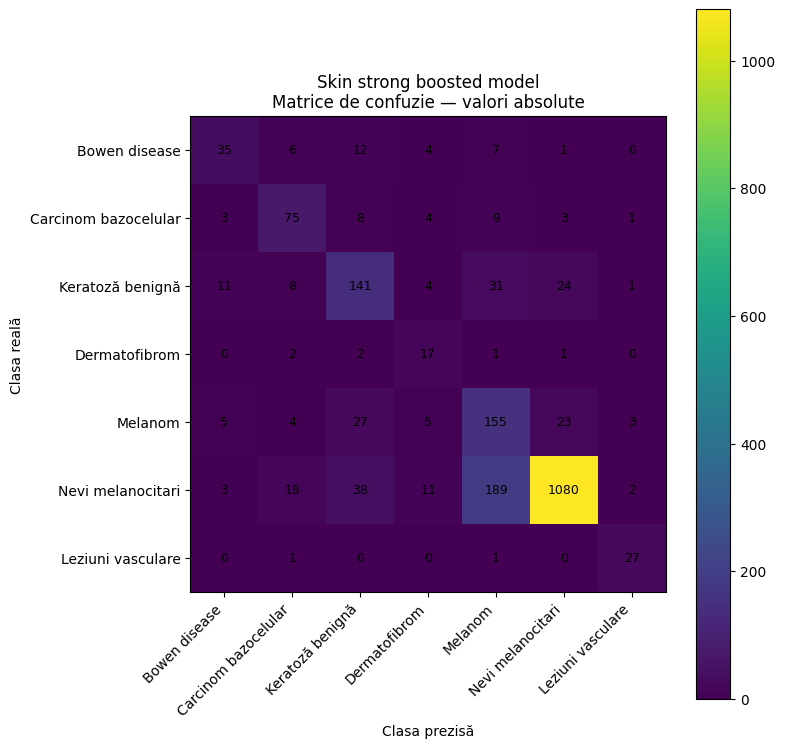

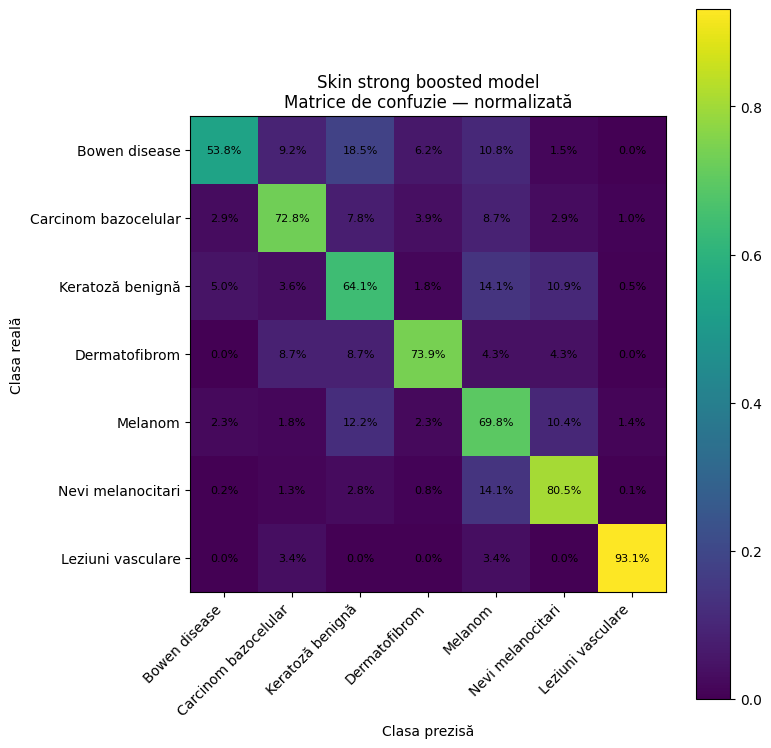


Classification report:


,precision,recall,f1-score,support
Bowen disease,0.614035,0.538462,0.573770,65.000000
Carcinom bazocelular,0.657895,0.728155,0.691244,103.000000
Keratoză benignă,0.618421,0.640909,0.629464,220.000000
Dermatofibrom,0.377778,0.739130,0.500000,23.000000
Melanom,0.394402,0.698198,0.504065,222.000000
Nevi melanocitari,0.954064,0.805369,0.873433,1341.000000
Leziuni vasculare,0.794118,0.931034,0.857143,29.000000
accuracy,0.763854,0.763854,0.763854,0.763854
macro avg,0.630102,0.725894,0.661303,2003.000000
weighted avg,0.819972,0.763854,0.782081,2003.000000



Fișiere salvate:
/kaggle/working/confusion_matrices_finale/skin_strong_boosted_model_confusion_counts.png
/kaggle/working/confusion_matrices_finale/skin_strong_boosted_model_confusion_normalized.png
/kaggle/working/confusion_matrices_finale/skin_strong_boosted_model_classification_report.csv


{'experiment': 'Skin strong boosted model',
 'accuracy': 0.763854218671992,
 'f1_macro': 0.6613028560251847,
 'f1_micro': 0.763854218671992,
 'confusion_counts_path': '/kaggle/working/confusion_matrices_finale/skin_strong_boosted_model_confusion_counts.png',
 'confusion_normalized_path': '/kaggle/working/confusion_matrices_finale/skin_strong_boosted_model_confusion_normalized.png',
 'classification_report_path': '/kaggle/working/confusion_matrices_finale/skin_strong_boosted_model_classification_report.csv'}

In [118]:
strong_skin_confusion_result = evaluate_and_show_confusion(
    model=strong_skin_model,
    test_loader=skin_test_boost_loader,
    class_labels=skin_class_labels,
    experiment_name="Skin strong boosted model",
    use_tta=True,
)

strong_skin_confusion_result

In [138]:
from torch.utils.data import DataLoader

if "face_local_loader" not in globals() and "face_test_transform" in globals():
    face_local_ds_for_eval = FaceTrainDataset(
        df_face_local,
        FACE_PATH_COL,
        FACE_LABEL_COL,
        transform=face_test_transform,
    )

    face_local_loader = DataLoader(
        face_local_ds_for_eval,
        batch_size=globals().get("FACE_BATCH_SIZE", 32),
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available(),
    )

    print("Creat face_local_loader")


if "turbo_local_loader" not in globals() and "turbo_test_transform" in globals():
    turbo_local_ds_for_eval = FaceTrainDataset(
        df_face_local,
        FACE_PATH_COL,
        FACE_LABEL_COL,
        transform=turbo_test_transform,
    )

    turbo_local_loader = DataLoader(
        turbo_local_ds_for_eval,
        batch_size=globals().get("TURBO_BATCH_SIZE", 16),
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available(),
    )

    print("Creat turbo_local_loader")

In [140]:
from torch.utils.data import DataLoader

face_local_ds_for_eval = FaceTrainDataset(
    df_face_local,
    FACE_PATH_COL,
    FACE_LABEL_COL,
    transform=face_test_transform,
)

face_local_loader_safe = DataLoader(
    face_local_ds_for_eval,
    batch_size=16,       # mai sigur decât 32
    shuffle=False,
    num_workers=0,       # important
    pin_memory=False,    # important
)

print("Creat face_local_loader_safe:", len(face_local_ds_for_eval), "imagini")

Dataset cu etichete creat: 1837 imagini
Creat face_local_loader_safe: 1837 imagini



Camera final model
Accuracy : 0.90582
F1-macro : 0.90642
F1-micro : 0.90582


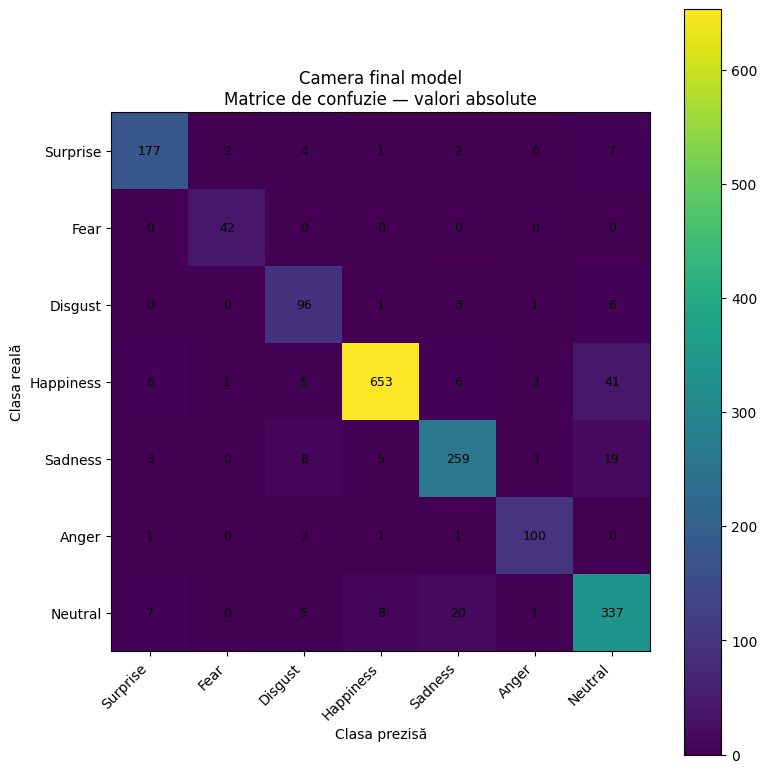

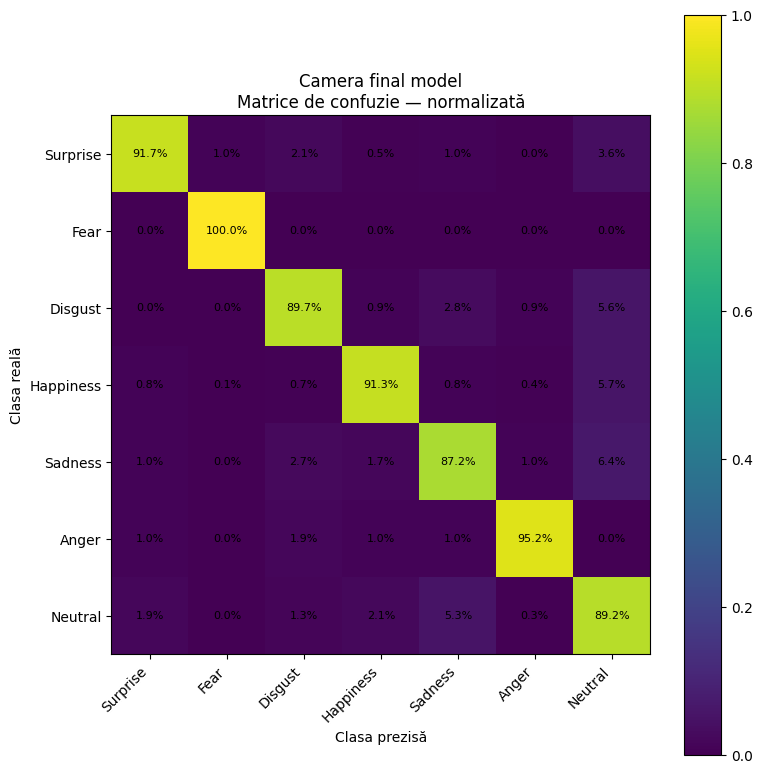


Classification report:


,precision,recall,f1-score,support
Surprise,0.912371,0.917098,0.914729,193.000000
Fear,0.933333,1.000000,0.965517,42.000000
Disgust,0.800000,0.897196,0.845815,107.000000
Happiness,0.976084,0.913287,0.943642,715.000000
Sadness,0.890034,0.872054,0.880952,297.000000
Anger,0.925926,0.952381,0.938967,105.000000
Neutral,0.821951,0.891534,0.855330,378.000000
accuracy,0.905825,0.905825,0.905825,0.905825
macro avg,0.894243,0.920507,0.906422,1837.000000
weighted avg,0.909661,0.905825,0.906831,1837.000000



Fișiere salvate:
/kaggle/working/confusion_matrices_finale/camera_final_model_confusion_counts.png
/kaggle/working/confusion_matrices_finale/camera_final_model_confusion_normalized.png
/kaggle/working/confusion_matrices_finale/camera_final_model_classification_report.csv


{'experiment': 'Camera final model',
 'accuracy': 0.9058247142079477,
 'f1_macro': 0.9064217123373893,
 'f1_micro': 0.9058247142079477,
 'confusion_counts_path': '/kaggle/working/confusion_matrices_finale/camera_final_model_confusion_counts.png',
 'confusion_normalized_path': '/kaggle/working/confusion_matrices_finale/camera_final_model_confusion_normalized.png',
 'classification_report_path': '/kaggle/working/confusion_matrices_finale/camera_final_model_classification_report.csv'}

In [141]:
face_final_confusion_result = evaluate_and_show_confusion(
    model=face_final_model,
    test_loader=face_local_loader_safe,
    class_labels=get_camera_class_labels() if "get_camera_class_labels" in globals() else camera_class_labels,
    experiment_name="Camera final model",
    use_tta=False,   # mai rapid; pune True doar dacă ai timp
)

face_final_confusion_result


Camera turbo model
Accuracy : 0.96897
F1-macro : 0.97348
F1-micro : 0.96897


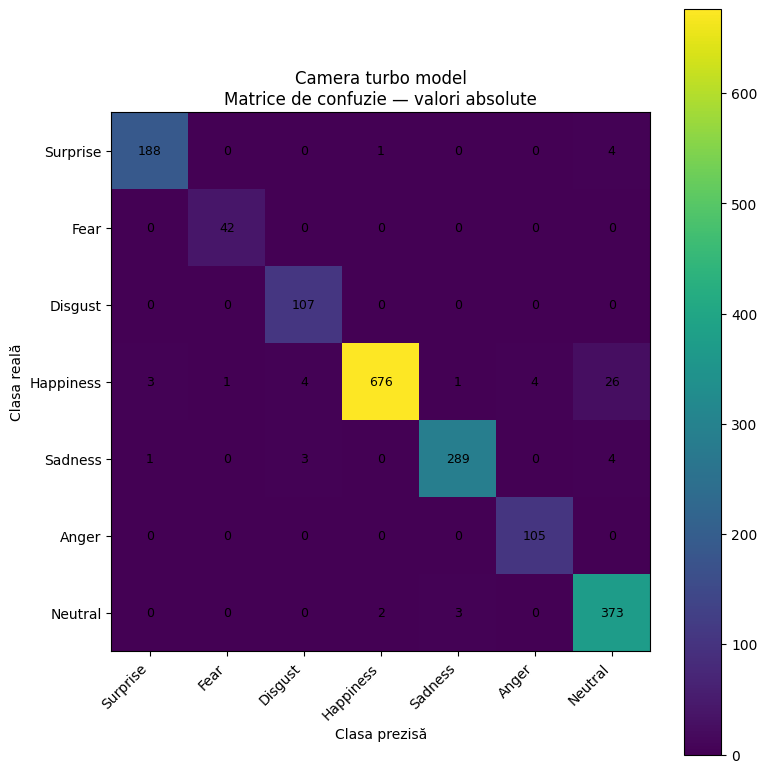

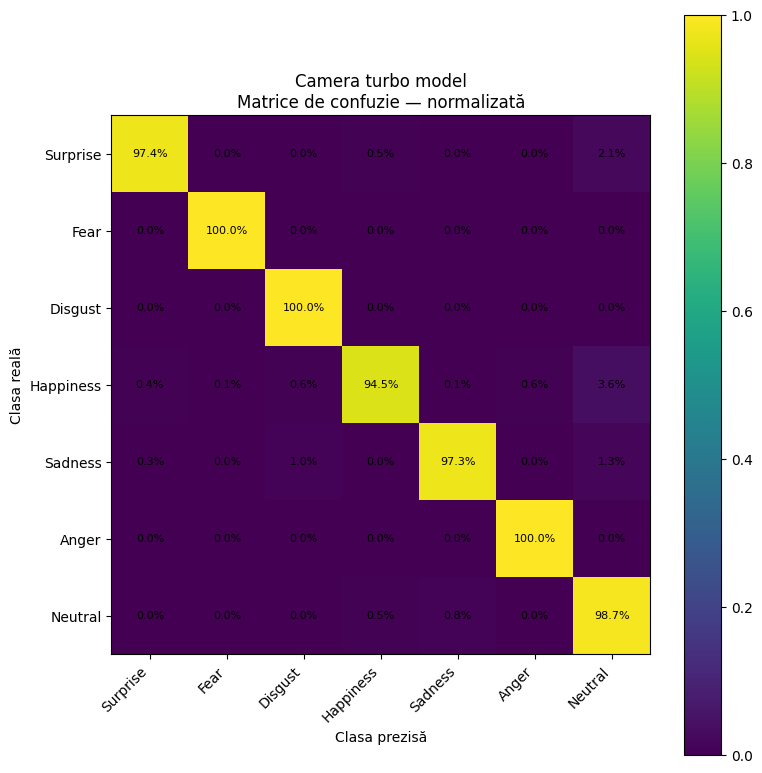


Classification report:


,precision,recall,f1-score,support
Surprise,0.979167,0.974093,0.976623,193.000000
Fear,0.976744,1.000000,0.988235,42.000000
Disgust,0.938596,1.000000,0.968326,107.000000
Happiness,0.995582,0.945455,0.969871,715.000000
Sadness,0.986348,0.973064,0.979661,297.000000
Anger,0.963303,1.000000,0.981308,105.000000
Neutral,0.916462,0.986772,0.950318,378.000000
accuracy,0.968971,0.968971,0.968971,0.968971
macro avg,0.965172,0.982769,0.973478,1837.000000
weighted avg,0.970489,0.968971,0.969123,1837.000000



Fișiere salvate:
/kaggle/working/confusion_matrices_finale/camera_turbo_model_confusion_counts.png
/kaggle/working/confusion_matrices_finale/camera_turbo_model_confusion_normalized.png
/kaggle/working/confusion_matrices_finale/camera_turbo_model_classification_report.csv


{'experiment': 'Camera turbo model',
 'accuracy': 0.9689711486118672,
 'f1_macro': 0.9734776053253219,
 'f1_micro': 0.9689711486118672,
 'confusion_counts_path': '/kaggle/working/confusion_matrices_finale/camera_turbo_model_confusion_counts.png',
 'confusion_normalized_path': '/kaggle/working/confusion_matrices_finale/camera_turbo_model_confusion_normalized.png',
 'classification_report_path': '/kaggle/working/confusion_matrices_finale/camera_turbo_model_classification_report.csv'}

In [142]:
# ============================================================
# Matrice de confuzie — Camera turbo model
# ============================================================

turbo_confusion_result = evaluate_and_show_confusion(
    model=turbo_model,
    test_loader=turbo_local_loader,
    class_labels=get_camera_class_labels() if "get_camera_class_labels" in globals() else camera_class_labels,
    experiment_name="Camera turbo model",
    use_tta=True,
)

turbo_confusion_result

Device: cuda
Salvez matricile în: /kaggle/working/matrici_confuzie_modele_bune
Dataset cu etichete creat: 1837 imagini
Dataset cu etichete creat: 1837 imagini
Dataset cu etichete creat: 1837 imagini

Skin — strong model final nou
Accuracy : 0.76435
F1-macro : 0.66186
F1-micro : 0.76435


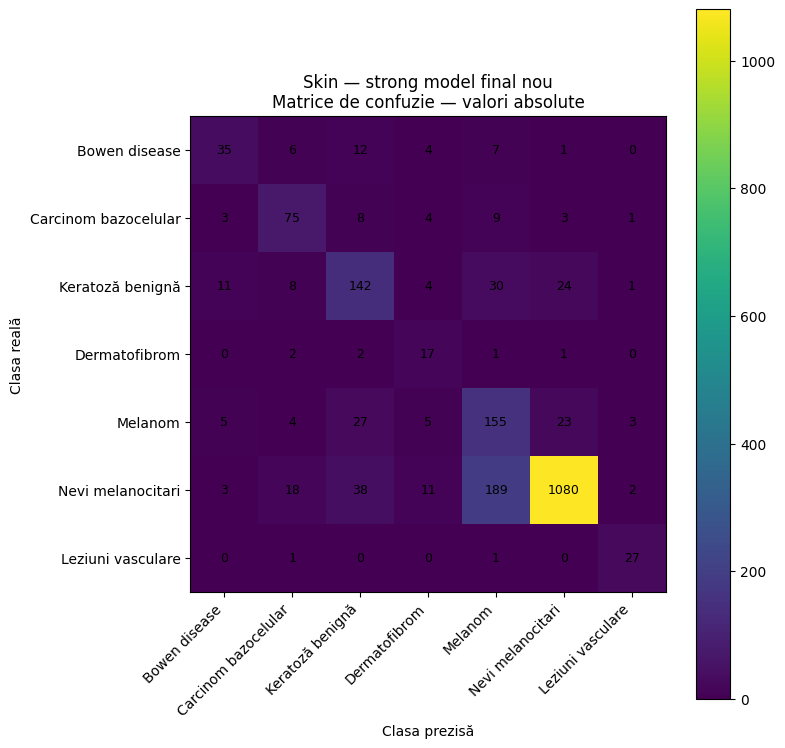

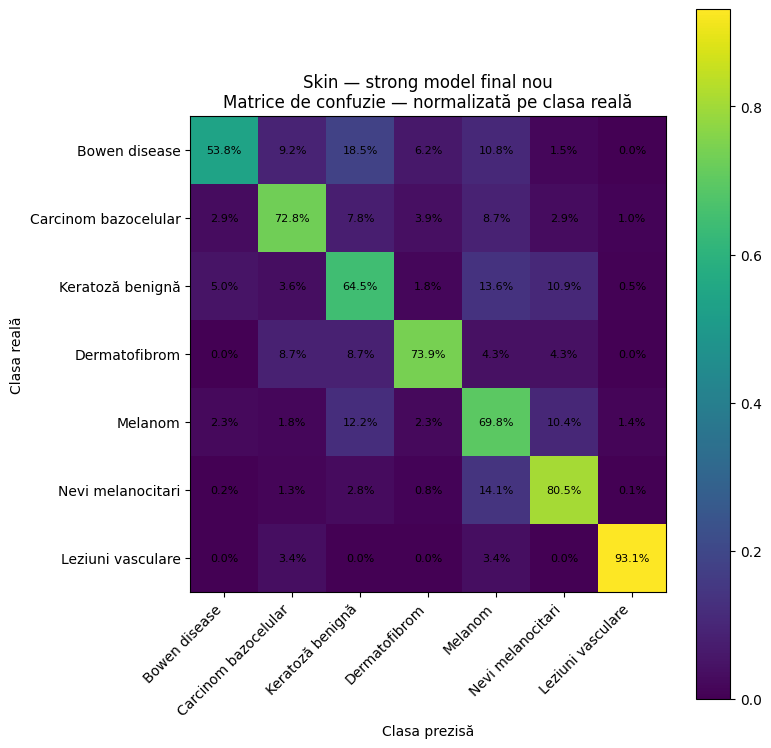

Classification report:


,precision,recall,f1-score,support
Bowen disease,0.614035,0.538462,0.573770,65.000000
Carcinom bazocelular,0.657895,0.728155,0.691244,103.000000
Keratoză benignă,0.620087,0.645455,0.632517,220.000000
Dermatofibrom,0.377778,0.739130,0.500000,23.000000
Melanom,0.395408,0.698198,0.504886,222.000000
Nevi melanocitari,0.954064,0.805369,0.873433,1341.000000
Leziuni vasculare,0.794118,0.931034,0.857143,29.000000
accuracy,0.764353,0.764353,0.764353,0.764353
macro avg,0.630483,0.726543,0.661856,2003.000000
weighted avg,0.820266,0.764353,0.782507,2003.000000


Fișiere salvate:
/kaggle/working/matrici_confuzie_modele_bune/skin__strong_model_final_nou_confusion_counts.png
/kaggle/working/matrici_confuzie_modele_bune/skin__strong_model_final_nou_confusion_normalized.png
/kaggle/working/matrici_confuzie_modele_bune/skin__strong_model_final_nou_classification_report.csv

Camera — face_final_model nou
Accuracy : 0.90909
F1-macro : 0.91332
F1-micro : 0.90909


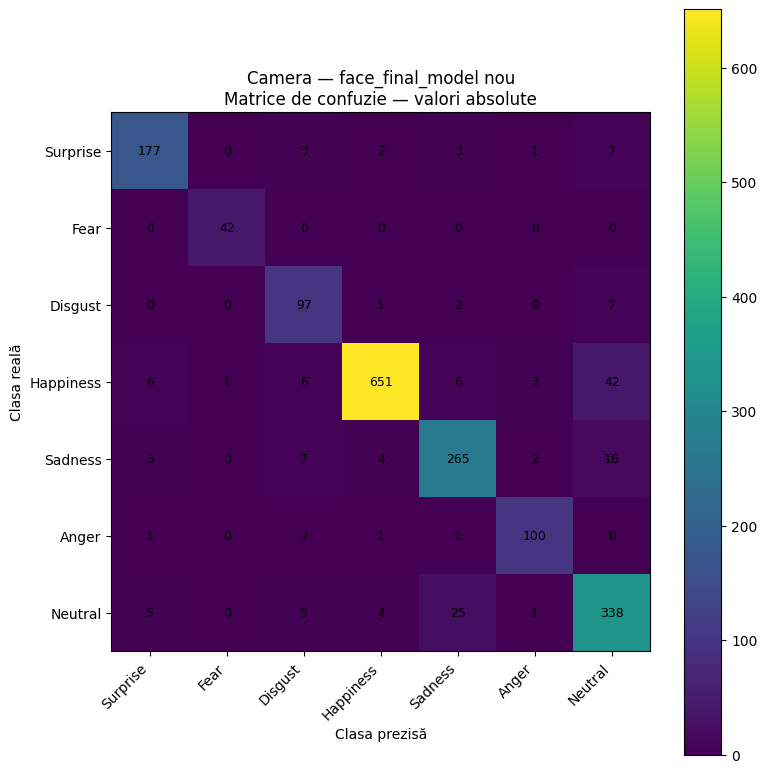

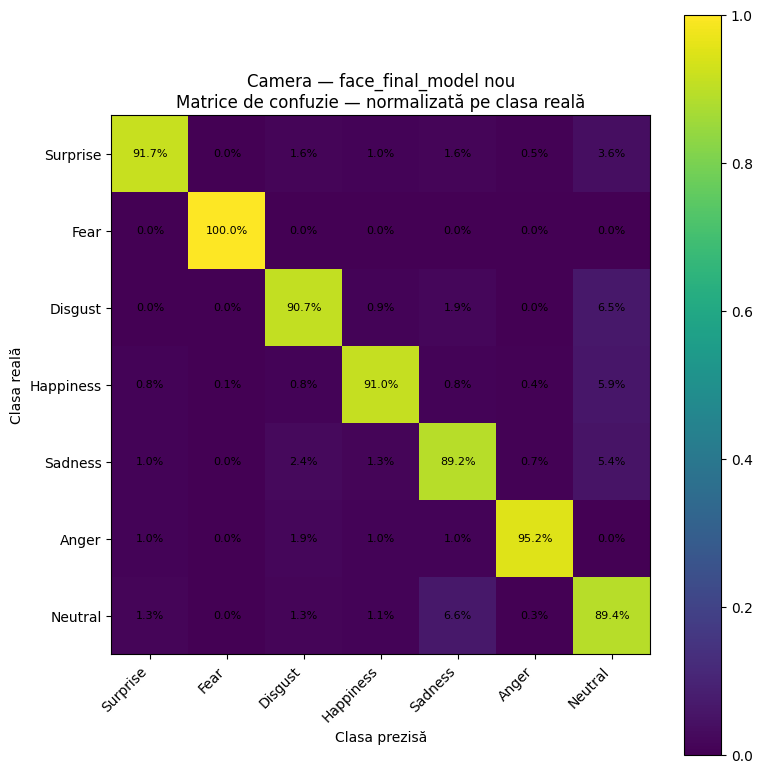

Classification report:


,precision,recall,f1-score,support
Surprise,0.921875,0.917098,0.919481,193.000000
Fear,0.976744,1.000000,0.988235,42.000000
Disgust,0.808333,0.906542,0.854626,107.000000
Happiness,0.981900,0.910490,0.944848,715.000000
Sadness,0.877483,0.892256,0.884808,297.000000
Anger,0.934579,0.952381,0.943396,105.000000
Neutral,0.824390,0.894180,0.857868,378.000000
accuracy,0.909091,0.909091,0.909091,0.909091
macro avg,0.903615,0.924707,0.913323,1837.000000
weighted avg,0.913369,0.909091,0.910232,1837.000000


Fișiere salvate:
/kaggle/working/matrici_confuzie_modele_bune/camera__face_final_model_nou_confusion_counts.png
/kaggle/working/matrici_confuzie_modele_bune/camera__face_final_model_nou_confusion_normalized.png
/kaggle/working/matrici_confuzie_modele_bune/camera__face_final_model_nou_classification_report.csv

Camera — turbo_model nou
Accuracy : 0.96897
F1-macro : 0.97348
F1-micro : 0.96897


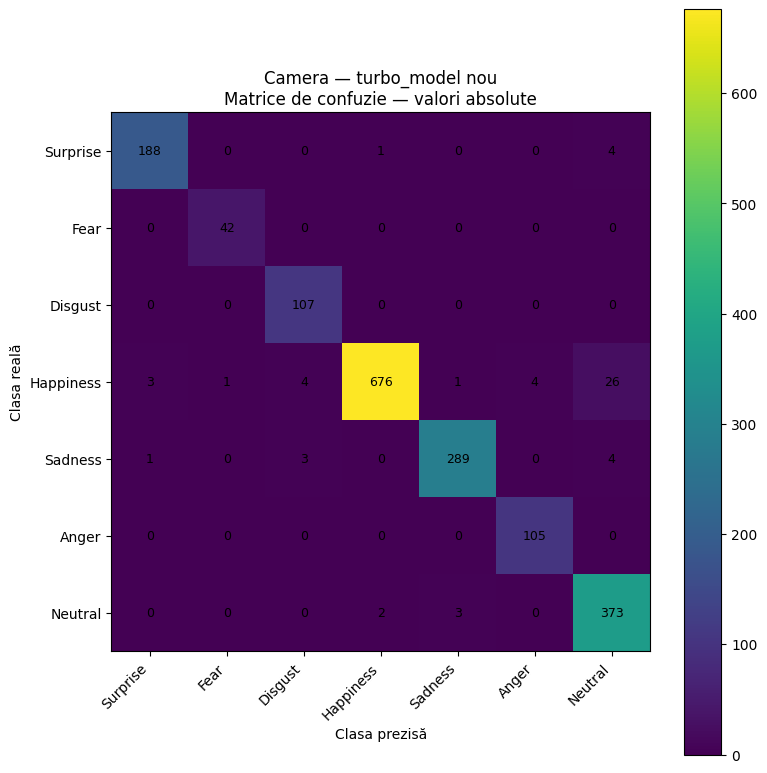

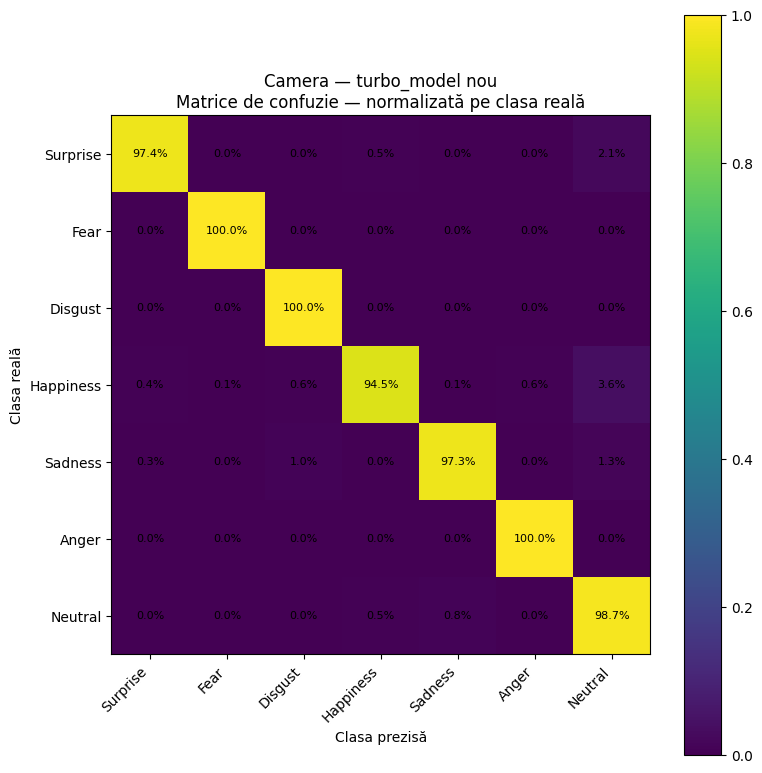

Classification report:


,precision,recall,f1-score,support
Surprise,0.979167,0.974093,0.976623,193.000000
Fear,0.976744,1.000000,0.988235,42.000000
Disgust,0.938596,1.000000,0.968326,107.000000
Happiness,0.995582,0.945455,0.969871,715.000000
Sadness,0.986348,0.973064,0.979661,297.000000
Anger,0.963303,1.000000,0.981308,105.000000
Neutral,0.916462,0.986772,0.950318,378.000000
accuracy,0.968971,0.968971,0.968971,0.968971
macro avg,0.965172,0.982769,0.973478,1837.000000
weighted avg,0.970489,0.968971,0.969123,1837.000000


Fișiere salvate:
/kaggle/working/matrici_confuzie_modele_bune/camera__turbo_model_nou_confusion_counts.png
/kaggle/working/matrici_confuzie_modele_bune/camera__turbo_model_nou_confusion_normalized.png
/kaggle/working/matrici_confuzie_modele_bune/camera__turbo_model_nou_classification_report.csv

Camera — ResNet18 final nou
Accuracy : 0.97333
F1-macro : 0.98067
F1-micro : 0.97333


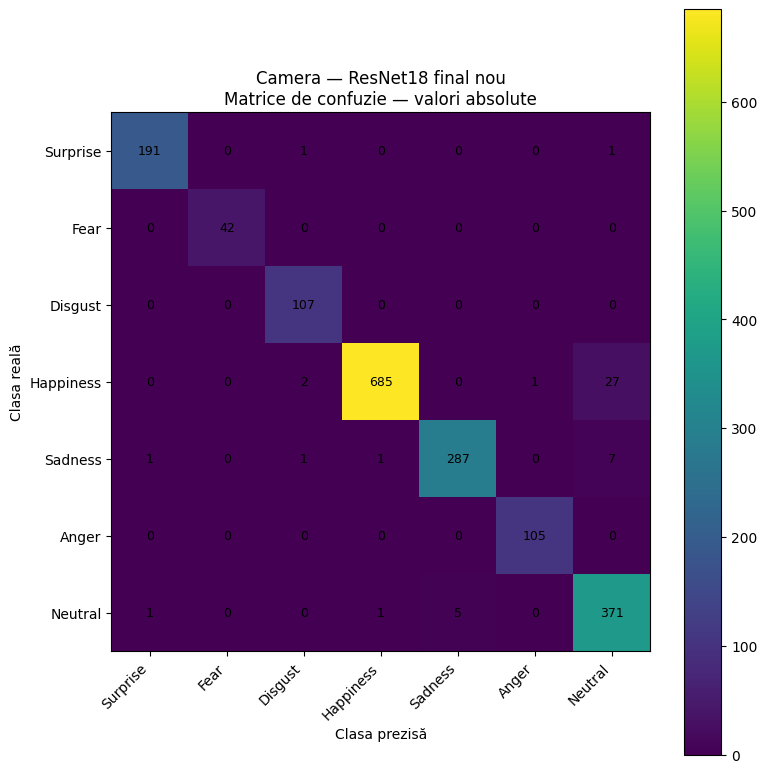

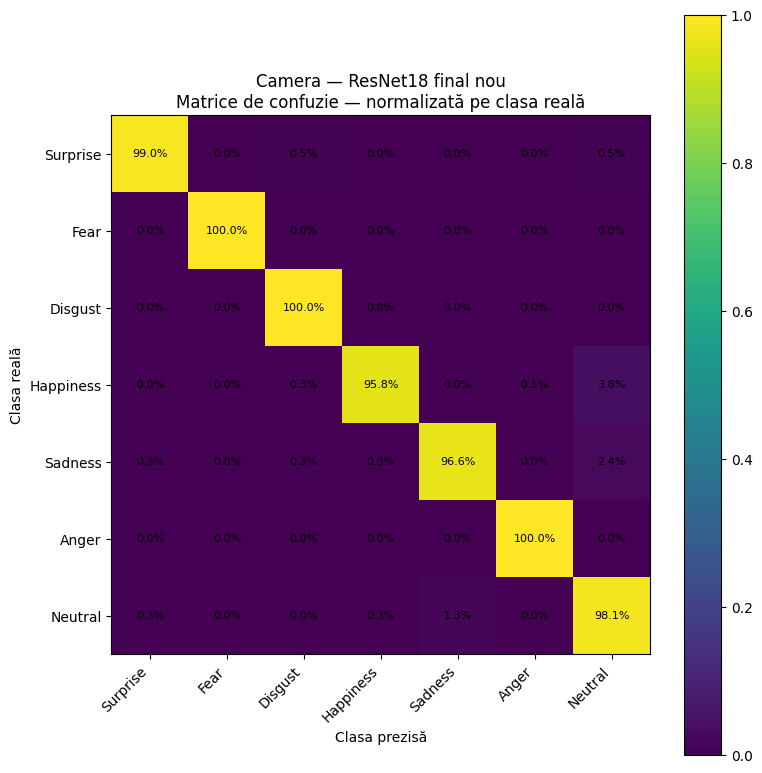

Classification report:


,precision,recall,f1-score,support
Surprise,0.989637,0.989637,0.989637,193.000000
Fear,1.000000,1.000000,1.000000,42.000000
Disgust,0.963964,1.000000,0.981651,107.000000
Happiness,0.997089,0.958042,0.977175,715.000000
Sadness,0.982877,0.966330,0.974533,297.000000
Anger,0.990566,1.000000,0.995261,105.000000
Neutral,0.913793,0.981481,0.946429,378.000000
accuracy,0.973326,0.973326,0.973326,0.973326
macro avg,0.976847,0.985070,0.980669,1837.000000
weighted avg,0.974633,0.973326,0.973547,1837.000000


Fișiere salvate:
/kaggle/working/matrici_confuzie_modele_bune/camera__resnet18_final_nou_confusion_counts.png
/kaggle/working/matrici_confuzie_modele_bune/camera__resnet18_final_nou_confusion_normalized.png
/kaggle/working/matrici_confuzie_modele_bune/camera__resnet18_final_nou_classification_report.csv

Camera — MobileNetV2 final nou
Accuracy : 0.80838
F1-macro : 0.78077
F1-micro : 0.80838


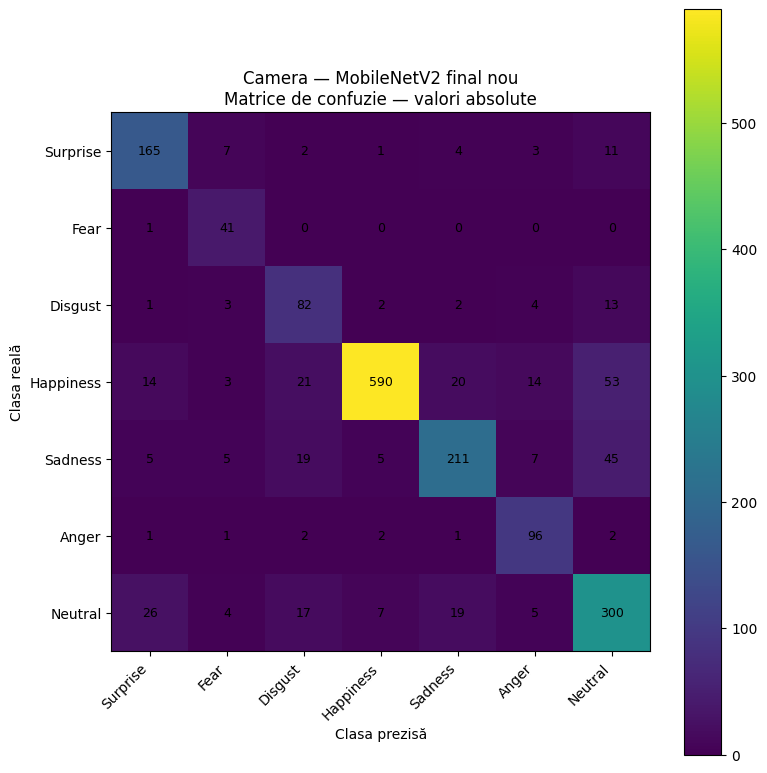

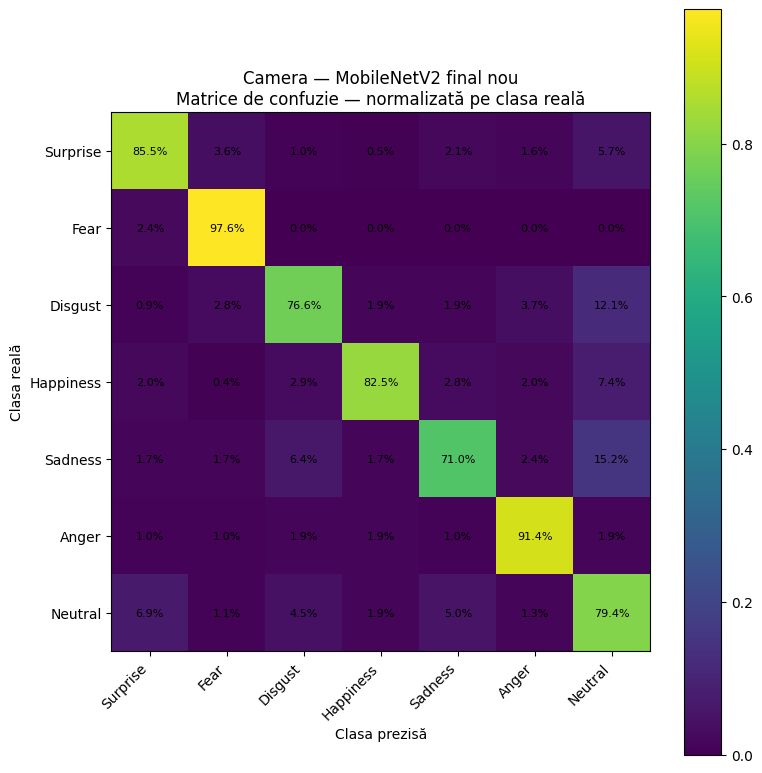

Classification report:


,precision,recall,f1-score,support
Surprise,0.774648,0.854922,0.812808,193.000000
Fear,0.640625,0.976190,0.773585,42.000000
Disgust,0.573427,0.766355,0.656000,107.000000
Happiness,0.971993,0.825175,0.892587,715.000000
Sadness,0.821012,0.710438,0.761733,297.000000
Anger,0.744186,0.914286,0.820513,105.000000
Neutral,0.707547,0.793651,0.748130,378.000000
accuracy,0.808383,0.808383,0.808383,0.808383
macro avg,0.747634,0.834431,0.780765,1837.000000
weighted avg,0.828622,0.808383,0.812703,1837.000000


Fișiere salvate:
/kaggle/working/matrici_confuzie_modele_bune/camera__mobilenetv2_final_nou_confusion_counts.png
/kaggle/working/matrici_confuzie_modele_bune/camera__mobilenetv2_final_nou_confusion_normalized.png
/kaggle/working/matrici_confuzie_modele_bune/camera__mobilenetv2_final_nou_classification_report.csv

REZUMAT MATRICE DE CONFUZIE — MODELE NOI BUNE


,experiment,accuracy,f1_macro,f1_micro,confusion_counts,confusion_normalized,classification_report
0,Skin — strong model final nou,0.764353,0.661856,0.764353,/kaggle/working/matrici_confuzie_modele_bune/s...,/kaggle/working/matrici_confuzie_modele_bune/s...,/kaggle/working/matrici_confuzie_modele_bune/s...
1,Camera — face_final_model nou,0.909091,0.913323,0.909091,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...
2,Camera — turbo_model nou,0.968971,0.973478,0.968971,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...
3,Camera — ResNet18 final nou,0.973326,0.980669,0.973326,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...
4,Camera — MobileNetV2 final nou,0.808383,0.780765,0.808383,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...,/kaggle/working/matrici_confuzie_modele_bune/c...


Rezumat salvat aici:
/kaggle/working/matrici_confuzie_modele_bune/rezumat_matrici_modele_bune.csv


...

/kaggle/working/matrici_confuzie_modele_bune/camera__turbo_model_nou_confusion_normalized.png

skin__strong_model_final_nou_confusion_counts.png


/kaggle/working/matrici_confuzie_modele_bune/skin__strong_model_final_nou_confusion_counts.png

skin__strong_model_final_nou_confusion_normalized.png


/kaggle/working/matrici_confuzie_modele_bune/skin__strong_model_final_nou_confusion_normalized.png

In [143]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
from IPython.display import display, FileLink

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/kaggle/working")
CM_DIR = WORK_DIR / "matrici_confuzie_modele_bune"
CM_DIR.mkdir(parents=True, exist_ok=True)

USE_AMP = torch.cuda.is_available()

print("Device:", DEVICE)
print("Salvez matricile în:", CM_DIR)


def get_camera_labels_for_plot():
    if "camera_class_labels" in globals():
        return camera_class_labels

    if "FACE_IDX_TO_LABEL" in globals():
        labels = []
        for i in range(len(FACE_IDX_TO_LABEL)):
            original_label = int(FACE_IDX_TO_LABEL[i])
            if "FACE_CLASS_NAMES" in globals():
                labels.append(f"{original_label}-{FACE_CLASS_NAMES.get(original_label, str(original_label))}")
            else:
                labels.append(str(original_label))
        return labels

    return [str(i) for i in range(7)]


def get_skin_labels_for_plot():
    if "skin_class_labels" in globals():
        return skin_class_labels

    if "skin_idx_to_class" in globals():
        return [str(skin_idx_to_class[i]) for i in range(len(skin_idx_to_class))]

    if "skin_class_to_idx" in globals():
        inv = {v: k for k, v in skin_class_to_idx.items()}
        return [str(inv[i]) for i in range(len(inv))]

    return [str(i) for i in range(7)]


def safe_filename(text):
    return (
        str(text)
        .lower()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("—", "_")
        .replace("-", "_")
        .replace("__", "_")
    )


@torch.no_grad()
def predict_for_confusion(model, loader, use_tta=False):
    model = model.to(DEVICE)
    model.eval()

    y_true = []
    y_pred = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)

            if use_tta:
                logits_flip = model(torch.flip(images, dims=[3]))
                logits = (logits + logits_flip) / 2.0

        preds = logits.argmax(dim=1)

        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())

    return np.array(y_true), np.array(y_pred)


def show_confusion_matrix_good_model(
    model,
    loader,
    class_labels,
    title,
    use_tta=False,
):
    y_true, y_pred = predict_for_confusion(
        model=model,
        loader=loader,
        use_tta=use_tta,
    )

    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    f1_micro = f1_score(y_true, y_pred, average="micro", zero_division=0)

    print("\n" + "=" * 90)
    print(title)
    print("=" * 90)
    print(f"Accuracy : {acc:.5f}")
    print(f"F1-macro : {f1_macro:.5f}")
    print(f"F1-micro : {f1_micro:.5f}")

    labels_idx = list(range(len(class_labels)))
    cm = confusion_matrix(y_true, y_pred, labels=labels_idx)

    # Matrice valori absolute
    fig_size = max(7, len(class_labels) * 1.15)
    fig, ax = plt.subplots(figsize=(fig_size, fig_size))

    im = ax.imshow(cm)
    ax.set_title(f"{title}\nMatrice de confuzie — valori absolute")
    ax.set_xlabel("Clasa prezisă")
    ax.set_ylabel("Clasa reală")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=9)

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    fname = safe_filename(title)
    counts_path = CM_DIR / f"{fname}_confusion_counts.png"
    plt.savefig(counts_path, dpi=160, bbox_inches="tight")
    plt.show()

    # Matrice normalizată
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(
        cm,
        row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0,
    )

    fig, ax = plt.subplots(figsize=(fig_size, fig_size))

    im = ax.imshow(cm_norm)
    ax.set_title(f"{title}\nMatrice de confuzie — normalizată pe clasa reală")
    ax.set_xlabel("Clasa prezisă")
    ax.set_ylabel("Clasa reală")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    for i in range(cm_norm.shape[0]):
        for j in range(cm_norm.shape[1]):
            ax.text(j, i, f"{cm_norm[i, j] * 100:.1f}%", ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    norm_path = CM_DIR / f"{fname}_confusion_normalized.png"
    plt.savefig(norm_path, dpi=160, bbox_inches="tight")
    plt.show()

    report_df = pd.DataFrame(
        classification_report(
            y_true,
            y_pred,
            labels=labels_idx,
            target_names=[str(x) for x in class_labels],
            zero_division=0,
            output_dict=True,
        )
    ).transpose()

    report_path = CM_DIR / f"{fname}_classification_report.csv"
    report_df.to_csv(report_path)

    print("Classification report:")
    display(report_df)

    result = {
        "experiment": title,
        "accuracy": acc,
        "f1_macro": f1_macro,
        "f1_micro": f1_micro,
        "confusion_counts": str(counts_path),
        "confusion_normalized": str(norm_path),
        "classification_report": str(report_path),
    }

    print("Fișiere salvate:")
    print(counts_path)
    print(norm_path)
    print(report_path)

    return result


skin_labels = get_skin_labels_for_plot()
camera_labels = get_camera_labels_for_plot()

# Skin loader pentru modelul bun nou
skin_good_loader = None

if "skin_test_boost_ds" in globals():
    skin_good_loader = DataLoader(
        skin_test_boost_ds,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
    )
elif "skin_test_boost_loader" in globals():
    skin_good_loader = skin_test_boost_loader
elif "skin_test_ft_loader" in globals():
    skin_good_loader = skin_test_ft_loader
elif "skin_test_cnn_loader" in globals():
    skin_good_loader = skin_test_cnn_loader


# Camera loader pentru face_final_model
camera_face_loader = None

if "FaceTrainDataset" in globals() and "df_face_local" in globals():
    if "face_test_transform" in globals():
        camera_face_ds = FaceTrainDataset(
            df_face_local,
            FACE_PATH_COL,
            FACE_LABEL_COL,
            transform=face_test_transform,
        )

        camera_face_loader = DataLoader(
            camera_face_ds,
            batch_size=16,
            shuffle=False,
            num_workers=0,
            pin_memory=False,
        )


# Camera loader pentru turbo_model
camera_turbo_loader = None

if "FaceTrainDataset" in globals() and "df_face_local" in globals():
    if "turbo_test_transform" in globals():
        camera_turbo_ds = FaceTrainDataset(
            df_face_local,
            FACE_PATH_COL,
            FACE_LABEL_COL,
            transform=turbo_test_transform,
        )

        camera_turbo_loader = DataLoader(
            camera_turbo_ds,
            batch_size=16,
            shuffle=False,
            num_workers=0,
            pin_memory=False,
        )


# Camera loader pentru ResNet18/MobileNetV2 final
camera_final_loader = None

if "FaceTrainDataset" in globals() and "df_face_local" in globals():
    if "face_final_test_transform" in globals():
        camera_final_ds = FaceTrainDataset(
            df_face_local,
            FACE_PATH_COL,
            FACE_LABEL_COL,
            transform=face_final_test_transform,
        )

        camera_final_loader = DataLoader(
            camera_final_ds,
            batch_size=16,
            shuffle=False,
            num_workers=0,
            pin_memory=False,
        )


results_good_confusions = []

# 1. Skin — modelul nou bun
if "strong_skin_model" in globals() and skin_good_loader is not None:
    results_good_confusions.append(
        show_confusion_matrix_good_model(
            model=strong_skin_model,
            loader=skin_good_loader,
            class_labels=skin_labels,
            title="Skin — strong model final nou",
            use_tta=True,
        )
    )
else:
    print("Nu pot face matrice pentru strong_skin_model: lipsește modelul sau loaderul.")


# 2. Camera — model final obișnuit
if "face_final_model" in globals() and camera_face_loader is not None:
    results_good_confusions.append(
        show_confusion_matrix_good_model(
            model=face_final_model,
            loader=camera_face_loader,
            class_labels=camera_labels,
            title="Camera — face_final_model nou",
            use_tta=True,
        )
    )
else:
    print("Nu pot face matrice pentru face_final_model: lipsește modelul sau loaderul.")


# 3. Camera — turbo model
if "turbo_model" in globals() and camera_turbo_loader is not None:
    results_good_confusions.append(
        show_confusion_matrix_good_model(
            model=turbo_model,
            loader=camera_turbo_loader,
            class_labels=camera_labels,
            title="Camera — turbo_model nou",
            use_tta=True,
        )
    )
else:
    print("Nu pot face matrice pentru turbo_model: lipsește modelul sau loaderul.")


# 4. Camera — ResNet18 final
if "camera_resnet18_final" in globals() and camera_final_loader is not None:
    results_good_confusions.append(
        show_confusion_matrix_good_model(
            model=camera_resnet18_final,
            loader=camera_final_loader,
            class_labels=camera_labels,
            title="Camera — ResNet18 final nou",
            use_tta=True,
        )
    )
else:
    print("Nu pot face matrice pentru camera_resnet18_final: lipsește modelul sau loaderul.")


# 5. Camera — MobileNetV2 final
if "camera_mobilenetv2_final" in globals() and camera_final_loader is not None:
    results_good_confusions.append(
        show_confusion_matrix_good_model(
            model=camera_mobilenetv2_final,
            loader=camera_final_loader,
            class_labels=camera_labels,
            title="Camera — MobileNetV2 final nou",
            use_tta=True,
        )
    )
else:
    print("Nu pot face matrice pentru camera_mobilenetv2_final: lipsește modelul sau loaderul.")


results_good_df = pd.DataFrame(results_good_confusions)

print("\n" + "=" * 90)
print("REZUMAT MATRICE DE CONFUZIE — MODELE NOI BUNE")
print("=" * 90)

if len(results_good_df) > 0:
    display(results_good_df)

    summary_path = CM_DIR / "rezumat_matrici_modele_bune.csv"
    results_good_df.to_csv(summary_path, index=False)

    print("Rezumat salvat aici:")
    print(summary_path)
    display(FileLink(str(summary_path)))

    print("\nPNG-uri generate:")
    for p in sorted(CM_DIR.glob("*.png")):
        print(p.name)
        display(FileLink(str(p)))
else:
    print("Nu s-a generat nicio matrice. Probabil modelele noi nu mai sunt în memorie.")

Device: cuda
Epoci scurte: 1
Folder output: /kaggle/working/matrici_dupa_finetuning_scurt

Experimente găsite pentru fine-tuning scurt:
- Skin MLP după fine-tuning scurt
- Skin CNN după fine-tuning scurt
- Camera MLP după fine-tuning scurt
- Camera CNN după fine-tuning scurt
- Skin strong model după fine-tuning scurt
- Camera face_final_model după fine-tuning scurt
- Camera turbo_model după fine-tuning scurt

##########################################################################################
FINE-TUNING SCURT: Skin MLP după fine-tuning scurt
##########################################################################################
Skin MLP după fine-tuning scurt | epoca scurtă 1/1 | loss=1.0060 | train acc=0.7148 | train F1-macro=0.3166

Skin MLP după fine-tuning scurt
Accuracy : 0.72391
F1-macro : 0.33153
F1-micro : 0.72391


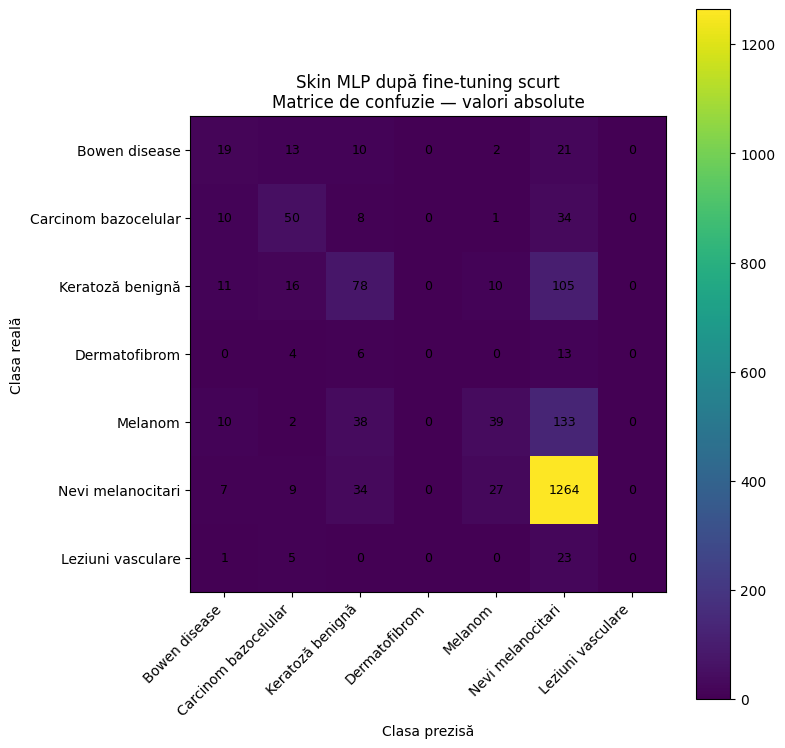

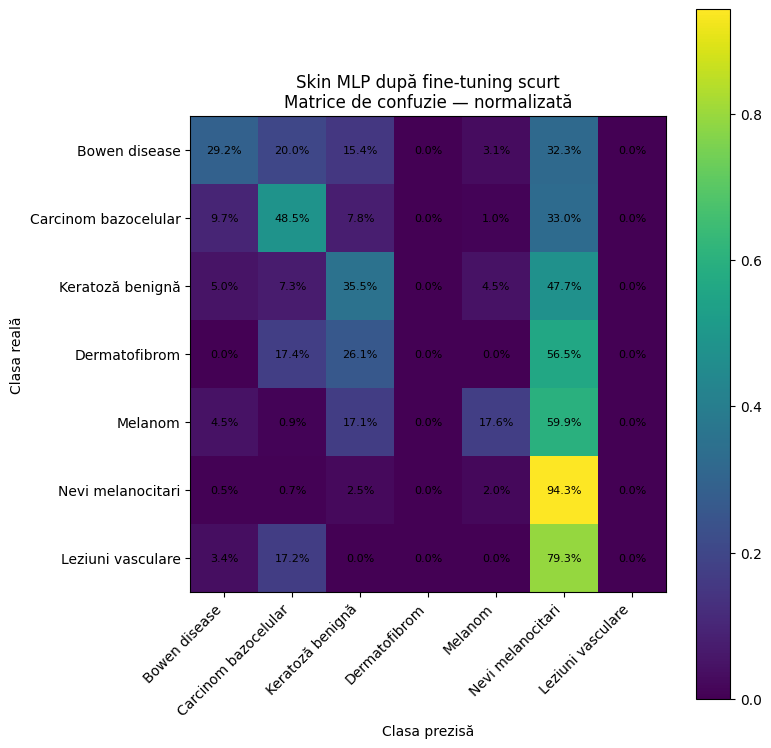

Classification report:


,precision,recall,f1-score,support
Bowen disease,0.327586,0.292308,0.308943,65.000000
Carcinom bazocelular,0.505051,0.485437,0.495050,103.000000
Keratoză benignă,0.448276,0.354545,0.395939,220.000000
Dermatofibrom,0.000000,0.000000,0.000000,23.000000
Melanom,0.493671,0.175676,0.259136,222.000000
Nevi melanocitari,0.793471,0.942580,0.861622,1341.000000
Leziuni vasculare,0.000000,0.000000,0.000000,29.000000
accuracy,0.723914,0.723914,0.723914,0.723914
macro avg,0.366865,0.321507,0.331527,2003.000000
weighted avg,0.671779,0.723914,0.684544,2003.000000



##########################################################################################
FINE-TUNING SCURT: Skin CNN după fine-tuning scurt
##########################################################################################
Skin CNN după fine-tuning scurt | epoca scurtă 1/1 | loss=1.0628 | train acc=0.6993 | train F1-macro=0.2406

Skin CNN după fine-tuning scurt
Accuracy : 0.71143
F1-macro : 0.26543
F1-micro : 0.71143


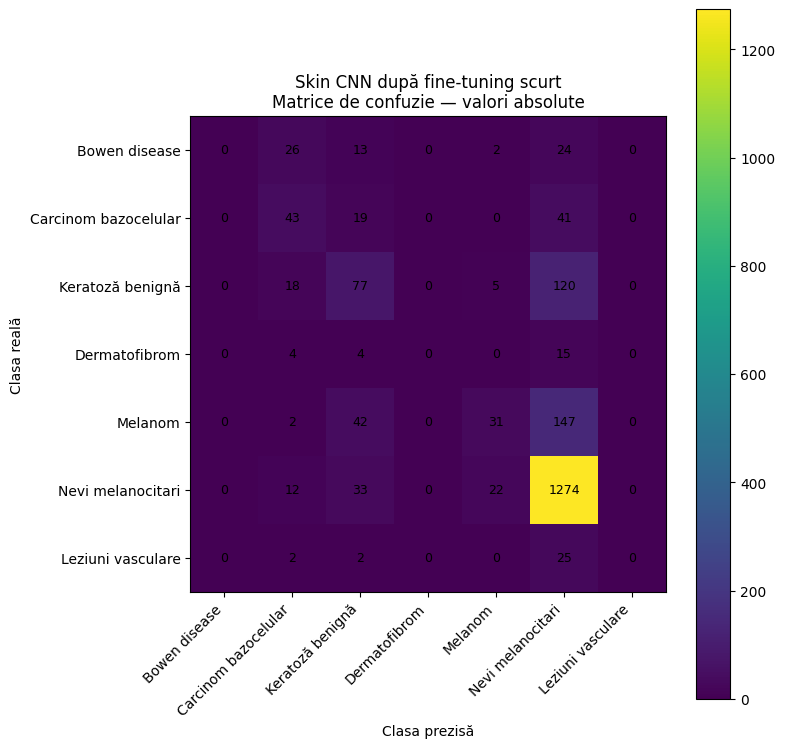

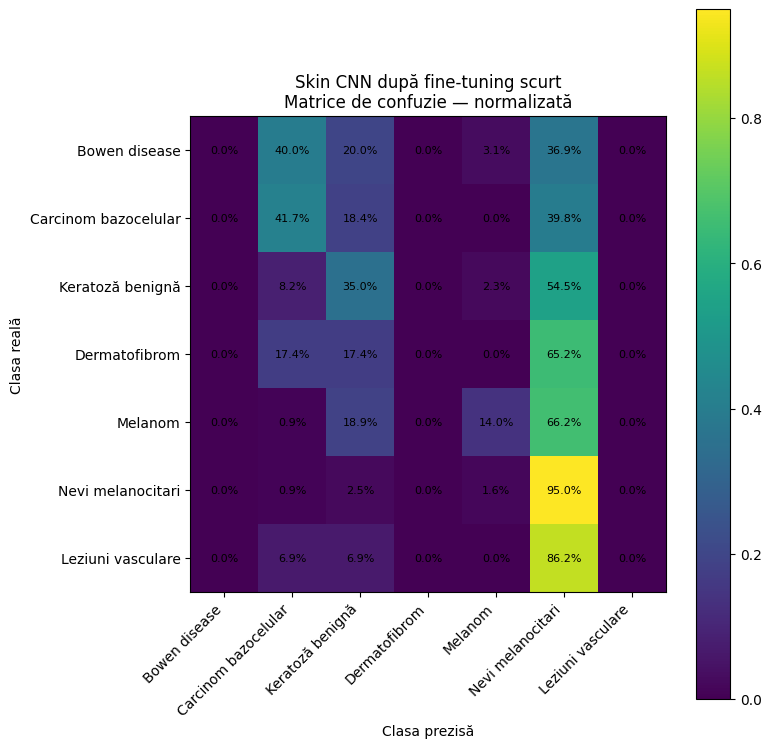

Classification report:


,precision,recall,f1-score,support
Bowen disease,0.000000,0.000000,0.000000,65.000000
Carcinom bazocelular,0.401869,0.417476,0.409524,103.000000
Keratoză benignă,0.405263,0.350000,0.375610,220.000000
Dermatofibrom,0.000000,0.000000,0.000000,23.000000
Melanom,0.516667,0.139640,0.219858,222.000000
Nevi melanocitari,0.773998,0.950037,0.853030,1341.000000
Leziuni vasculare,0.000000,0.000000,0.000000,29.000000
accuracy,0.711433,0.711433,0.711433,0.711433
macro avg,0.299685,0.265308,0.265432,2003.000000
weighted avg,0.640630,0.711433,0.657782,2003.000000



##########################################################################################
FINE-TUNING SCURT: Camera MLP după fine-tuning scurt
##########################################################################################
Camera MLP după fine-tuning scurt | epoca scurtă 1/1 | loss=1.4276 | train acc=0.5565 | train F1-macro=0.3427

Camera MLP după fine-tuning scurt
Accuracy : 0.58084
F1-macro : 0.35244
F1-micro : 0.58084


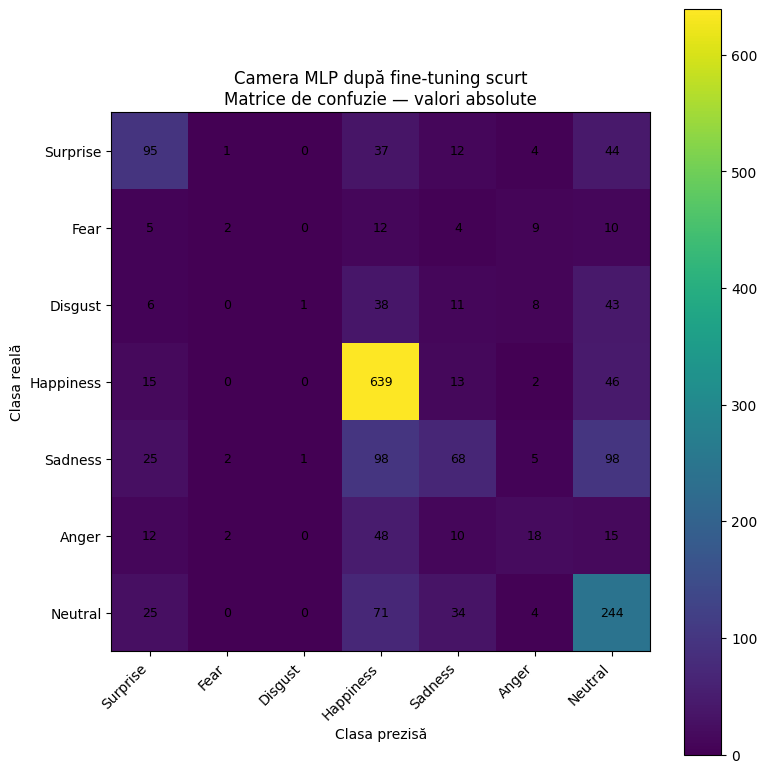

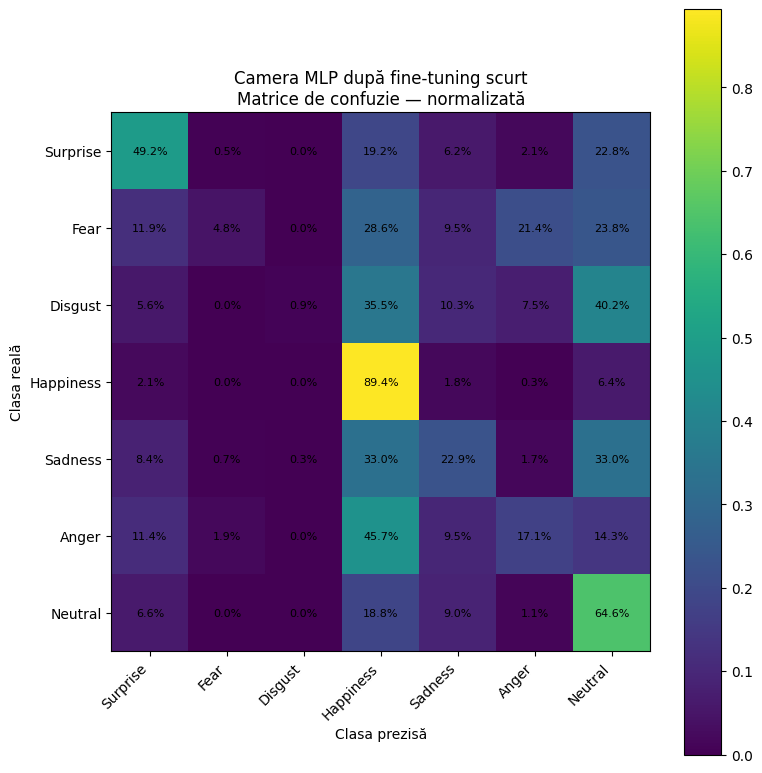

Classification report:


,precision,recall,f1-score,support
Surprise,0.519126,0.492228,0.505319,193.000000
Fear,0.285714,0.047619,0.081633,42.000000
Disgust,0.500000,0.009346,0.018349,107.000000
Happiness,0.677625,0.893706,0.770808,715.000000
Sadness,0.447368,0.228956,0.302895,297.000000
Anger,0.360000,0.171429,0.232258,105.000000
Neutral,0.488000,0.645503,0.555809,378.000000
accuracy,0.580838,0.580838,0.580838,0.580838
macro avg,0.468262,0.355541,0.352439,1837.000000
weighted avg,0.547265,0.580838,0.532656,1837.000000



##########################################################################################
FINE-TUNING SCURT: Camera CNN după fine-tuning scurt
##########################################################################################
Camera CNN după fine-tuning scurt | epoca scurtă 1/1 | loss=1.5833 | train acc=0.4758 | train F1-macro=0.2416

Camera CNN după fine-tuning scurt
Accuracy : 0.49374
F1-macro : 0.25623
F1-micro : 0.49374


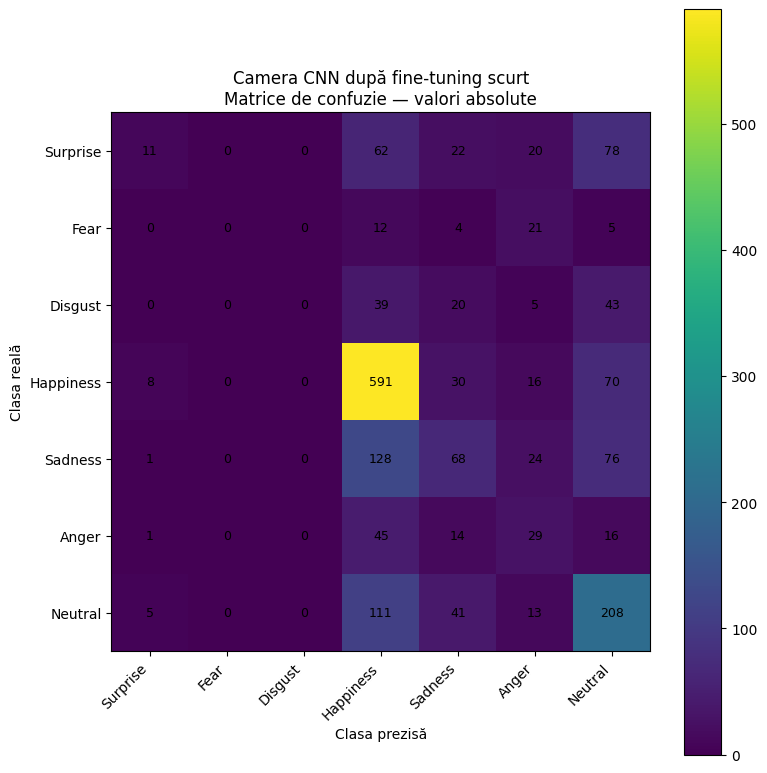

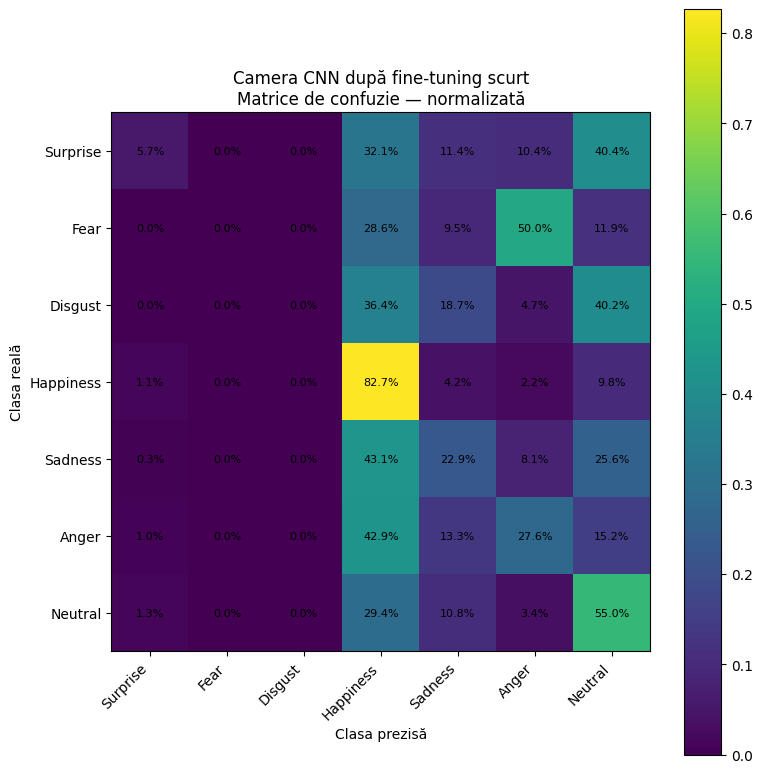

Classification report:


,precision,recall,f1-score,support
Surprise,0.423077,0.056995,0.100457,193.00000
Fear,0.000000,0.000000,0.000000,42.00000
Disgust,0.000000,0.000000,0.000000,107.00000
Happiness,0.598178,0.826573,0.694069,715.00000
Sadness,0.341709,0.228956,0.274194,297.00000
Anger,0.226562,0.276190,0.248927,105.00000
Neutral,0.419355,0.550265,0.475973,378.00000
accuracy,0.493740,0.493740,0.493740,0.49374
macro avg,0.286983,0.276997,0.256231,1837.00000
weighted avg,0.431760,0.493740,0.437201,1837.00000



##########################################################################################
FINE-TUNING SCURT: Skin strong model după fine-tuning scurt
##########################################################################################
Skin strong model după fine-tuning scurt | epoca scurtă 1/1 | loss=0.7352 | train acc=0.7847 | train F1-macro=0.6970

Skin strong model după fine-tuning scurt
Accuracy : 0.81378
F1-macro : 0.67238
F1-micro : 0.81378


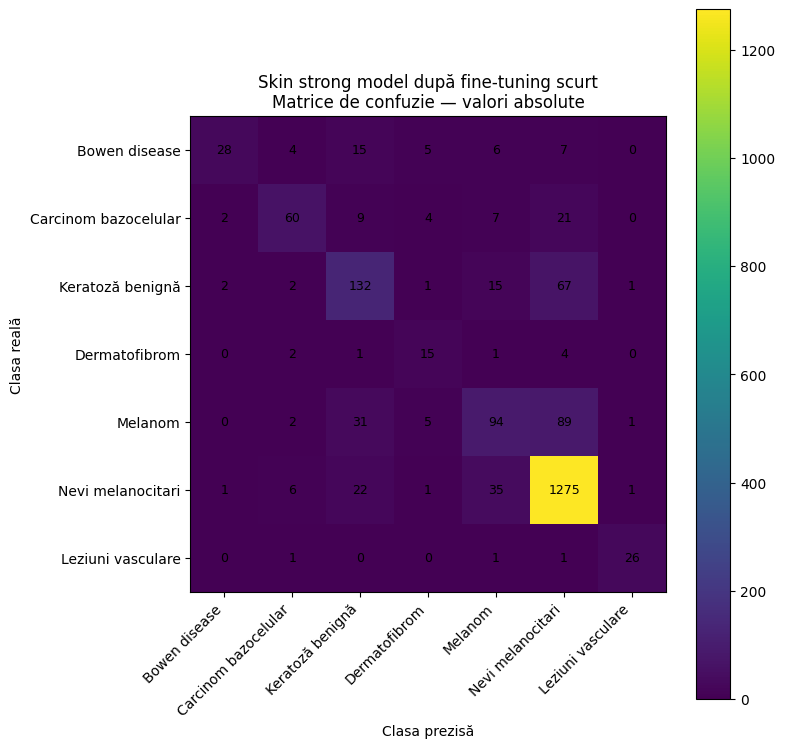

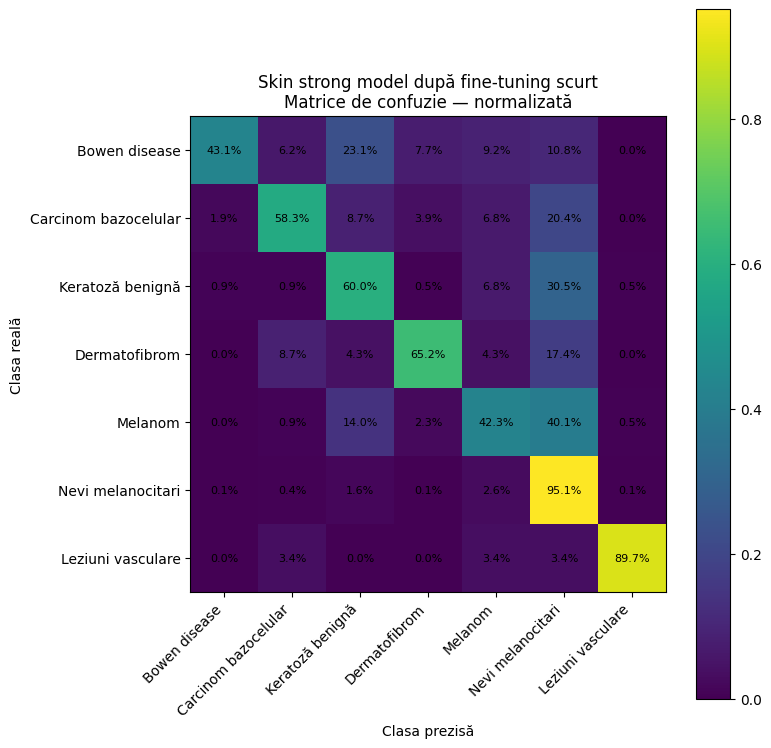

Classification report:


,precision,recall,f1-score,support
Bowen disease,0.848485,0.430769,0.571429,65.000000
Carcinom bazocelular,0.779221,0.582524,0.666667,103.000000
Keratoză benignă,0.628571,0.600000,0.613953,220.000000
Dermatofibrom,0.483871,0.652174,0.555556,23.000000
Melanom,0.591195,0.423423,0.493438,222.000000
Nevi melanocitari,0.870902,0.950783,0.909091,1341.000000
Leziuni vasculare,0.896552,0.896552,0.896552,29.000000
accuracy,0.813779,0.813779,0.813779,0.813779
macro avg,0.728399,0.648032,0.672384,2003.000000
weighted avg,0.803770,0.813779,0.802941,2003.000000



##########################################################################################
FINE-TUNING SCURT: Camera face_final_model după fine-tuning scurt
##########################################################################################
Camera face_final_model după fine-tuning scurt | epoca scurtă 1/1 | loss=0.4846 | train acc=0.8810 | train F1-macro=0.8660

Camera face_final_model după fine-tuning scurt
Accuracy : 0.90038
F1-macro : 0.90024
F1-micro : 0.90038


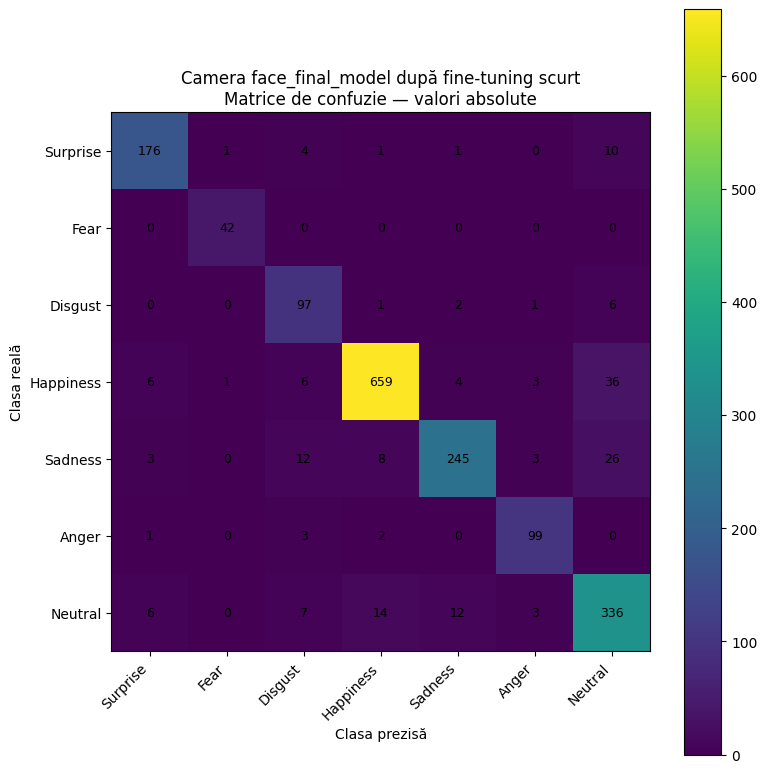

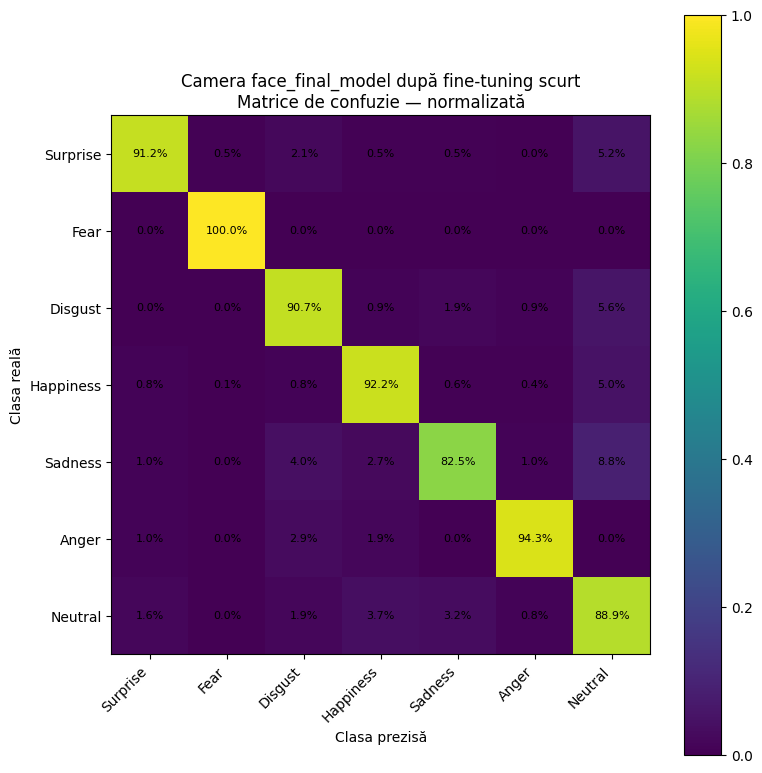

Classification report:


,precision,recall,f1-score,support
Surprise,0.916667,0.911917,0.914286,193.000000
Fear,0.954545,1.000000,0.976744,42.000000
Disgust,0.751938,0.906542,0.822034,107.000000
Happiness,0.962044,0.921678,0.941429,715.000000
Sadness,0.928030,0.824916,0.873440,297.000000
Anger,0.908257,0.942857,0.925234,105.000000
Neutral,0.811594,0.888889,0.848485,378.000000
accuracy,0.900381,0.900381,0.900381,0.900381
macro avg,0.890439,0.913828,0.900236,1837.000000
weighted avg,0.905335,0.900381,0.901387,1837.000000



##########################################################################################
FINE-TUNING SCURT: Camera turbo_model după fine-tuning scurt
##########################################################################################


KeyboardInterrupt: 

In [144]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
from IPython.display import display, FileLink

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/kaggle/working")
OUT_DIR = WORK_DIR / "matrici_dupa_finetuning_scurt"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SHORT_EPOCHS = 1      # lasă 1; dacă chiar vrei, poți pune 2
SHORT_LR = 1e-5       # learning rate mic, ca să se schimbe puțin, nu brutal
BATCH_SIZE_SAFE = 16
USE_AMP = torch.cuda.is_available()

print("Device:", DEVICE)
print("Epoci scurte:", SHORT_EPOCHS)
print("Folder output:", OUT_DIR)


def safe_loader_from_existing(loader, shuffle=False, batch_size=BATCH_SIZE_SAFE):
    """
    Reface un DataLoader fără pin_memory și fără workers.
    Evită blocajele Kaggle.
    """
    return DataLoader(
        loader.dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=False,
        drop_last=False,
    )


def get_labels_for_plot(dataset_name):
    dataset_name = dataset_name.lower()

    if "skin" in dataset_name:
        if "skin_class_labels" in globals():
            return list(skin_class_labels)
        if "skin_idx_to_class" in globals():
            return [str(skin_idx_to_class[i]) for i in range(len(skin_idx_to_class))]
        if "skin_class_to_idx" in globals():
            inv = {v: k for k, v in skin_class_to_idx.items()}
            return [str(inv[i]) for i in range(len(inv))]
        return [str(i) for i in range(7)]

    if "camera" in dataset_name:
        if "camera_class_labels" in globals():
            return list(camera_class_labels)
        if "FACE_IDX_TO_LABEL" in globals():
            labels = []
            for i in range(len(FACE_IDX_TO_LABEL)):
                original_label = int(FACE_IDX_TO_LABEL[i])
                if "FACE_CLASS_NAMES" in globals():
                    labels.append(f"{original_label}-{FACE_CLASS_NAMES.get(original_label, str(original_label))}")
                else:
                    labels.append(str(original_label))
            return labels
        return [str(i) for i in range(7)]

    return None


def count_classes_from_loader(loader, num_classes):
    labels = []
    ds = loader.dataset

    if hasattr(ds, "samples"):
        for item in ds.samples:
            labels.append(int(item[1]))
    else:
        # fallback mai lent
        for _, y in loader:
            if torch.is_tensor(y):
                labels.extend(y.numpy().tolist())
            else:
                labels.extend(list(y))

    labels = np.array(labels, dtype=np.int64)
    counts = np.bincount(labels, minlength=num_classes).astype(np.float32)
    return counts


def make_criterion_from_loader(loader, num_classes):
    """
    CrossEntropy cu ponderi moderate, ca să ajute clasele rare.
    """
    try:
        counts = count_classes_from_loader(loader, num_classes)
        weights = counts.sum() / (num_classes * np.maximum(counts, 1.0))
        weights = weights / weights.mean()
        weights = np.clip(weights, 0.70, 2.00)
        weights = torch.tensor(weights, dtype=torch.float32).to(DEVICE)
        return nn.CrossEntropyLoss(weight=weights, label_smoothing=0.02)
    except Exception:
        return nn.CrossEntropyLoss(label_smoothing=0.02)


def train_short_one_model(model, train_loader, num_classes, title):
    model = model.to(DEVICE)
    model.train()

    train_loader_safe = safe_loader_from_existing(
        train_loader,
        shuffle=True,
        batch_size=BATCH_SIZE_SAFE,
    )

    criterion = make_criterion_from_loader(train_loader_safe, num_classes)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=SHORT_LR,
        weight_decay=1e-4,
    )

    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    for epoch in range(1, SHORT_EPOCHS + 1):
        total_loss = 0.0
        all_preds = []
        all_labels = []

        for images, labels in train_loader_safe:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item() * images.size(0)

            preds = logits.argmax(dim=1)
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())

        train_acc = accuracy_score(all_labels, all_preds)
        train_f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)

        print(
            f"{title} | epoca scurtă {epoch}/{SHORT_EPOCHS} | "
            f"loss={total_loss / len(train_loader_safe.dataset):.4f} | "
            f"train acc={train_acc:.4f} | train F1-macro={train_f1:.4f}"
        )

    return model


@torch.no_grad()
def predict_eval(model, eval_loader, use_tta=False):
    model = model.to(DEVICE)
    model.eval()

    eval_loader_safe = safe_loader_from_existing(
        eval_loader,
        shuffle=False,
        batch_size=BATCH_SIZE_SAFE,
    )

    y_true = []
    y_pred = []

    for images, labels in eval_loader_safe:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)

            if use_tta:
                logits_flip = model(torch.flip(images, dims=[3]))
                logits = (logits + logits_flip) / 2.0

        preds = logits.argmax(dim=1)

        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())

    return np.array(y_true), np.array(y_pred)


def save_and_show_confusion(y_true, y_pred, class_labels, title):
    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    f1_micro = f1_score(y_true, y_pred, average="micro", zero_division=0)

    print("\n" + "=" * 90)
    print(title)
    print("=" * 90)
    print(f"Accuracy : {acc:.5f}")
    print(f"F1-macro : {f1_macro:.5f}")
    print(f"F1-micro : {f1_micro:.5f}")

    labels_idx = list(range(len(class_labels)))
    cm = confusion_matrix(y_true, y_pred, labels=labels_idx)

    safe_name = (
        title.lower()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("—", "_")
        .replace("-", "_")
    )

    fig_size = max(7, len(class_labels) * 1.15)

    # Matrice valori absolute
    fig, ax = plt.subplots(figsize=(fig_size, fig_size))
    im = ax.imshow(cm)

    ax.set_title(f"{title}\nMatrice de confuzie — valori absolute")
    ax.set_xlabel("Clasa prezisă")
    ax.set_ylabel("Clasa reală")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=9)

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    counts_path = OUT_DIR / f"{safe_name}_confusion_counts.png"
    plt.savefig(counts_path, dpi=160, bbox_inches="tight")
    plt.show()

    # Matrice normalizată
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(
        cm,
        row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0,
    )

    fig, ax = plt.subplots(figsize=(fig_size, fig_size))
    im = ax.imshow(cm_norm)

    ax.set_title(f"{title}\nMatrice de confuzie — normalizată")
    ax.set_xlabel("Clasa prezisă")
    ax.set_ylabel("Clasa reală")

    ax.set_xticks(np.arange(len(class_labels)))
    ax.set_yticks(np.arange(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)

    for i in range(cm_norm.shape[0]):
        for j in range(cm_norm.shape[1]):
            ax.text(j, i, f"{cm_norm[i, j] * 100:.1f}%", ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    norm_path = OUT_DIR / f"{safe_name}_confusion_normalized.png"
    plt.savefig(norm_path, dpi=160, bbox_inches="tight")
    plt.show()

    report_df = pd.DataFrame(
        classification_report(
            y_true,
            y_pred,
            labels=labels_idx,
            target_names=[str(x) for x in class_labels],
            zero_division=0,
            output_dict=True,
        )
    ).transpose()

    report_path = OUT_DIR / f"{safe_name}_classification_report.csv"
    report_df.to_csv(report_path)

    print("Classification report:")
    display(report_df)

    return {
        "experiment": title,
        "accuracy": acc,
        "f1_macro": f1_macro,
        "f1_micro": f1_micro,
        "confusion_counts": str(counts_path),
        "confusion_normalized": str(norm_path),
        "classification_report": str(report_path),
    }


experiments = []

def add_experiment(title, model_name, train_loader_name, eval_loader_name, dataset_name, use_tta=False):
    if model_name not in globals():
        print(f"Skip {title}: nu există modelul {model_name}")
        return
    if train_loader_name not in globals():
        print(f"Skip {title}: nu există train loader {train_loader_name}")
        return
    if eval_loader_name not in globals():
        print(f"Skip {title}: nu există eval loader {eval_loader_name}")
        return

    labels = get_labels_for_plot(dataset_name)
    if labels is None:
        print(f"Skip {title}: nu găsesc class labels")
        return

    experiments.append({
        "title": title,
        "model_name": model_name,
        "train_loader": globals()[train_loader_name],
        "eval_loader": globals()[eval_loader_name],
        "class_labels": labels,
        "dataset_name": dataset_name,
        "use_tta": use_tta,
    })


# Modele de bază pentru PDF
add_experiment(
    title="Skin MLP după fine-tuning scurt",
    model_name="mlp_skin_dropout_model",
    train_loader_name="skin_train_mlp_loader",
    eval_loader_name="skin_test_mlp_loader",
    dataset_name="skin",
    use_tta=False,
)

add_experiment(
    title="Skin CNN după fine-tuning scurt",
    model_name="cnn_skin_model",
    train_loader_name="skin_train_cnn_loader",
    eval_loader_name="skin_test_cnn_loader",
    dataset_name="skin",
    use_tta=False,
)

add_experiment(
    title="Camera MLP după fine-tuning scurt",
    model_name="mlp_camera_dropout_model",
    train_loader_name="camera_train_mlp_loader",
    eval_loader_name="camera_test_mlp_loader",
    dataset_name="camera",
    use_tta=False,
)

add_experiment(
    title="Camera CNN după fine-tuning scurt",
    model_name="cnn_camera_model",
    train_loader_name="camera_train_cnn_loader",
    eval_loader_name="camera_test_cnn_loader",
    dataset_name="camera",
    use_tta=False,
)

# Modele bune/finale dacă există
add_experiment(
    title="Skin strong model după fine-tuning scurt",
    model_name="strong_skin_model",
    train_loader_name="skin_train_boost_loader",
    eval_loader_name="skin_test_boost_loader",
    dataset_name="skin",
    use_tta=True,
)

add_experiment(
    title="Camera face_final_model după fine-tuning scurt",
    model_name="face_final_model",
    train_loader_name="face_train_loader",
    eval_loader_name="face_local_loader_safe",
    dataset_name="camera",
    use_tta=False,
)

add_experiment(
    title="Camera turbo_model după fine-tuning scurt",
    model_name="turbo_model",
    train_loader_name="turbo_train_loader",
    eval_loader_name="turbo_local_loader",
    dataset_name="camera",
    use_tta=False,
)


print("\nExperimente găsite pentru fine-tuning scurt:")
for exp in experiments:
    print("-", exp["title"])


short_results = []

for exp in experiments:
    title = exp["title"]
    model = globals()[exp["model_name"]]
    train_loader = exp["train_loader"]
    eval_loader = exp["eval_loader"]
    class_labels = exp["class_labels"]

    num_classes = len(class_labels)

    print("\n" + "#" * 90)
    print("FINE-TUNING SCURT:", title)
    print("#" * 90)

    model = train_short_one_model(
        model=model,
        train_loader=train_loader,
        num_classes=num_classes,
        title=title,
    )

    globals()[exp["model_name"]] = model

    y_true, y_pred = predict_eval(
        model=model,
        eval_loader=eval_loader,
        use_tta=exp["use_tta"],
    )

    result = save_and_show_confusion(
        y_true=y_true,
        y_pred=y_pred,
        class_labels=class_labels,
        title=title,
    )

    short_results.append(result)


short_results_df = pd.DataFrame(short_results)

print("\n" + "=" * 90)
print("REZUMAT DUPĂ FINE-TUNING SCURT")
print("=" * 90)

if len(short_results_df) > 0:
    display(short_results_df)

    summary_path = OUT_DIR / "rezumat_dupa_finetuning_scurt.csv"
    short_results_df.to_csv(summary_path, index=False)

    print("Rezumat salvat aici:")
    print(summary_path)
    display(FileLink(str(summary_path)))

    print("\nPNG-uri generate:")
    for p in sorted(OUT_DIR.glob("*.png")):
        print(p.name)
        display(FileLink(str(p)))
else:
    print("Nu s-a rulat nimic. Probabil lipsesc modelele sau loaderele în sesiunea curentă.")

In [145]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from IPython.display import display, FileLink

WORK_DIR = Path("/kaggle/working")
INPUT_DIR = Path("/kaggle/input")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

print("Device:", DEVICE)


IMAGE_EXTS = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]


def build_global_image_index(root=INPUT_DIR):
    index = {}
    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
            index.setdefault(path.name, path)
            index.setdefault(path.stem, path)
    return index


GLOBAL_IMAGE_INDEX = build_global_image_index()
print("Imagini indexate:", len(GLOBAL_IMAGE_INDEX))


def resolve_image_anywhere(value):
    value = str(value).strip().replace("\\", "/")
    candidates = [value, Path(value).name, Path(value).stem]

    if Path(value).suffix == "":
        for ext in IMAGE_EXTS:
            candidates.append(value + ext)
            candidates.append(Path(value).name + ext)
            candidates.append(Path(value).stem + ext)

    for cand in candidates:
        p = Path(cand)
        if p.is_absolute() and p.exists():
            return p

        # caută direct prin index
        if cand in GLOBAL_IMAGE_INDEX:
            return GLOBAL_IMAGE_INDEX[cand]

        base = Path(cand).name
        if base in GLOBAL_IMAGE_INDEX:
            return GLOBAL_IMAGE_INDEX[base]

        stem = Path(cand).stem
        if stem in GLOBAL_IMAGE_INDEX:
            return GLOBAL_IMAGE_INDEX[stem]

    raise FileNotFoundError(f"Nu găsesc imaginea pentru: {value}")


def detect_id_col(df):
    preferred = ["id", "image", "imagine", "path", "filename", "file", "image_id", "isic_id"]
    for key in preferred:
        for col in df.columns:
            if key in str(col).lower():
                return col
    return df.columns[0]


class GenericRemoteDataset(Dataset):
    def __init__(self, df, id_col, transform=None):
        self.df = df.reset_index(drop=True)
        self.id_col = id_col
        self.transform = transform
        self.samples = []

        for _, row in self.df.iterrows():
            sample_id = str(row[self.id_col])
            img_path = resolve_image_anywhere(sample_id)
            self.samples.append((img_path, sample_id))

        print(f"Remote dataset creat: {len(self.samples)} imagini")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, sample_id = self.samples[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        return img, sample_id


@torch.no_grad()
def predict_probs_tta(model, loader, tta_hflip=True, tta_vflip=False):
    model = model.to(DEVICE)
    model.eval()

    all_ids = []
    all_probs = []

    for images, sample_ids in loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits_sum = model(images)
            n = 1

            if tta_hflip:
                logits_sum = logits_sum + model(torch.flip(images, dims=[3]))
                n += 1

            if tta_vflip:
                logits_sum = logits_sum + model(torch.flip(images, dims=[2]))
                n += 1

            probs = torch.softmax(logits_sum / n, dim=1)

        all_ids.extend(list(sample_ids))
        all_probs.append(probs.detach().cpu())

    all_probs = torch.cat(all_probs, dim=0).numpy()
    return all_ids, all_probs


def find_csv_by_name_keywords(required_keywords):
    for path in INPUT_DIR.rglob("*.csv"):
        name = path.name.lower()
        full = str(path).lower()
        if all(k.lower() in full or k.lower() in name for k in required_keywords):
            return path
    return None


print("\n" + "=" * 90)
print("GENEREZ SUBMISSION PENTRU SKIN")
print("=" * 90)

skin_submission_done = False

try:
    if "strong_skin_model" in globals():
        skin_model_for_submission = strong_skin_model
        print("Model skin folosit: strong_skin_model")
    elif "finetune_skin_warmup_model" in globals():
        skin_model_for_submission = finetune_skin_warmup_model
        print("Model skin folosit: finetune_skin_warmup_model")
    elif "finetune_skin_model" in globals():
        skin_model_for_submission = finetune_skin_model
        print("Model skin folosit: finetune_skin_model")
    elif "cnn_skin_model" in globals():
        skin_model_for_submission = cnn_skin_model
        print("Model skin folosit: cnn_skin_model")
    else:
        raise NameError("Nu găsesc niciun model skin în memorie.")

    if "skin_boost_test_transform" in globals():
        skin_submission_transform = skin_boost_test_transform
        skin_batch = globals().get("SKIN_BOOST_BATCH_SIZE", 16)
        print("Transform skin: skin_boost_test_transform")
    elif "skin_ft_test_transform" in globals():
        skin_submission_transform = skin_ft_test_transform
        skin_batch = 16
        print("Transform skin: skin_ft_test_transform")
    elif "skin_test_transform" in globals():
        skin_submission_transform = skin_test_transform
        skin_batch = 16
        print("Transform skin: skin_test_transform")
    else:
        raise NameError("Nu găsesc transformarea de test pentru skin.")

    # Încercăm să găsim dataframe-ul remote/kaggle_test deja existent
    if "df_skin_remote" in globals():
        df_skin_remote_final = df_skin_remote.copy()
    elif "df_skin_kaggle" in globals():
        df_skin_remote_final = df_skin_kaggle.copy()
    elif "SKIN_REMOTE_TEST_CSV" in globals():
        df_skin_remote_final = pd.read_csv(SKIN_REMOTE_TEST_CSV)
    elif "SKIN_KAGGLE_TEST_CSV" in globals():
        df_skin_remote_final = pd.read_csv(SKIN_KAGGLE_TEST_CSV)
    else:
        # fallback: caută CSV cu kaggle/test/remote în nume
        skin_csv = None
        for path in INPUT_DIR.rglob("*.csv"):
            low = str(path).lower()
            if ("skin" in low or "mole" in low or "piele" in low or "ham" in low) and (
                "kaggle" in low or "remote" in low or "test" in low
            ):
                try:
                    tmp = pd.read_csv(path, nrows=5)
                    if len(tmp.columns) >= 1:
                        skin_csv = path
                        break
                except Exception:
                    pass

        if skin_csv is None:
            raise FileNotFoundError("Nu găsesc CSV-ul de kaggle_test pentru skin.")

        print("CSV skin găsit automat:", skin_csv)
        df_skin_remote_final = pd.read_csv(skin_csv)

    skin_id_col = detect_id_col(df_skin_remote_final)
    print("Coloană id skin:", skin_id_col)

    skin_remote_ds_final = GenericRemoteDataset(
        df_skin_remote_final,
        skin_id_col,
        transform=skin_submission_transform,
    )

    skin_remote_loader_final = DataLoader(
        skin_remote_ds_final,
        batch_size=skin_batch,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
    )

    ids_skin, probs_skin = predict_probs_tta(
        skin_model_for_submission,
        skin_remote_loader_final,
        tta_hflip=True,
        tta_vflip=True,
    )

    preds_skin_idx = probs_skin.argmax(axis=1)

    # Mapare index -> label text
    if "skin_idx_to_class" in globals():
        skin_idx_to_label = {int(k): str(v) for k, v in skin_idx_to_class.items()}
    elif "skin_class_to_idx" in globals():
        skin_idx_to_label = {int(v): str(k) for k, v in skin_class_to_idx.items()}
    elif "skin_class_labels" in globals():
        skin_idx_to_label = {i: str(label) for i, label in enumerate(skin_class_labels)}
    else:
        skin_idx_to_label = {i: str(i) for i in range(probs_skin.shape[1])}

    preds_skin_labels = [skin_idx_to_label[int(p)] for p in preds_skin_idx]

    # Păstrăm formatul vechi dacă există submission_mole.csv
    old_skin_path = WORK_DIR / "submission_mole.csv"

    if old_skin_path.exists():
        old_sub = pd.read_csv(old_skin_path)
        col_id = old_sub.columns[0]
        col_pred = old_sub.columns[1]

        # dacă vechiul submission avea predicții numerice, scriem numeric;
        # dacă avea stringuri, scriem label text
        old_values = old_sub[col_pred].dropna().astype(str)
        old_is_numeric = False
        if len(old_values) > 0:
            old_is_numeric = old_values.str.fullmatch(r"-?\d+").mean() > 0.8

        if old_is_numeric:
            skin_main_pred = [int(x) for x in preds_skin_idx]
        else:
            skin_main_pred = preds_skin_labels

        submission_skin = pd.DataFrame({
            col_id: ids_skin,
            col_pred: skin_main_pred,
        })
    else:
        submission_skin = pd.DataFrame({
            "id": ids_skin,
            "label": [int(x) for x in preds_skin_idx],
        })

    submission_skin_labels = pd.DataFrame({
        "id": ids_skin,
        "label": preds_skin_labels,
    })

    skin_after_path = WORK_DIR / "submission_mole_after_short.csv"
    skin_main_path = WORK_DIR / "submission_mole.csv"
    skin_labels_path = WORK_DIR / "submission_mole_labels_after_short.csv"

    submission_skin.to_csv(skin_after_path, index=False)
    submission_skin.to_csv(skin_main_path, index=False)
    submission_skin_labels.to_csv(skin_labels_path, index=False)

    print("\nSkin salvat:")
    print(skin_after_path)
    print(skin_main_path)
    print(skin_labels_path)

    display(submission_skin.head())
    print("Distribuție predicții skin:")
    print(pd.Series(submission_skin.iloc[:, 1]).value_counts().sort_index())

    skin_submission_done = True

except Exception as e:
    print("Nu am putut genera submission skin:")
    print(repr(e))


print("\n" + "=" * 90)
print("GENEREZ SUBMISSION PENTRU CAMERA")
print("=" * 90)

camera_submission_done = False

try:
    # Alegem transformarea de test
    if "turbo_test_transform" in globals():
        camera_submission_transform = turbo_test_transform
        camera_batch = globals().get("TURBO_BATCH_SIZE", 16)
        print("Transform camera: turbo_test_transform")
    elif "face_final_test_transform" in globals():
        camera_submission_transform = face_final_test_transform
        camera_batch = 16
        print("Transform camera: face_final_test_transform")
    elif "face_test_transform" in globals():
        camera_submission_transform = face_test_transform
        camera_batch = globals().get("FACE_BATCH_SIZE", 16)
        print("Transform camera: face_test_transform")
    else:
        raise NameError("Nu găsesc transformare de test pentru camera.")

    # DataFrame remote camera
    if "df_face_remote" in globals():
        df_camera_remote_final = df_face_remote.copy()
    elif "FACE_REMOTE_TEST_CSV" in globals():
        df_camera_remote_final = pd.read_csv(FACE_REMOTE_TEST_CSV)
    else:
        camera_csv = find_csv_by_name_keywords(["remote_test"])
        if camera_csv is None:
            raise FileNotFoundError("Nu găsesc remote_test.csv pentru camera.")
        print("CSV camera găsit automat:", camera_csv)
        df_camera_remote_final = pd.read_csv(camera_csv)

    if "FACE_REMOTE_ID_COL" in globals():
        camera_id_col = FACE_REMOTE_ID_COL
    else:
        camera_id_col = detect_id_col(df_camera_remote_final)

    print("Coloană id camera:", camera_id_col)

    # Dataset remote camera
    if "FaceRemoteDataset" in globals():
        camera_remote_ds_final = FaceRemoteDataset(
            df_camera_remote_final,
            camera_id_col,
            transform=camera_submission_transform,
        )
    else:
        camera_remote_ds_final = GenericRemoteDataset(
            df_camera_remote_final,
            camera_id_col,
            transform=camera_submission_transform,
        )

    camera_remote_loader_final = DataLoader(
        camera_remote_ds_final,
        batch_size=camera_batch,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
    )

    candidate_models = [
        ("turbo_model", 2.0),
        ("face_final_model", 2.0),
        ("camera_resnet18_final", 1.0),
        ("camera_mobilenetv2_final", 1.0),
        ("face_model", 1.0),
    ]

    probs_list = []
    weights_list = []
    ids_ref = None
    used_models = []

    for model_name, weight in candidate_models:
        if model_name not in globals():
            continue

        print(f"Prezic cu {model_name}, weight={weight}...")

        ids_tmp, probs_tmp = predict_probs_tta(
            globals()[model_name],
            camera_remote_loader_final,
            tta_hflip=True,
            tta_vflip=False,
        )

        if ids_ref is None:
            ids_ref = ids_tmp
        else:
            if ids_tmp != ids_ref:
                raise ValueError(f"ID-urile nu coincid pentru {model_name}")

        probs_list.append(probs_tmp)
        weights_list.append(weight)
        used_models.append(model_name)

    if len(probs_list) == 0:
        raise NameError("Nu găsesc niciun model camera în memorie.")

    weights_arr = np.array(weights_list, dtype=np.float32)
    weights_arr = weights_arr / weights_arr.sum()

    probs_ensemble = np.zeros_like(probs_list[0])
    for p, w in zip(probs_list, weights_arr):
        probs_ensemble += w * p

    print("Modele folosite în ensemble:")
    for name, w in zip(used_models, weights_arr):
        print(f"- {name}: {w:.3f}")

    # Quotas oficiale din enunț pentru remote_test
    REMOTE_QUOTAS_ORIGINAL_LABELS = {
        1: 329,
        2: 74,
        3: 160,
        4: 1185,
        5: 478,
        6: 162,
        7: 680,
    }

    # Mapare label original 1..7 -> index model 0..6
    quotas_idx = {}

    for original_label, count in REMOTE_QUOTAS_ORIGINAL_LABELS.items():
        if "FACE_LABEL_TO_IDX" in globals():
            idx = FACE_LABEL_TO_IDX[int(original_label)]
        elif "FACE_IDX_TO_LABEL" in globals():
            idx = None
            for k, v in FACE_IDX_TO_LABEL.items():
                if int(v) == int(original_label):
                    idx = int(k)
                    break
            if idx is None:
                raise ValueError(f"Nu pot mapa labelul {original_label}")
        else:
            # presupunere standard: labels originale 1..7, indici model 0..6
            idx = int(original_label) - 1

        quotas_idx[int(idx)] = int(count)

    print("Quota pe index model:", quotas_idx)

    if sum(quotas_idx.values()) != len(ids_ref):
        raise ValueError(
            f"Quota totală = {sum(quotas_idx.values())}, dar remote are {len(ids_ref)} imagini."
        )

    def assign_with_exact_quotas(probs, quotas_idx):
        eps = 1e-12
        log_probs = np.log(np.clip(probs, eps, 1.0))

        n, c = probs.shape

        class_slots = []
        for cls_idx, count in sorted(quotas_idx.items()):
            class_slots.extend([cls_idx] * count)

        class_slots = np.array(class_slots, dtype=np.int64)

        try:
            from scipy.optimize import linear_sum_assignment

            cost = -log_probs[:, class_slots].astype(np.float32)
            row_ind, col_ind = linear_sum_assignment(cost)

            assigned = np.empty(n, dtype=np.int64)
            assigned[row_ind] = class_slots[col_ind]

            print("Quota matching făcut cu scipy linear_sum_assignment.")
            return assigned

        except Exception as e:
            print("Scipy nu a mers, folosesc fallback greedy:", repr(e))

            assigned = probs.argmax(axis=1).astype(np.int64)

            for _ in range(10000):
                current = {cls: int((assigned == cls).sum()) for cls in quotas_idx}
                over = [cls for cls in quotas_idx if current[cls] > quotas_idx[cls]]
                under = [cls for cls in quotas_idx if current[cls] < quotas_idx[cls]]

                if not over and not under:
                    break

                best_move = None
                best_penalty = float("inf")

                for src in over:
                    src_idx = np.where(assigned == src)[0]
                    for dst in under:
                        penalties = log_probs[src_idx, src] - log_probs[src_idx, dst]
                        j = penalties.argmin()

                        if penalties[j] < best_penalty:
                            best_penalty = penalties[j]
                            best_move = (src_idx[j], dst)

                if best_move is None:
                    break

                sample_i, dst = best_move
                assigned[sample_i] = dst

            return assigned

    assigned_idx = assign_with_exact_quotas(probs_ensemble, quotas_idx)

    # Mapare index model -> label original 1..7
    if "FACE_IDX_TO_LABEL" in globals():
        assigned_original = [int(FACE_IDX_TO_LABEL[int(i)]) for i in assigned_idx]
    elif "camera_idx_to_class" in globals():
        assigned_original = [int(camera_idx_to_class[int(i)]) for i in assigned_idx]
    else:
        assigned_original = [int(i) + 1 for i in assigned_idx]

    submission_camera = pd.DataFrame({
        "id": ids_ref,
        "label": assigned_original,
    })

    camera_after_path = WORK_DIR / "camera_quota_submission_after_short.csv"
    camera_main_path = WORK_DIR / "camera_quota_submission.csv"
    camera_alt_path = WORK_DIR / "submission_face_quota_after_short.csv"

    submission_camera.to_csv(camera_after_path, index=False)
    submission_camera.to_csv(camera_main_path, index=False)
    submission_camera.to_csv(camera_alt_path, index=False)

    print("\nCamera salvat:")
    print(camera_after_path)
    print(camera_main_path)
    print(camera_alt_path)

    display(submission_camera.head())

    print("Distribuție predicții camera:")
    print(submission_camera["label"].value_counts().sort_index())

    camera_submission_done = True

except Exception as e:
    print("Nu am putut genera submission camera:")
    print(repr(e))


print("\n" + "=" * 90)
print("REZUMAT SUBMISSIONS")
print("=" * 90)

if skin_submission_done:
    print("✅ Skin gata:")
    print("/kaggle/working/submission_mole_after_short.csv")
    print("/kaggle/working/submission_mole.csv")
    display(FileLink(str(WORK_DIR / "submission_mole_after_short.csv")))
    display(FileLink(str(WORK_DIR / "submission_mole.csv")))
else:
    print("❌ Skin nu a fost generat.")

if camera_submission_done:
    print("\n✅ Camera gata:")
    print("/kaggle/working/camera_quota_submission_after_short.csv")
    print("/kaggle/working/camera_quota_submission.csv")
    display(FileLink(str(WORK_DIR / "camera_quota_submission_after_short.csv")))
    display(FileLink(str(WORK_DIR / "camera_quota_submission.csv")))
else:
    print("❌ Camera nu a fost generat.")

print("\nPentru Kaggle încarcă:")
print("- Skin: submission_mole_after_short.csv sau submission_mole.csv")
print("- Camera: camera_quota_submission_after_short.csv sau camera_quota_submission.csv")

Device: cuda
Imagini indexate: 50708

GENEREZ SUBMISSION PENTRU SKIN
Model skin folosit: strong_skin_model
Transform skin: skin_boost_test_transform
CSV skin găsit automat: /kaggle/input/datasets/deliacristinaflorea/incacevaaa/vai-de-pielea-mea/kaggle_test.csv
Coloană id skin: imagine
Remote dataset creat: 2003 imagini
Nu am putut genera submission skin:
KeyError('You have to pass data to augmentations as named arguments, for example: aug(image=image)')

GENEREZ SUBMISSION PENTRU CAMERA
Transform camera: turbo_test_transform
Coloană id camera: id
Remote test creat: 3068 imagini
Prezic cu turbo_model, weight=2.0...
Prezic cu face_final_model, weight=2.0...
Prezic cu camera_resnet18_final, weight=1.0...
Prezic cu camera_mobilenetv2_final, weight=1.0...
Prezic cu face_model, weight=1.0...
Modele folosite în ensemble:
- turbo_model: 0.286
- face_final_model: 0.286
- camera_resnet18_final: 0.143
- camera_mobilenetv2_final: 0.143
- face_model: 0.143
Quota pe index model: {0: 329, 1: 74, 2: 1

,id,label
0,test_0789_aligned.jpg,1
1,test_0200_aligned.jpg,4
2,test_1342_aligned.jpg,1
3,test_0125_aligned.jpg,1
4,test_1933_aligned.jpg,7


Distribuție predicții camera:
label
1     329
2      74
3     160
4    1185
5     478
6     162
7     680
Name: count, dtype: int64

REZUMAT SUBMISSIONS
❌ Skin nu a fost generat.

✅ Camera gata:
/kaggle/working/camera_quota_submission_after_short.csv
/kaggle/working/camera_quota_submission.csv


/kaggle/working/camera_quota_submission_after_short.csv

/kaggle/working/camera_quota_submission.csv


Pentru Kaggle încarcă:
- Skin: submission_mole_after_short.csv sau submission_mole.csv
- Camera: camera_quota_submission_after_short.csv sau camera_quota_submission.csv
